# Dysarthria V9: confound-controlled, physical-speaker-independent research

**Question.** Does dysarthria discrimination remain after controlling major measurable recording, silence, duration, amplitude and evidence-budget confounds? V8 is a frozen historical benchmark. V9 writes only to `outputs/cache/dysarthria_detection_v9/` and `v9_publication/`.

**Interpretation guard.** Five seeds repeat partitions and training of the **same cohort**, not independent cohorts. UASpeech is a historically examined corpus, so its V9 evaluation is a **locked cross-corpus benchmark evaluation**, not prospective external validation. No UASpeech label enters primary V9 development. A lower V9 score can still be scientifically informative.

All analysis code is contained in this notebook. Execute the cells in order in the project's `.venv` kernel; raw TORGO/UASpeech audio, frozen V8 reference weights, and Python packages are required to recompute results. Every costly stage uses a V9-only cache. Existing compatible shards resume; signature mismatches stop. The last audit reports incomplete work without inventing results.

## Notebook setup and complete implementation

The next eight code cells contain the full V9 pipeline: provenance, waveform/VAD preparation, evaluation, model training, feature extraction, external evaluation, analysis, and reporting. The notebook imports installed libraries only. Paths refer to the project datasets and cached research artifacts.

In [1]:
from pathlib import Path
project = Path.cwd().resolve()
if (project / 'v9' / 'dysarthria_v9.ipynb').is_file():
    pass
elif (project.parent / 'v9' / 'dysarthria_v9.ipynb').is_file():
    project = project.parent
else:
    raise FileNotFoundError('Start Jupyter from the project root or v9/ with the research datasets present')
from IPython.display import display
print('Project:', project)


Project: /Users/Noor/Documents/projects/dysarthia


### Implementation: reference

In [2]:
"""Create and verify a read-only lineage record for the completed V8 study."""
from __future__ import annotations

import csv
import hashlib
import json
from pathlib import Path


ROOT = project
V8 = ROOT / "v8"
FROZEN = V8 / "v8_publication_completion" / "frozen_reference"
OUTPUT = project / "v9" / "reference_v8_manifest.json"


def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def reference_manifest() -> dict:
    run = json.loads((FROZEN / "run" / "run_manifest.json").read_text())
    snapshot = json.loads((FROZEN / "snapshot_manifest.json").read_text())
    checkpoints = list(csv.DictReader((FROZEN / "checkpoint_hashes.csv").open()))
    thresholds = list(csv.DictReader((FROZEN / "locked_thresholds.csv").open()))
    result_root = V8 / "v8_publication_completion" / "results"
    publication = V8 / "v8_publication_completion" / "publication"
    refs = {
        "v8_notebook_current": V8 / "dysarthria_v8.ipynb",
        "v8_notebook_frozen": FROZEN / "source" / "dysarthria_v8.ipynb",
        "v8_snapshot_manifest": FROZEN / "snapshot_manifest.json",
        "v8_torgo_predictions": result_root / "primary_torgo" / "predictions.csv",
        "v8_uaspeech_predictions": result_root / "primary_uaspeech_m3" / "predictions.csv",
        "v8_publication_audit": publication / "publication_audit.json",
        "v8_publication_traceability": publication / "traceability_manifest.json",
        "v8_duration_baseline": result_root / "duration" / "predictions.csv",
        "v8_artifact_baseline": result_root / "artifact" / "predictions.csv",
        "v8_silence_baseline": result_root / "silence" / "predictions.csv",
    }
    for name, path in refs.items():
        if not path.is_file():
            raise FileNotFoundError(f"Missing frozen V8 reference: {name}: {path}")
    pretrained = next(x for x in snapshot["files"] if x["path"].endswith("wavlm_base.pth"))
    models = [x for x in checkpoints if x["path"].startswith("run/deployment/speech_only/")
              and x["path"].endswith("/final/best.pt")]
    if len(models) != 5:
        raise RuntimeError(f"Expected five V8 deployment checkpoints, found {len(models)}")
    for model in models:
        path = FROZEN / model["path"]
        if not path.is_file() or sha256(path) != model["sha256"]:
            raise RuntimeError(f"Frozen V8 checkpoint changed: {path}")
    weight_path = FROZEN / pretrained["path"]
    if not weight_path.is_file() or sha256(weight_path) != pretrained["sha256"]:
        raise RuntimeError("Frozen V8 WavLM weight changed")
    return {
        "schema_version": 1,
        "description": "V8 historical frozen benchmark. Hashes and paths only; no V8 file is rewritten.",
        "v8_pipeline_signature": run["pipeline_signature"],
        "v8_run_signature": run["run_signature"],
        "v8_wavlm_weight_sha256": run["pretrained_weight_sha256"],
        "v8_wavlm_weight_snapshot_sha256": pretrained["sha256"],
        "v8_five_seed_deployment_checkpoints": models,
        "v8_thresholds": thresholds,
        "references": {name: {"path": str(path), "sha256": sha256(path)} for name, path in refs.items()},
    }


def write_reference() -> dict:
    data = reference_manifest()
    OUTPUT.parent.mkdir(parents=True, exist_ok=True)
    if OUTPUT.exists():
        old = json.loads(OUTPUT.read_text())
        if old != data:
            raise RuntimeError("V8 reference changed after V9 manifest was frozen")
    else:
        OUTPUT.write_text(json.dumps(data, indent=2, sort_keys=True) + "\n")
    return data

### Implementation: core

In [3]:
"""Deterministic waveform processing and speaker-safe V9 data preparation."""
from __future__ import annotations

import hashlib
import json
import math
import os
import platform
import tempfile
from dataclasses import asdict, dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import soundfile as sf
from scipy.signal import resample_poly
from sklearn.model_selection import StratifiedKFold



SIGNATURE = "v9_energy_vad_active_concat_rms_fixed_speaker_v1"
OUT = ROOT / "outputs" / "cache" / "dysarthria_detection_v9"
PUB = ROOT / "v9_publication"
V8_RUN = ROOT / "v8" / "v8_publication_completion" / "frozen_reference" / "run"
SEEDS = (42, 43, 44, 45, 46)
CANDIDATE_SECONDS = (1.0, 1.5, 2.0, 3.0)
CANDIDATE_K = (5, 10, 20)


@dataclass(frozen=True)
class VADConfig:
    sample_rate: int = 16_000
    frame_ms: int = 20
    noise_quantile: float = .20
    above_noise_db: float = 10.0
    below_peak_db: float = 35.0
    min_rms_dbfs: float = -52.0
    bridge_ms: int = 60
    pad_ms: int = 20
    target_rms: float = .08
    max_gain: float = 10.0


def signature(value) -> str:
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(",", ":"), default=str).encode()).hexdigest()


def atomic_json(path: Path, value) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile("w", dir=path.parent, delete=False) as handle:
        json.dump(value, handle, indent=2, sort_keys=True, default=str)
        handle.write("\n")
        temporary = Path(handle.name)
    os.replace(temporary, path)


def atomic_csv(path: Path, frame: pd.DataFrame) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile("w", dir=path.parent, suffix=".csv", delete=False) as handle:
        frame.to_csv(handle, index=False)
        temporary = Path(handle.name)
    os.replace(temporary, path)


def assert_v9_path(path: Path) -> None:
    p = path.resolve()
    if not (p.is_relative_to(OUT.resolve()) or p.is_relative_to(PUB.resolve())
            or p.is_relative_to((ROOT / "v9").resolve())):
        raise ValueError(f"V9 write outside dedicated namespace: {p}")
    if p.is_relative_to((ROOT / "v8").resolve()):
        raise ValueError("V8 is frozen")


def load_torgo_inventory() -> pd.DataFrame:
    """Use V8's audited physical-speaker mapping, never V8's features."""
    ref = write_reference()
    path = V8_RUN / "raw_inventory.csv"
    meta = pd.read_csv(path)
    expected = {"F01", "F03", "F04", "M01", "M02", "M03", "M04", "M05",
                "FC01", "FC02", "FC03", "MC01", "MC02", "MC03", "MC04"}
    if set(meta.physical_speaker_id) != expected:
        raise AssertionError("V8 audited TORGO physical speaker roster changed")
    if meta.groupby("physical_speaker_id").label.nunique().max() != 1:
        raise AssertionError("Conflicting physical-speaker labels")
    if not all(Path(p).is_file() for p in meta.file_path):
        raise FileNotFoundError("TORGO source audio missing")
    if ref["v8_run_signature"] != json.loads((V8_RUN / "run_manifest.json").read_text())["run_signature"]:
        raise AssertionError("V8 run signature differs from frozen reference")
    return meta


def read_mono_16k(path: Path, sr: int = 16_000) -> np.ndarray:
    audio, source_sr = sf.read(path, dtype="float32", always_2d=True)
    mono = audio.mean(axis=1)
    if source_sr != sr:
        factor = math.gcd(source_sr, sr)
        mono = resample_poly(mono, sr // factor, source_sr // factor)
    if not np.isfinite(mono).all():
        raise ValueError("Nonfinite waveform")
    return np.asarray(mono, dtype=np.float32)


def vad_active(audio: np.ndarray, config: VADConfig = VADConfig(), *, return_mask: bool = False):
    """Label-independent frame-energy VAD, preserving a three-way silence audit.

    Frame thresholds depend only on this recording's energy distribution and fixed
    constants. Silent frames are removed, and active frames retain chronological order.
    """
    frame = config.sample_rate * config.frame_ms // 1000
    n = len(audio)
    if n == 0:
        audit = {"VAD_status": "empty", "original_duration": 0.0,
            "active_speech_duration": 0.0, "silence_duration": 0.0, "silence_ratio": 1.0,
            "leading_silence_duration": 0.0, "trailing_silence_duration": 0.0,
            "internal_silence_duration": 0.0, "number_active_segments": 0,
            "vad_threshold_rms": 0.0}
        return (np.empty(0, np.float32), audit, np.empty(0, bool)) if return_mask else (np.empty(0, np.float32), audit)
    padded = np.pad(audio, (0, (-n) % frame))
    frames = padded.reshape(-1, frame)
    rms = np.sqrt(np.mean(frames.astype(np.float64) ** 2, axis=1))
    eps = 1e-8
    noise = float(np.quantile(rms, config.noise_quantile))
    peak = float(np.max(rms))
    threshold = max(noise * 10 ** (config.above_noise_db / 20),
                    peak * 10 ** (-config.below_peak_db / 20),
                    10 ** (config.min_rms_dbfs / 20))
    mask = rms >= threshold
    # Bridge only short internal pauses; retain all longer pauses in the audit.
    bridge = config.bridge_ms // config.frame_ms
    if mask.any() and bridge:
        indices = np.flatnonzero(mask)
        for left, right in zip(indices[:-1], indices[1:]):
            if 0 < right - left - 1 <= bridge:
                mask[left + 1:right] = True
    pad_frames = config.pad_ms // config.frame_ms
    if pad_frames and mask.any():
        raw = mask.copy()
        for offset in range(1, pad_frames + 1):
            mask[offset:] |= raw[:-offset]
            mask[:-offset] |= raw[offset:]
    active_frames = np.flatnonzero(mask)
    active_chunks = [audio[i * frame:min((i + 1) * frame, n)] for i in active_frames]
    active = np.concatenate(active_chunks) if active_chunks else np.empty(0, np.float32)
    if len(active_frames):
        first, last = int(active_frames[0]), int(active_frames[-1])
        leading = min(first * frame, n) / config.sample_rate
        trailing = max(0, n - min((last + 1) * frame, n)) / config.sample_rate
        segments = 1 + int(np.sum(np.diff(active_frames) > 1))
    else:
        leading, trailing, segments = n / config.sample_rate, 0.0, 0
    original = n / config.sample_rate
    active_seconds = len(active) / config.sample_rate
    silence = original - active_seconds
    internal = max(0.0, silence - leading - trailing)
    audit = {"VAD_status": "ok" if segments else "no_active_speech",
        "original_duration": original, "active_speech_duration": active_seconds,
        "silence_duration": silence, "silence_ratio": silence / original,
        "leading_silence_duration": leading, "trailing_silence_duration": trailing,
        "internal_silence_duration": internal, "number_active_segments": segments,
        "vad_threshold_rms": threshold}
    return (active, audit, mask) if return_mask else (active, audit)


def normalized_center_segment(active: np.ndarray, seconds: float, config: VADConfig) -> tuple[np.ndarray, dict] | None:
    target = round(seconds * config.sample_rate)
    if len(active) < target:
        return None
    start = (len(active) - target) // 2
    segment = np.asarray(active[start:start + target], dtype=np.float32)
    before = float(np.sqrt(np.mean(segment.astype(np.float64) ** 2)))
    if before <= 0:
        return None
    gain = min(config.target_rms / before, config.max_gain)
    normalized = segment * gain
    # Avoid clipping without sample-wise nonlinear distortion.
    peak = float(np.max(np.abs(normalized)))
    if peak > .99:
        normalized *= .99 / peak
    after = float(np.sqrt(np.mean(normalized.astype(np.float64) ** 2)))
    return normalized, {"start_active_frame": start, "end_active_frame": start + target,
        "pre_normalization_rms": before, "post_normalization_rms": after}


def audit_recordings(meta: pd.DataFrame, corpus: str, config: VADConfig = VADConfig(),
                     *, out: Path = OUT) -> pd.DataFrame:
    """Resume per-recording VAD audit; failed recordings remain explicit rows."""
    assert_v9_path(out)
    folder = out / "vad" / corpus
    spec = {"pipeline": SIGNATURE, "vad": asdict(config), "corpus": corpus}
    spec_hash = signature(spec)
    (folder / "shards").mkdir(parents=True, exist_ok=True)
    rows = []
    for index, row in enumerate(meta.itertuples(index=False), 1):
        path = Path(row.file_path)
        stat = path.stat()
        source = {"path": str(path), "size": stat.st_size, "mtime_ns": stat.st_mtime_ns,
                  "source_id": row.source_id}
        source_hash = sha256(path)
        key = signature({"source": source, "source_sha256": source_hash, "spec": spec_hash})
        shard = folder / "shards" / key[:2] / f"{key}.json"
        if shard.exists():
            item = json.loads(shard.read_text())
            if item["cache_key"] != key or item["spec_hash"] != spec_hash:
                raise RuntimeError(f"Incompatible VAD shard: {shard}")
            if item.get("source_sha256") != source_hash:
                raise RuntimeError(f"Raw audio changed without metadata change: {path}")
        else:
            try:
                audio = read_mono_16k(path, config.sample_rate)
                _, measures = vad_active(audio, config)
                item = {"cache_key": key, "spec_hash": spec_hash, "source_sha256": source_hash,
                        **source, "speaker_id": str(row.physical_speaker_id),
                        "label": int(row.label), **measures}
            except Exception as exc:
                item = {"cache_key": key, "spec_hash": spec_hash, **source,
                        "speaker_id": str(row.physical_speaker_id), "label": int(row.label),
                        "VAD_status": "failed", "error": repr(exc)}
            atomic_json(shard, item)
        rows.append(item)
        if index % 2000 == 0:
            print(f"{corpus}: VAD audited {index}/{len(meta)} recordings", flush=True)
    columns = ["cache_key", "spec_hash", "source_sha256", "path", "size", "mtime_ns",
        "source_id", "speaker_id", "label", "VAD_status", "original_duration",
        "active_speech_duration", "silence_duration", "silence_ratio",
        "leading_silence_duration", "trailing_silence_duration",
        "internal_silence_duration", "number_active_segments", "vad_threshold_rms"]
    if any("error" in row for row in rows):
        columns.append("error")
    result = pd.DataFrame(rows, columns=columns)
    atomic_csv(folder / "vad_audit.csv", result)
    atomic_json(folder / "manifest.json", {"spec": spec, "spec_hash": spec_hash,
        "n_recordings": len(result), "n_failed": int(result.VAD_status.eq("failed").sum()),
        "audit_sha256": sha256(folder / "vad_audit.csv")})
    return result


def choose_segment_seconds(vad: pd.DataFrame, *, out: Path = OUT) -> float:
    usable = vad.loc[vad.VAD_status.eq("ok")]
    if len(usable) == 0:
        raise RuntimeError("No usable TORGO recordings for segment coverage")
    coverage = pd.DataFrame([{"seconds": seconds, "usable_recordings": len(usable),
        "covered_recordings": int(usable.active_speech_duration.ge(seconds).sum()),
        "coverage": float(usable.active_speech_duration.ge(seconds).mean()),
        "minimum_eligible_recordings_per_speaker": int(usable.loc[
            usable.active_speech_duration.ge(seconds)].groupby("speaker_id").size().reindex(
                sorted(usable.speaker_id.unique()), fill_value=0).min())}
        for seconds in CANDIDATE_SECONDS])
    atomic_csv(out / "torgo_segment_coverage.csv", coverage)
    print(coverage.to_string(index=False))
    eligible = coverage.loc[coverage.coverage.ge(.90), "seconds"]
    if not eligible.empty:
        seconds = float(eligible.max())
        rule = "largest candidate with >=90% usable TORGO recording coverage"
        fallback = False
    else:
        print("90% recording coverage is unattainable for all candidates; applying the documented cohort-preserving fallback.")
        fallback_rows = coverage.loc[coverage.coverage.ge(.25) &
            coverage.minimum_eligible_recordings_per_speaker.ge(20)]
        if fallback_rows.empty:
            raise RuntimeError("No candidate meets fallback >=25% coverage and >=20 recordings per physical speaker")
        seconds = float(fallback_rows.seconds.max())
        rule = "largest candidate with >=25% recording coverage and >=20 eligible recordings per physical speaker"
        fallback = True
    if seconds not in CANDIDATE_SECONDS:
        raise AssertionError("Invalid segment duration")
    atomic_json(out / "segment_selection.json", {"rule": rule,
        "primary_90_percent_rule_met": not fallback, "fallback_used": fallback,
        "fallback_user_confirmed": True if fallback else None,
        "selected_seconds": seconds, "coverage_sha256": sha256(out / "torgo_segment_coverage.csv")})
    return seconds


def selected_segments(meta: pd.DataFrame, vad: pd.DataFrame, corpus: str, seconds: float,
                      max_k: int = 20, *, out: Path = OUT,
                      config: VADConfig = VADConfig()) -> pd.DataFrame:
    """Select at most 20 fixed windows per speaker by source ID, before labels are used.

    The K=5 and K=10 subsets are prefixes of the K=20 selection. No speaker
    receives duplicated or padded audio. Every selected waveform gets a V9 shard.
    """
    assert_v9_path(out)
    merged = meta.merge(vad[["source_id", "VAD_status", "active_speech_duration", "source_sha256"]],
                        on="source_id", validate="one_to_one")
    eligible = merged.loc[merged.VAD_status.eq("ok") & merged.active_speech_duration.ge(seconds)].copy()
    eligible["selection_order"] = eligible.source_id.map(lambda s: signature([corpus, s, "v9_fixed_budget_v1"]))
    eligible = eligible.sort_values(["physical_speaker_id", "selection_order"])
    chosen = eligible.groupby("physical_speaker_id", sort=True).head(max_k).copy()
    counts = chosen.groupby("physical_speaker_id").size()
    missing = sorted(set(meta.physical_speaker_id) - set(counts.index))
    if missing or any(counts < max_k):
        raise RuntimeError(f"Fixed K={max_k} cannot cover all {corpus} speakers; missing={missing}; counts={counts.to_dict()}")
    spec = {"pipeline": SIGNATURE, "vad": asdict(config), "seconds": seconds,
            "normalization": "post-VAD RMS target 0.08, gain <=10, peak <=0.99",
            "selection": "source ID hash order, max 20 per physical speaker"}
    spec_hash = signature(spec)
    directory = out / "segments" / corpus
    records = []
    for i, row in enumerate(chosen.itertuples(index=False), 1):
        key = signature([row.source_sha256, spec_hash])
        wav_path = directory / "waveforms" / key[:2] / f"{key}.npy"
        if wav_path.exists():
            wave = np.load(wav_path, mmap_mode="r")
            if len(wave) != round(seconds * config.sample_rate):
                raise RuntimeError(f"Incompatible segment cache: {wav_path}")
            metadata_path = wav_path.with_suffix(".json")
            record = json.loads(metadata_path.read_text())
            if record["spec_hash"] != spec_hash or record["source_sha256"] != row.source_sha256:
                raise RuntimeError(f"Incompatible segment metadata: {metadata_path}")
        else:
            audio = read_mono_16k(Path(row.file_path), config.sample_rate)
            active, _ = vad_active(audio, config)
            result = normalized_center_segment(active, seconds, config)
            if result is None:
                raise RuntimeError(f"Previously eligible audio became ineligible: {row.file_path}")
            waveform, detail = result
            wav_path.parent.mkdir(parents=True, exist_ok=True)
            with tempfile.NamedTemporaryFile(dir=wav_path.parent, suffix=".npy", delete=False) as stream:
                np.save(stream, waveform)
                temporary = Path(stream.name)
            os.replace(temporary, wav_path)
            record = {"spec_hash": spec_hash, "source_sha256": row.source_sha256,
                "speaker_id": str(row.physical_speaker_id), "label": int(row.label),
                "source_audio": str(row.file_path), "source_id": row.source_id,
                "segment_index": 0, "active_duration": float(row.active_speech_duration),
                "segment_id": key, "waveform_path": str(wav_path), **detail}
            atomic_json(wav_path.with_suffix(".json"), record)
        records.append(record)
        if i % 100 == 0:
            print(f"{corpus}: materialized {i}/{len(chosen)} selected segments", flush=True)
    columns = ["spec_hash", "source_sha256", "speaker_id", "label", "source_audio",
        "source_id", "segment_index", "active_duration", "segment_id", "waveform_path",
        "start_active_frame", "end_active_frame", "pre_normalization_rms", "post_normalization_rms"]
    selected = pd.DataFrame(records, columns=columns)
    atomic_csv(directory / "selected_segments.csv", selected)
    atomic_json(directory / "manifest.json", {"spec": spec, "spec_hash": spec_hash,
        "selected_sha256": sha256(directory / "selected_segments.csv"),
        "n_speakers": int(selected.speaker_id.nunique()), "n_segments": len(selected)})
    return selected


def split_manifest(segments: pd.DataFrame, seed: int, outer_folds: int = 5,
                   inner_folds: int = 3, *, out: Path = OUT) -> Path:
    """Stratified physical-speaker folds; hard-fail invalid class partitions."""
    speakers = segments.groupby("speaker_id").agg(label=("label", "first"),
        n_segments=("label", "size")).reset_index()
    if segments.groupby("speaker_id").label.nunique().max() != 1:
        raise AssertionError("Conflicting physical-speaker labels")
    def partition(frame, folds, random_state):
        if frame.label.value_counts().min() < folds:
            raise RuntimeError(f"Insufficient physical speakers per class for {folds} folds")
        splitter = StratifiedKFold(n_splits=folds, shuffle=True, random_state=random_state)
        return splitter.split(frame, frame.label)
    results, seen = [], set()
    for outer, (train_idx, test_idx) in enumerate(partition(speakers, outer_folds, seed)):
        train = speakers.iloc[train_idx].reset_index(drop=True)
        test = speakers.iloc[test_idx]
        train_ids, test_ids = set(train.speaker_id), set(test.speaker_id)
        if train_ids & test_ids or seen & test_ids:
            raise AssertionError("Outer physical-speaker leakage")
        seen |= test_ids
        inner_items = []
        for inner, (fit_idx, val_idx) in enumerate(partition(train, inner_folds, seed + 1000 + outer)):
            fit, val = train.iloc[fit_idx], train.iloc[val_idx]
            fit_ids, val_ids = set(fit.speaker_id), set(val.speaker_id)
            assert fit_ids.isdisjoint(val_ids)
            assert fit_ids.isdisjoint(test_ids)
            assert val_ids.isdisjoint(test_ids)
            for group in (fit, val, test):
                if set(group.label) != {0, 1}:
                    raise RuntimeError("A split lacks a diagnosis class")
            inner_items.append({"fold": inner, "train_speakers": sorted(fit_ids),
                "validation_speakers": sorted(val_ids), "test_speakers": sorted(test_ids),
                "diagnosis_counts": {"train": fit.label.value_counts().to_dict(),
                    "validation": val.label.value_counts().to_dict(), "test": test.label.value_counts().to_dict()},
                "segment_counts": {"train": int(fit.n_segments.sum()),
                    "validation": int(val.n_segments.sum()), "test": int(test.n_segments.sum())}})
        results.append({"outer_fold": outer, "train_speakers": sorted(train_ids),
            "test_speakers": sorted(test_ids), "diagnosis_counts": {
                "train": train.label.value_counts().to_dict(), "test": test.label.value_counts().to_dict()},
            "segment_counts": {"train": int(train.n_segments.sum()), "test": int(test.n_segments.sum())},
            "inner_folds": inner_items})
    if seen != set(speakers.speaker_id):
        raise AssertionError("Every speaker must occur exactly once in outer test")
    path = out / "splits" / f"seed{seed}.json"
    data = {"seed": seed, "evaluation_unit": "physical_speaker", "outer_folds": results,
        "segment_manifest_sha256": sha256(out / "segments" / "TORGO" / "selected_segments.csv")}
    normalized = json.loads(json.dumps(data, default=str))
    if path.exists() and json.loads(path.read_text()) != normalized:
        raise RuntimeError("Existing split manifest differs")
    atomic_json(path, normalized)
    return path


def software_environment() -> dict:
    import librosa, sklearn, torch, torchaudio
    import subprocess
    notebook = ROOT / "v9" / "dysarthria_v9.ipynb"
    commit = subprocess.run(["git", "rev-parse", "HEAD"], cwd=ROOT,
        capture_output=True, text=True, check=False)
    return {"python": platform.python_version(), "platform": platform.platform(),
        "torch": torch.__version__, "torchaudio": torchaudio.__version__,
        "librosa": librosa.__version__, "scikit_learn": sklearn.__version__,
        "numpy": np.__version__, "scipy": scipy.__version__,
        "backend": "cuda" if torch.cuda.is_available() else
                   "mps" if torch.backends.mps.is_available() else "cpu",
        "seeds": list(SEEDS), "git_commit": commit.stdout.strip() if commit.returncode == 0 else None,
        "notebook_sha256": sha256(notebook) if notebook.exists() else None}

### Implementation: evaluation

In [4]:
"""Physical-speaker evaluation, simple baselines, and paired uncertainty."""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.special import expit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score,
    balanced_accuracy_score, brier_score_loss, confusion_matrix, f1_score,
    roc_auc_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC



METRICS = ("Accuracy", "Balanced_Accuracy", "Sensitivity", "Specificity", "Precision",
           "NPV", "F1_dysarthric", "Macro_F1", "ROC_AUC", "PR_AUC", "Brier", "ECE")


def metrics(frame: pd.DataFrame, threshold: float | None = None) -> dict:
    y = frame.label.to_numpy(dtype=int)
    p = frame.probability.to_numpy(dtype=float)
    if threshold is None:
        t = frame.threshold.to_numpy(dtype=float) if "threshold" in frame else np.full(len(frame), .5)
    else:
        t = np.full(len(frame), threshold)
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    result = {"n_speakers": len(frame), "n_control": int((y == 0).sum()),
        "n_dysarthric": int((y == 1).sum()), "Accuracy": accuracy_score(y, pred),
        "Balanced_Accuracy": balanced_accuracy_score(y, pred),
        "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan,
        "Precision": tp / (tp + fp) if tp + fp else np.nan,
        "NPV": tn / (tn + fn) if tn + fn else np.nan,
        "F1_dysarthric": f1_score(y, pred, zero_division=0),
        "Macro_F1": f1_score(y, pred, average="macro", zero_division=0),
        "ROC_AUC": roc_auc_score(y, p) if len(set(y)) == 2 else np.nan,
        "PR_AUC": average_precision_score(y, p) if len(set(y)) == 2 else np.nan,
        "Brier": brier_score_loss(y, p)}
    bins = np.linspace(0, 1, 11)
    bucket = np.minimum(np.digitize(p, bins) - 1, 9)
    result["ECE"] = sum((bucket == k).mean() * abs(y[bucket == k].mean() - p[bucket == k].mean())
        for k in range(10) if (bucket == k).any())
    return result


def speaker_matrix(index: pd.DataFrame, values: np.ndarray, k: int) -> tuple[list[str], np.ndarray, np.ndarray]:
    if len(index) != len(values):
        raise ValueError("Feature/index row mismatch")
    rows, labels, speakers = [], [], []
    for speaker, group in index.groupby("speaker_id", sort=True):
        if len(group) < k:
            raise ValueError(f"Speaker {speaker} has {len(group)} < K={k}")
        positions = group.index.to_numpy()[:k]
        rows.append(np.asarray(values[positions]).mean(axis=0))
        labels.append(int(group.label.iloc[0])); speakers.append(speaker)
    return speakers, np.stack(rows), np.asarray(labels)


def fit_baseline(name: str, x: np.ndarray, y: np.ndarray):
    if (name == "MFCC Logistic Regression" or name == "eGeMAPS Logistic Regression"
            or name == "WavLM Logistic Regression"
            or name.startswith("WavLM layer ") or name.startswith("WavLM silence ")
            or name.endswith("confound")):
        model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000))
    elif name == "MFCC RBF SVM":
        model = make_pipeline(StandardScaler(), SVC(C=1.0, gamma="scale", probability=True,
                                                    class_weight="balanced", random_state=42))
    else:
        raise ValueError(name)
    model.fit(x, y)
    return model


def select_threshold(oof: pd.DataFrame, minimum_sensitivity: float = .90) -> float:
    if set(oof.label) != {0, 1} or oof.speaker_id.duplicated().any():
        raise ValueError("Threshold selection requires one OOF row per class-balanced speaker")
    candidates = np.unique(np.r_[0., oof.probability.to_numpy(), 1.])
    rows = []
    for value in candidates:
        m = metrics(oof, float(value))
        if m["Sensitivity"] >= minimum_sensitivity:
            rows.append((m["Specificity"], m["Balanced_Accuracy"], float(value)))
    if not rows:
        raise RuntimeError("No inner-OOF threshold meets sensitivity constraint")
    return max(rows)[-1]


def _folds(split: dict):
    for outer in split["outer_folds"]:
        yield outer["outer_fold"], outer


def baseline_oof(index: pd.DataFrame, feature: np.ndarray, name: str, k: int,
                 *, out: Path = OUT) -> pd.DataFrame:
    """Outer test speakers never enter scaling, fitting, or threshold selection."""
    speakers, x, y = speaker_matrix(index, feature, k)
    pos = {speaker: i for i, speaker in enumerate(speakers)}
    all_rows = []
    for seed in SEEDS:
        split_path = out / "splits" / f"seed{seed}.json"
        split = json.loads(split_path.read_text())
        seen = set()
        for fold, outer in _folds(split):
            oof_rows = []
            for inner in outer["inner_folds"]:
                fit = np.array([pos[s] for s in inner["train_speakers"]])
                val = np.array([pos[s] for s in inner["validation_speakers"]])
                model = fit_baseline(name, x[fit], y[fit])
                probs = model.predict_proba(x[val])[:, 1]
                oof_rows.extend({"speaker_id": speakers[i], "label": int(y[i]), "probability": float(p)}
                                for i, p in zip(val, probs))
            inner_oof = pd.DataFrame(oof_rows)
            if set(inner_oof.speaker_id) != set(outer["train_speakers"]):
                raise AssertionError("Inner OOF does not cover each train speaker once")
            threshold = select_threshold(inner_oof)
            train = np.array([pos[s] for s in outer["train_speakers"]])
            test = np.array([pos[s] for s in outer["test_speakers"]])
            model = fit_baseline(name, x[train], y[train])
            probs = model.predict_proba(x[test])[:, 1]
            for i, p in zip(test, probs):
                speaker = speakers[i]
                if speaker in seen:
                    raise AssertionError("Outer test speaker repeated within seed")
                seen.add(speaker)
                all_rows.append({"model": name, "seed": seed, "outer_fold": fold,
                    "speaker_id": speaker, "label": int(y[i]), "probability": float(p),
                    "threshold": threshold, "K": k, "split_manifest": str(split_path),
                    "split_sha256": sha256(split_path)})
        if seen != set(speakers):
            raise AssertionError("Outer test speakers incomplete")
    result = pd.DataFrame(all_rows)
    directory = out / "baselines" / name.lower().replace(" ", "_")
    atomic_csv(directory / "predictions.csv", result)
    score = pd.DataFrame([{"model": name, "seed": seed, **metrics(group)}
                          for seed, group in result.groupby("seed")])
    atomic_csv(directory / "per_seed_metrics.csv", score)
    atomic_json(directory / "manifest.json", {"name": name, "K": k,
        "prediction_sha256": sha256(directory / "predictions.csv"),
        "metric_sha256": sha256(directory / "per_seed_metrics.csv"),
        "training_corpus": "TORGO only", "evaluation_unit": "physical_speaker"})
    return result


def paired_speaker_bootstrap(a: pd.DataFrame, b: pd.DataFrame, *, n: int = 2000,
                             seed: int = 991) -> pd.DataFrame:
    """Same class-stratified physical-speaker draw across models and all five seeds."""
    keys = ["seed", "speaker_id", "label"]
    one = a[keys + ["probability", "threshold"]].rename(columns={"probability": "pa", "threshold": "ta"})
    two = b[keys + ["probability", "threshold"]].rename(columns={"probability": "pb", "threshold": "tb"})
    joined = one.merge(two, on=keys, validate="one_to_one")
    if len(joined) != len(one) or len(joined) != len(two):
        raise ValueError("Paired comparison has mismatched speakers/seeds")
    labels = joined.groupby("speaker_id").label.first()
    pools = {label: labels[labels.eq(label)].index.to_numpy() for label in (0, 1)}
    def difference(frame):
        values = {}
        for side in ("a", "b"):
            temporary = frame.rename(columns={"p" + side: "probability", "t" + side: "threshold"})
            per_seed = [metrics(part) for _, part in temporary.groupby("seed")]
            values[side] = {m: np.nanmean([item[m] for item in per_seed])
                            for m in ("Balanced_Accuracy", "ROC_AUC", "PR_AUC", "Brier")}
        return {m: values["b"][m] - values["a"][m] for m in values["a"]}
    point = difference(joined)
    rng = np.random.default_rng(seed)
    draws = {name: [] for name in point}
    for _ in range(n):
        sampled = np.concatenate([rng.choice(pool, len(pool), replace=True) for pool in pools.values()])
        pieces = [joined.loc[joined.speaker_id.eq(s)] for s in sampled]
        frame = pd.concat(pieces, ignore_index=True)
        delta = difference(frame)
        for name in draws:
            draws[name].append(delta[name])
    return pd.DataFrame([{"metric": name, "point_difference_b_minus_a": value,
        "lower_95": np.nanquantile(draws[name], .025), "upper_95": np.nanquantile(draws[name], .975),
        "n_resamples": n, "resampling_unit": "physical_speaker"} for name, value in point.items()])

### Implementation: model

In [5]:
"""Small frozen-feature V9 head and nested physical-speaker training."""
from __future__ import annotations

import json
import os
import random
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from scipy.optimize import minimize_scalar
from scipy.special import expit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, log_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler



def deterministic_seed(value: int) -> None:
    random.seed(value); np.random.seed(value); torch.manual_seed(value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(value)


class SmallSpeakerHead(torch.nn.Module):
    def __init__(self, statistics: str = "mean_sd", layers: str = "final", pooling: str = "mean"):
        super().__init__()
        if statistics not in {"mean", "mean_sd"} or layers not in {"final", "last_four"} or pooling not in {"mean", "attention"}:
            raise ValueError("Unknown representation configuration")
        self.statistics, self.layers, self.pooling = statistics, layers, pooling
        dim = 768 if statistics == "mean" else 1536
        if layers == "last_four":
            self.layer_logits = torch.nn.Parameter(torch.zeros(4))
        if pooling == "attention":
            self.attention = torch.nn.Sequential(torch.nn.LayerNorm(dim),
                torch.nn.Linear(dim, 32), torch.nn.Tanh(), torch.nn.Linear(32, 1))
        self.head = torch.nn.Sequential(torch.nn.LayerNorm(dim), torch.nn.Linear(dim, 64),
            torch.nn.GELU(), torch.nn.Dropout(.2), torch.nn.Linear(64, 1))

    def forward(self, ssl: torch.Tensor, *, return_attention: bool = False):
        # B x K x 4 x 1536; frozen encoder statistics, trainable head only.
        if self.layers == "final":
            x = ssl[:, :, -1, :]
        else:
            weights = torch.softmax(self.layer_logits, dim=0)
            x = (ssl * weights[None, None, :, None]).sum(dim=2)
        if self.statistics == "mean":
            x = x[..., :768]
        if self.pooling == "mean":
            speaker = x.mean(dim=1)
            weights = torch.full(x.shape[:2], 1 / x.shape[1], device=x.device)
        else:
            weights = torch.softmax(self.attention(x).squeeze(-1), dim=1)
            speaker = (x * weights[..., None]).sum(dim=1)
        logits = self.head(speaker).squeeze(-1)
        return (logits, weights) if return_attention else logits


def speaker_bags(index: pd.DataFrame, ssl: np.ndarray, k: int):
    speakers, labels, bags = [], [], []
    for speaker, group in index.groupby("speaker_id", sort=True):
        if len(group) < k:
            raise RuntimeError(f"Insufficient segments for {speaker} at K={k}")
        speakers.append(speaker); labels.append(int(group.label.iloc[0]))
        bags.append(np.asarray(ssl[group.index.to_numpy()[:k]], dtype=np.float32))
    return speakers, np.asarray(labels, np.float32), np.stack(bags)


def select_k_inner(index: pd.DataFrame, ssl: np.ndarray, outer: dict) -> tuple[int, pd.DataFrame]:
    """Select K from only this outer fold's inner training/validation speakers."""
    rows = []
    for k in (5, 10, 20):
        speakers, x, y = speaker_matrix(index, ssl[:, -1, :768], k)
        position = {speaker: i for i, speaker in enumerate(speakers)}
        for inner in outer["inner_folds"]:
            fit = np.array([position[s] for s in inner["train_speakers"]])
            val = np.array([position[s] for s in inner["validation_speakers"]])
            model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000))
            model.fit(x[fit], y[fit])
            probability = model.predict_proba(x[val])[:, 1]
            score = balanced_accuracy_score(y[val], probability >= .5)
            rows.append({"K": k, "inner_fold": inner["fold"], "balanced_accuracy": score,
                "n_validation_speakers": len(val)})
    scores = pd.DataFrame(rows)
    summary = scores.groupby("K").balanced_accuracy.mean()
    maximum = summary.max()
    chosen = int(min(k for k in summary.index if summary[k] >= maximum - 1e-12))
    return chosen, scores


def train_history(bags: np.ndarray, labels: np.ndarray, train_idx: np.ndarray,
                  val_idx: np.ndarray | None, *, seed: int, statistics: str, layers: str,
                  pooling: str, max_epochs: int = 40, fixed_epochs: int | None = None):
    deterministic_seed(seed)
    torch.set_num_threads(min(4, torch.get_num_threads()))
    model = SmallSpeakerHead(statistics, layers, pooling)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-3)
    x_train = torch.from_numpy(bags[train_idx]); y_train = torch.from_numpy(labels[train_idx])
    x_val = torch.from_numpy(bags[val_idx]) if val_idx is not None else None
    y_val = torch.from_numpy(labels[val_idx]) if val_idx is not None else None
    history, val_logits = [], []
    epochs = fixed_epochs or max_epochs
    for epoch in range(1, epochs + 1):
        model.train(); optimizer.zero_grad()
        logits = model(x_train)
        loss = torch.nn.functional.binary_cross_entropy_with_logits(logits, y_train)
        loss.backward(); optimizer.step()
        if x_val is not None:
            model.eval()
            with torch.no_grad():
                predicted = model(x_val)
                val_loss = torch.nn.functional.binary_cross_entropy_with_logits(predicted, y_val, reduction="none")
            history.append({"epoch": epoch, "validation_loss": float(val_loss.mean()),
                            "training_loss": float(loss.detach())})
            val_logits.append(predicted.numpy().astype(float))
    return model, pd.DataFrame(history), np.stack(val_logits) if val_logits else None


def one_se_epoch(histories: list[pd.DataFrame]) -> tuple[int, pd.DataFrame, list[int]]:
    matrix = np.stack([frame.validation_loss.to_numpy() for frame in histories])
    if len({len(frame) for frame in histories}) != 1 or matrix.shape[0] < 2:
        raise ValueError("Inner epoch histories must be aligned across at least two folds")
    mean = matrix.mean(axis=0); se = matrix.std(axis=0, ddof=1) / np.sqrt(matrix.shape[0])
    minimum = int(np.argmin(mean))
    selected = int(np.flatnonzero(mean <= mean[minimum] + se[minimum])[0])
    summary = pd.DataFrame({"epoch": np.arange(1, len(mean) + 1), "mean_inner_loss": mean,
        "se_inner_loss": se, "minimum_loss_epoch": minimum + 1,
        "one_se_selected_epoch": selected + 1})
    individual = [int(frame.validation_loss.argmin()) + 1 for frame in histories]
    return selected + 1, summary, individual


def fit_temperature(y: np.ndarray, logits: np.ndarray) -> float:
    if len(y) != len(logits):
        raise ValueError("Speaker/logit mismatch")
    def objective(log_temperature):
        probability = np.clip(expit(logits / np.exp(log_temperature)), 1e-7, 1 - 1e-7)
        return log_loss(y, probability, labels=[0, 1])
    fit = minimize_scalar(objective, bounds=(-2., 2.), method="bounded")
    return float(np.exp(fit.x))


def threshold_audit(oof: pd.DataFrame) -> pd.DataFrame:
    values = np.unique(np.r_[0., oof.probability.to_numpy(), 1.])
    rows = []
    for t in values:
        m = metrics(oof, float(t))
        rows.append({"threshold": float(t), **m})
    frame = pd.DataFrame(rows)
    policies = {
        "specificity_at_inner_sensitivity_0.90": select_threshold(oof),
        "F1_optimal": float(frame.sort_values(["F1_dysarthric", "threshold"], ascending=False).iloc[0].threshold),
        "Youden_J": float(frame.assign(j=frame.Sensitivity + frame.Specificity - 1).sort_values(["j", "threshold"], ascending=False).iloc[0].threshold),
        "Balanced_Accuracy_optimal": float(frame.sort_values(["Balanced_Accuracy", "threshold"], ascending=False).iloc[0].threshold),
    }
    frame["selected_policy"] = frame.threshold.map({v: k for k, v in policies.items()})
    return frame


def nested_torgo(index: pd.DataFrame, ssl: np.ndarray, *, out: Path = OUT,
                 statistics: str = "mean_sd", layers: str = "final", pooling: str = "mean",
                 max_epochs: int = 40, encoder_name: str = "WAVLM_BASE",
                 k_reference: pd.DataFrame | None = None,
                 epoch_policy: str = "pooled_one_se") -> pd.DataFrame:
    """Five seeds x five outer folds x three inner folds, TORGO only."""
    arm = f"{statistics}_{layers}_{pooling}"
    if epoch_policy not in {"pooled_one_se", "median_inner_best", "fixed_global_median"}:
        raise ValueError("Unknown epoch policy")
    if encoder_name != "WAVLM_BASE":
        directory = out / "hubert" / "models" / arm
    elif epoch_policy == "pooled_one_se":
        directory = out / "models" / arm
    else:
        directory = out / "epoch_sensitivity" / epoch_policy / arm
    feature_manifest = out / "features" / "TORGO" / encoder_name / "manifest.json"
    if not feature_manifest.exists():
        raise FileNotFoundError(f"Missing signed V9 feature cache: {feature_manifest}")
    feature_manifest_hash = sha256(feature_manifest)
    global_epoch = None
    if epoch_policy == "fixed_global_median":
        files = sorted((out / "models" / "mean_sd_final_mean").glob("seed*_outer*/complete.json"))
        if len(files) != 25:
            raise RuntimeError("Global TORGO median requires all primary inner histories")
        global_epoch = max(1, int(np.median([epoch for path in files for epoch in
            json.loads(path.read_text())["individual_inner_best_epochs"]])))
    predictions = []
    for seed in SEEDS:
        split_path = out / "splits" / f"seed{seed}.json"
        split = json.loads(split_path.read_text())
        seen = set()
        for outer in split["outer_folds"]:
            fold = outer["outer_fold"]
            fold_dir = directory / f"seed{seed}_outer{fold}"
            completed = fold_dir / "complete.json"
            if completed.exists():
                info = json.loads(completed.read_text())
                if (info["split_sha256"] != sha256(split_path) or info["arm"] != arm
                        or info.get("feature_manifest_sha256") != feature_manifest_hash):
                    raise RuntimeError(f"Stale V9 fold cache {fold_dir}")
                frame = pd.read_csv(fold_dir / "test_predictions.csv")
                predictions.append(frame)
                seen.update(frame.speaker_id)
                continue
            if k_reference is None:
                k, k_table = select_k_inner(index, ssl, outer)
                atomic_csv(fold_dir / "k_inner_validation.csv", k_table)
            else:
                subset = k_reference.loc[k_reference.seed.eq(seed) & k_reference.outer_fold.eq(fold)]
                if subset.K.nunique() != 1:
                    raise RuntimeError("HuBERT requires exactly one WavLM-reference K per outer fold")
                k = int(subset.K.iloc[0])
            speakers, labels, bags = speaker_bags(index, ssl, k)
            position = {speaker: i for i, speaker in enumerate(speakers)}
            histories, logit_tables = [], []
            for inner in outer["inner_folds"]:
                fit = np.array([position[s] for s in inner["train_speakers"]])
                val = np.array([position[s] for s in inner["validation_speakers"]])
                inner_prefix = fold_dir / f"inner{inner['fold']}"
                cache_info = inner_prefix.with_name(inner_prefix.name + "_fit_manifest.json")
                checkpoint = inner_prefix.with_name(inner_prefix.name + "_last.pt")
                logit_path = inner_prefix.with_name(inner_prefix.name + "_validation_logits.npy")
                history_path = inner_prefix.with_name(inner_prefix.name + "_history.csv")
                expected = {"arm": arm, "encoder": encoder_name, "K": k,
                    "seed": seed, "outer_fold": fold, "inner_fold": inner["fold"],
                    "max_epochs": max_epochs, "split_sha256": sha256(split_path),
                    "feature_manifest_sha256": feature_manifest_hash}
                if cache_info.exists():
                    saved = json.loads(cache_info.read_text())
                    if (any(saved.get(key) != value for key, value in expected.items())
                            or sha256(checkpoint) != saved["checkpoint_sha256"]
                            or sha256(logit_path) != saved["logit_sha256"]
                            or sha256(history_path) != saved["history_sha256"]):
                        raise RuntimeError(f"Incompatible inner-fit checkpoint: {cache_info}")
                    history = pd.read_csv(history_path)
                    logits = np.load(logit_path)
                else:
                    model, history, logits = train_history(bags, labels, fit, val,
                        seed=seed * 1000 + fold * 10 + inner["fold"], statistics=statistics,
                        layers=layers, pooling=pooling, max_epochs=max_epochs)
                    fold_dir.mkdir(parents=True, exist_ok=True)
                    torch.save(model.state_dict(), checkpoint)
                    with tempfile.NamedTemporaryFile(dir=fold_dir, suffix=".npy", delete=False) as stream:
                        np.save(stream, logits)
                        temporary = Path(stream.name)
                    os.replace(temporary, logit_path)
                    atomic_csv(history_path, history)
                    atomic_json(cache_info, {**expected, "checkpoint_sha256": sha256(checkpoint),
                        "logit_sha256": sha256(logit_path), "history_sha256": sha256(history_path)})
                    del model
                histories.append(history)
                logit_tables.append((val, logits))
            chosen_epoch, epoch_table, individual_best = one_se_epoch(histories)
            if epoch_policy == "median_inner_best":
                chosen_epoch = max(1, int(np.median(individual_best)))
            elif epoch_policy == "fixed_global_median":
                chosen_epoch = global_epoch
            epoch_table["applied_epoch_policy"] = epoch_policy
            epoch_table["applied_selected_epoch"] = chosen_epoch
            atomic_csv(fold_dir / "epoch_selection.csv", epoch_table)
            oof_rows = []
            for val, logits in logit_tables:
                for speaker_pos, value in zip(val, logits[chosen_epoch - 1]):
                    oof_rows.append({"speaker_id": speakers[speaker_pos], "label": int(labels[speaker_pos]),
                        "logit": float(value)})
            oof = pd.DataFrame(oof_rows)
            if set(oof.speaker_id) != set(outer["train_speakers"]) or oof.speaker_id.duplicated().any():
                raise AssertionError("Inner OOF speaker coverage incorrect")
            temperature = fit_temperature(oof.label.to_numpy(), oof.logit.to_numpy())
            oof["uncalibrated_probability"] = expit(oof.logit)
            oof["probability"] = expit(oof.logit / temperature)
            threshold = select_threshold(oof)
            oof["threshold"] = threshold
            atomic_csv(fold_dir / "inner_oof_predictions.csv", oof)
            atomic_csv(fold_dir / "threshold_policies.csv", threshold_audit(oof))
            train = np.array([position[s] for s in outer["train_speakers"]])
            test = np.array([position[s] for s in outer["test_speakers"]])
            model, _, _ = train_history(bags, labels, train, None,
                seed=seed * 1000 + fold * 10 + 9, statistics=statistics, layers=layers,
                pooling=pooling, fixed_epochs=chosen_epoch)
            fold_dir.mkdir(parents=True, exist_ok=True)
            checkpoint = fold_dir / "head.pt"
            torch.save(model.state_dict(), checkpoint)
            model.eval()
            with torch.no_grad():
                test_logits, attention = model(torch.from_numpy(bags[test]), return_attention=True)
            frame = pd.DataFrame({"model": arm, "seed": seed, "outer_fold": fold,
                "speaker_id": [speakers[i] for i in test], "label": labels[test].astype(int),
                "logit": test_logits.numpy(), "probability": expit(test_logits.numpy() / temperature),
                "threshold": threshold, "K": k, "selected_epoch": chosen_epoch,
                "temperature": temperature, "checkpoint": str(checkpoint),
                "checkpoint_sha256": sha256(checkpoint), "split_manifest": str(split_path),
                "split_sha256": sha256(split_path)})
            atomic_csv(fold_dir / "test_predictions.csv", frame)
            if pooling == "attention":
                attention_rows = []
                for s, weights in zip(frame.speaker_id, attention.numpy()):
                    subset = index.loc[index.speaker_id.eq(s)].head(k)
                    attention_rows.extend({"speaker_id": s, "seed": seed, "outer_fold": fold,
                        "segment_id": row.segment_id, "attention_weight": float(weight)}
                        for row, weight in zip(subset.itertuples(), weights))
                atomic_csv(fold_dir / "attention.csv", pd.DataFrame(attention_rows))
            if layers == "last_four":
                logits = model.layer_logits.detach().numpy()
                weights = torch.softmax(model.layer_logits, dim=0).detach().numpy()
                atomic_csv(fold_dir / "layer_weights.csv", pd.DataFrame({
                    "layer": ["final_minus_3", "final_minus_2", "final_minus_1", "final"],
                    "raw_layer_mix_logit": logits, "normalized_layer_weight": weights,
                    "seed": seed, "outer_fold": fold}))
            atomic_json(completed, {"arm": arm, "encoder": encoder_name, "epoch_policy": epoch_policy,
                "seed": seed, "outer_fold": fold,
                "K": k, "selected_epoch": chosen_epoch, "minimum_loss_epoch": int(epoch_table.minimum_loss_epoch.iloc[0]),
                "individual_inner_best_epochs": individual_best, "temperature": temperature,
                "threshold": threshold, "checkpoint_sha256": sha256(checkpoint),
                "split_sha256": sha256(split_path), "feature_manifest_sha256": feature_manifest_hash,
                "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
                "training_corpus": "TORGO only", "selection_corpus": "TORGO only"})
            predictions.append(frame)
            seen.update(frame.speaker_id)
            print(f"{arm}: seed {seed}, outer {fold}, K={k}, epoch={chosen_epoch}", flush=True)
        if seen != set(index.speaker_id):
            raise AssertionError("Not all TORGO physical speakers received one prediction per seed")
    result = pd.concat(predictions, ignore_index=True)
    prediction_path = directory / "speaker_oof_predictions.csv"
    if prediction_path.exists():
        saved = pd.read_csv(prediction_path)
        keys = ["seed", "speaker_id", "label", "outer_fold", "K"]
        left = saved.sort_values(keys).reset_index(drop=True)
        right = result.sort_values(keys).reset_index(drop=True)
        if (not left[keys].equals(right[keys])
                or not np.allclose(left.probability, right.probability, atol=1e-12)
                or not np.allclose(left.threshold, right.threshold, atol=1e-12)):
            raise RuntimeError(f"Cached aggregate speaker predictions disagree: {prediction_path}")
        result = saved
    else:
        atomic_csv(prediction_path, result)
    score = pd.DataFrame([{"seed": seed, **metrics(frame)} for seed, frame in result.groupby("seed")])
    score_path = directory / "per_seed_metrics.csv"
    if score_path.exists():
        saved_score = pd.read_csv(score_path)
        if not np.allclose(saved_score["ROC_AUC"], score["ROC_AUC"], atol=1e-12):
            raise RuntimeError(f"Cached per-seed metrics disagree: {score_path}")
    else:
        atomic_csv(score_path, score)
    atomic_json(directory / "manifest.json", {"arm": arm, "encoder": encoder_name,
        "epoch_policy": epoch_policy, "feature_manifest_sha256": feature_manifest_hash,
        "prediction_sha256": sha256(directory / "speaker_oof_predictions.csv"),
        "metric_sha256": sha256(directory / "per_seed_metrics.csv"), "seeds": list(SEEDS),
        "evaluation_unit": "physical_speaker", "historically_known_external_corpus_used": False})
    return result


def backfill_inner_checkpoints(index: pd.DataFrame, ssl: np.ndarray, *, out: Path = OUT) -> int:
    """Pin completed primary inner fits without touching primary outer predictions."""
    created = 0
    arm = "mean_sd_final_mean"
    feature_hash = sha256(out / "features" / "TORGO" / "WAVLM_BASE" / "manifest.json")
    for seed in SEEDS:
        split_path = out / "splits" / f"seed{seed}.json"
        split = json.loads(split_path.read_text())
        for outer in split["outer_folds"]:
            fold = outer["outer_fold"]
            fold_dir = out / "models" / arm / f"seed{seed}_outer{fold}"
            complete = json.loads((fold_dir / "complete.json").read_text())
            k = int(complete["K"])
            names, labels, bags = speaker_bags(index, ssl, k)
            position = {speaker: i for i, speaker in enumerate(names)}
            for inner in outer["inner_folds"]:
                number = inner["fold"]
                base = fold_dir / f"inner{number}"
                manifest = base.with_name(base.name + "_fit_manifest.json")
                checkpoint = base.with_name(base.name + "_last.pt")
                logits_path = base.with_name(base.name + "_validation_logits.npy")
                history_path = base.with_name(base.name + "_history.csv")
                if manifest.exists():
                    saved = json.loads(manifest.read_text())
                    if (saved.get("feature_manifest_sha256") != feature_hash
                            or sha256(checkpoint) != saved["checkpoint_sha256"]
                            or sha256(logits_path) != saved["logit_sha256"]
                            or sha256(history_path) != saved["history_sha256"]):
                        raise RuntimeError(f"Inner-fit cache changed: {manifest}")
                    continue
                fit = np.array([position[s] for s in inner["train_speakers"]])
                val = np.array([position[s] for s in inner["validation_speakers"]])
                model, history, logits = train_history(bags, labels, fit, val,
                    seed=seed * 1000 + fold * 10 + number, statistics="mean_sd",
                    layers="final", pooling="mean", max_epochs=40)
                previous = pd.read_csv(history_path)
                if not np.allclose(previous.validation_loss, history.validation_loss, atol=1e-6):
                    raise RuntimeError(f"Inner validation loss changed during checkpoint backfill: {history_path}")
                torch.save(model.state_dict(), checkpoint)
                with tempfile.NamedTemporaryFile(dir=fold_dir, suffix=".npy", delete=False) as stream:
                    np.save(stream, logits)
                    temporary = Path(stream.name)
                os.replace(temporary, logits_path)
                atomic_json(manifest, {"arm": arm, "encoder": "WAVLM_BASE", "K": k,
                    "seed": seed, "outer_fold": fold, "inner_fold": number,
                    "max_epochs": 40, "split_sha256": sha256(split_path),
                    "feature_manifest_sha256": feature_hash,
                    "checkpoint_sha256": sha256(checkpoint),
                    "logit_sha256": sha256(logits_path), "history_sha256": sha256(history_path)})
                created += 1
    return created

### Implementation: features

In [6]:
"""Frozen encoder and simple acoustic representations from V9 waveform shards."""
from __future__ import annotations

import json
import os
import tempfile
from pathlib import Path

import librosa
import numpy as np
import pandas as pd
import torch
import torchaudio
from torchaudio.pipelines._wav2vec2 import utils as wav2vec_utils



ENCODER_WEIGHTS = {"WAVLM_BASE": FROZEN / "pretrained" / "wavlm_base.pth",
                   "HUBERT_BASE": OUT / "pretrained" / "HUBERT_BASE" / "hubert_fairseq_base_ls960.pth"}


def prepare_hubert_weight() -> dict:
    """Explicitly obtain and pin the official torchaudio HuBERT Base weight."""
    path = ENCODER_WEIGHTS["HUBERT_BASE"]
    manifest = path.parent / "weight_manifest.json"
    bundle = torchaudio.pipelines.HUBERT_BASE
    url = "https://download.pytorch.org/torchaudio/models/" + bundle._path
    if manifest.exists():
        info = json.loads(manifest.read_text())
        if not path.exists() or sha256(path) != info["sha256"] or info["source_url"] != url:
            raise RuntimeError("HuBERT pretrained weight changed after V9 pinning")
        return info
    print("Downloading explicit HuBERT Base comparison weight:", url, flush=True)
    path.parent.mkdir(parents=True, exist_ok=True)
    _ = bundle.get_model(dl_kwargs={"model_dir": str(path.parent)})
    if not path.exists():
        raise RuntimeError("HuBERT download did not produce the expected named weight")
    info = {"encoder": "HUBERT_BASE", "source_url": url, "sha256": sha256(path),
        "torchaudio_version": torchaudio.__version__, "path": str(path)}
    atomic_json(manifest, info)
    return info


def device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def load_frozen_encoder(name: str, runtime: torch.device | None = None):
    runtime = runtime or device()
    path = ENCODER_WEIGHTS.get(name)
    if path is None or not path.is_file():
        raise FileNotFoundError(f"Local verified {name} weight is unavailable; no download is attempted")
    weight_sha = sha256(path)
    if name == "WAVLM_BASE" and weight_sha != write_reference()["v8_wavlm_weight_sha256"]:
        raise RuntimeError("Frozen WavLM weight hash differs from V8 reference")
    if name == "HUBERT_BASE":
        manifest = path.parent / "weight_manifest.json"
        if not manifest.exists() or json.loads(manifest.read_text()).get("sha256") != weight_sha:
            raise RuntimeError("HuBERT weight is not pinned by a V9 manifest")
    bundle = getattr(torchaudio.pipelines, name)
    model = wav2vec_utils._get_model(bundle._model_type, bundle._params)
    model.load_state_dict(torch.load(path, map_location="cpu", weights_only=True))
    model.to(runtime).eval()
    for parameter in model.parameters():
        parameter.requires_grad_(False)
    return model, weight_sha, runtime


def mfcc_statistics(waveform: np.ndarray, sr: int = 16000) -> np.ndarray:
    mfcc = librosa.feature.mfcc(y=waveform, sr=sr, n_mfcc=13)
    return np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1)]).astype(np.float32)


def spectral_artifact(waveform: np.ndarray, sr: int = 16000) -> np.ndarray:
    zcr = librosa.feature.zero_crossing_rate(waveform)
    centroid = librosa.feature.spectral_centroid(y=waveform, sr=sr)
    flatness = librosa.feature.spectral_flatness(y=waveform)
    bandwidth = librosa.feature.spectral_bandwidth(y=waveform, sr=sr)
    values = [zcr.mean(), zcr.std(), centroid.mean(), centroid.std(),
              flatness.mean(), flatness.std(), bandwidth.mean(), bandwidth.std()]
    return np.asarray(values, dtype=np.float32)


def encode_segment(model: torch.nn.Module, waveform: np.ndarray, runtime: torch.device) -> np.ndarray:
    with torch.inference_mode():
        layers, _ = model.extract_features(torch.from_numpy(waveform)[None, :].to(runtime))
        chosen = layers[-4:]
        if len(chosen) != 4:
            raise RuntimeError("Encoder returned fewer than four layers")
        rows = []
        for layer in chosen:
            vector = layer[0]
            rows.append(torch.cat([vector.mean(dim=0), vector.std(dim=0, unbiased=False)]))
        result = torch.stack(rows).cpu().numpy().astype(np.float32)
    if result.shape != (4, 1536) or not np.isfinite(result).all():
        raise RuntimeError(f"Unexpected encoder feature shape {result.shape}")
    return result


def probe_all_layers(index: pd.DataFrame, segments: pd.DataFrame, *, out: Path = OUT) -> pd.DataFrame:
    """Save early/middle/late/final frozen WavLM linear probes on the same folds."""
    model, weight_sha, runtime = load_frozen_encoder("WAVLM_BASE")
    if list(index.segment_id) != list(segments.segment_id):
        raise AssertionError("Segment/probe index mismatch")
    directory = out / "layer_probe"
    vectors = []
    for row in segments.itertuples(index=False):
        wav = Path(row.waveform_path)
        key = signature([sha256(wav), weight_sha, "all_layers_mean_v1"])
        shard = directory / "shards" / key[:2] / f"{key}.npy"
        if shard.exists():
            features = np.load(shard)
            if features.shape != (12, 768):
                raise RuntimeError(f"Incompatible layer-probe shard {shard}")
        else:
            waveform = np.load(wav)
            with torch.inference_mode():
                layers, _ = model.extract_features(torch.from_numpy(waveform)[None, :].to(runtime))
                features = np.stack([layer[0].mean(dim=0).cpu().numpy() for layer in layers]).astype(np.float32)
            if features.shape != (12, 768):
                raise RuntimeError(f"Expected 12 WavLM layers, got {features.shape}")
            shard.parent.mkdir(parents=True, exist_ok=True)
            with tempfile.NamedTemporaryFile(dir=shard.parent, suffix=".npy", delete=False) as stream:
                np.save(stream, features)
                temporary = Path(stream.name)
            os.replace(temporary, shard)
        vectors.append(features)
    all_features = np.stack(vectors)
    rows = []
    for layer in (0, 5, 9, 11):
        name = f"WavLM layer {layer + 1} Logistic Regression"
        frame = baseline_oof(index, all_features[:, layer, :], name, 5)
        for seed, subset in frame.groupby("seed"):
            score = metrics(subset)
            rows.append({"layer": layer + 1, "seed": seed,
                "ROC_AUC": score["ROC_AUC"], "Balanced_Accuracy": score["Balanced_Accuracy"],
                "PR_AUC": score["PR_AUC"]})
    result = pd.DataFrame(rows)
    atomic_csv(directory / "per_layer_metrics.csv", result)
    atomic_json(directory / "manifest.json", {"encoder_weight_sha256": weight_sha,
        "layers": [1, 6, 10, 12], "speaker_protocol": "TORGO physical-speaker 5x5 folds",
        "metric_sha256": sha256(directory / "per_layer_metrics.csv")})
    return result


def extract_egemaps(segments: pd.DataFrame, *, out: Path = OUT) -> np.ndarray:
    """Optional eGeMAPSv02 functionals on the exact V9 waveform segments."""
    import opensmile
    smile = opensmile.Smile(feature_set=opensmile.FeatureSet.eGeMAPSv02,
                           feature_level=opensmile.FeatureLevel.Functionals)
    spec = {"feature_set": "eGeMAPSv02", "level": "Functionals",
            "opensmile_version": opensmile.__version__, "pipeline": SIGNATURE}
    spec_hash = signature(spec)
    directory = out / "features" / "TORGO" / "eGeMAPS"
    vectors = []
    for row in segments.itertuples(index=False):
        path = Path(row.waveform_path)
        key = signature([sha256(path), spec_hash])
        shard = directory / "shards" / key[:2] / f"{key}.npy"
        if shard.exists():
            values = np.load(shard)
        else:
            values = smile.process_signal(np.load(path), 16000).to_numpy()[0].astype(np.float32)
            if not np.isfinite(values).all():
                raise RuntimeError(f"Nonfinite eGeMAPS values for {row.segment_id}")
            shard.parent.mkdir(parents=True, exist_ok=True)
            with tempfile.NamedTemporaryFile(dir=shard.parent, suffix=".npy", delete=False) as stream:
                np.save(stream, values)
                temporary = Path(stream.name)
            os.replace(temporary, shard)
        vectors.append(values)
    result = np.stack(vectors)
    atomic_json(directory / "manifest.json", {"spec": spec, "spec_hash": spec_hash,
        "n_segments": len(result), "shape": list(result.shape)})
    return result


def extract_features(segments: pd.DataFrame, corpus: str, encoder: str = "WAVLM_BASE",
                     *, out: Path = OUT) -> tuple[pd.DataFrame, np.ndarray, np.ndarray, np.ndarray]:
    """Cache every selected V9 segment with strict source and recipe keys."""
    assert_v9_path(out)
    model, weight_sha, runtime = load_frozen_encoder(encoder)
    segment_manifest = json.loads((out / "segments" / corpus / "manifest.json").read_text())
    spec = {"pipeline_signature": SIGNATURE, "segment_spec_hash": segment_manifest["spec_hash"],
            "encoder": encoder, "weight_sha256": weight_sha, "selected_layers": "last_four",
            "statistics": ["mean", "standard_deviation"], "torchaudio": torchaudio.__version__,
            "librosa": librosa.__version__}
    spec_hash = signature(spec)
    directory = out / "features" / corpus / encoder
    rows, ssl, mfcc, artifact = [], [], [], []
    for index, row in enumerate(segments.itertuples(index=False), 1):
        path = Path(row.waveform_path)
        key = signature({"segment_id": row.segment_id, "segment_sha256": sha256(path), "spec": spec_hash})
        shard = directory / "shards" / key[:2] / f"{key}.npz"
        if shard.exists():
            with np.load(shard) as data:
                if str(data["key"].item()) != key or str(data["spec_hash"].item()) != spec_hash:
                    raise RuntimeError(f"Incompatible feature cache {shard}")
                encoded, m, a = data["ssl"], data["mfcc"], data["artifact"]
        else:
            waveform = np.load(path)
            encoded = encode_segment(model, waveform, runtime)
            m, a = mfcc_statistics(waveform), spectral_artifact(waveform)
            shard.parent.mkdir(parents=True, exist_ok=True)
            with tempfile.NamedTemporaryFile(dir=shard.parent, suffix=".npz", delete=False) as stream:
                np.savez_compressed(stream, key=key, spec_hash=spec_hash, ssl=encoded, mfcc=m, artifact=a)
                temporary = Path(stream.name)
            os.replace(temporary, shard)
        rows.append({"segment_id": row.segment_id, "speaker_id": row.speaker_id,
                     "label": int(row.label), "feature_shard": str(shard), "cache_key": key})
        ssl.append(encoded); mfcc.append(m); artifact.append(a)
        if index % 50 == 0:
            print(f"{corpus} {encoder}: encoded {index}/{len(segments)} segments", flush=True)
    frame = pd.DataFrame(rows)
    ssl_array = np.stack(ssl); mfcc_array = np.stack(mfcc); artifact_array = np.stack(artifact)
    atomic_csv(directory / "index.csv", frame)
    atomic_json(directory / "manifest.json", {"spec": spec, "spec_hash": spec_hash,
        "index_sha256": sha256(directory / "index.csv"), "n_segments": len(frame),
        "ssl_shape": list(ssl_array.shape), "encoder_frozen": True})
    return frame, ssl_array, mfcc_array, artifact_array

### Implementation: external

In [7]:
"""Locked, historically known UASpeech benchmark and optional corpus inventory."""
from __future__ import annotations

import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import torch
from scipy.special import expit
from sklearn.model_selection import StratifiedKFold



UASPEECH_ROSTER = {
    0: {"CF02", "CF03", "CF04", "CF05", "CM01", "CM04", "CM05", "CM06", "CM08", "CM09", "CM10", "CM12", "CM13"},
    1: {"F02", "F03", "F04", "F05", "M01", "M04", "M05", "M07", "M08", "M09", "M10", "M11", "M12", "M14", "M16"}}
NAME = re.compile(r"(?P<speaker>(?:CF|CM|F|M)\d{2})_(?P<block>B[123])_(?P<word>.+)_(?P<channel>M[2-8])\.wav$")


def uaspeech_inventory(channel: str = "M3", root: Path | None = None) -> pd.DataFrame:
    if channel not in {f"M{i}" for i in range(2, 9)}:
        raise ValueError("UASpeech channel must be M2–M8")
    root = root or ROOT / "UASpeech"
    rows, issues = [], []
    for release, label in (("UASpeech_normalized_C", 0), ("UASpeech_normalized_FM", 1)):
        audio_root = root / release / "audio" / "normalized"
        for path in sorted(audio_root.glob(f"*/*_{channel}.wav")):
            match = NAME.fullmatch(path.name)
            speaker = match.group("speaker") if match else None
            if not match or speaker not in UASPEECH_ROSTER[label] or path.parent.name != speaker:
                issues.append({"file_path": str(path), "reason": "speaker_path_label_disagreement"}); continue
            try:
                info = sf.info(path)
                if info.frames < 1 or info.samplerate < 1:
                    raise ValueError("empty audio")
                with sf.SoundFile(path) as handle:
                    handle.read(frames=min(info.frames, 1024), dtype="float32")
            except Exception as exc:
                issues.append({"file_path": str(path), "reason": f"audio_decode_failed: {exc}"}); continue
            stat = path.stat(); rel = path.relative_to(root).as_posix()
            rows.append({"file_path": str(path), "relative_path": rel,
                "source_id": signature([rel, stat.st_size, stat.st_mtime_ns]),
                "physical_speaker_id": speaker, "label": label, "speaker_id": speaker,
                "word_code": match.group("word"), "block": match.group("block"),
                "channel": channel, "source_size": stat.st_size,
                "source_mtime_ns": stat.st_mtime_ns, "source_seconds": info.duration})
    frame = pd.DataFrame(rows)
    if frame.empty:
        raise RuntimeError(f"No {channel} audio")
    missing_roster = {}
    for label, expected in UASPEECH_ROSTER.items():
        observed = set(frame.loc[frame.label.eq(label), "physical_speaker_id"])
        missing_roster[str(label)] = sorted(expected-observed)
        if channel == "M3" and observed != expected:
            raise RuntimeError(f"{channel} physical-speaker roster incomplete for class {label}: {sorted(expected-observed)}")
    if channel == "M3" and len(frame) != 21126:
        raise RuntimeError(f"Expected 21,126 M3 recordings, found {len(frame)}")
    folder = OUT / "external" / channel
    atomic_csv(folder / "inventory.csv", frame)
    atomic_csv(folder / "inventory_issues.csv", pd.DataFrame(issues, columns=["file_path", "reason"]))
    atomic_json(folder / "roster_audit.json", {"channel": channel,
        "observed_speakers": int(frame.physical_speaker_id.nunique()),
        "missing_official_roster": missing_roster})
    return frame


def official_intelligibility(root: Path | None = None) -> pd.DataFrame:
    """Read the official XLS; retain its terminology verbatim, including casing."""
    root = root or ROOT / "UASpeech"
    xls = root / "UASpeech_normalized_FM" / "doc" / "speaker_wordlist.xls"
    raw = pd.read_excel(xls, sheet_name="Speaker", header=None)
    expected = UASPEECH_ROSTER[1]
    rows = []
    for item in raw.itertuples(index=False, name=None):
        speaker = str(item[0])
        if speaker not in expected:
            continue
        rating = str(item[2])
        match = re.search(r"\((\d+(?:\.\d+)?)%\)", rating)
        rows.append({"speaker_id": speaker, "official_intelligibility_rating": rating,
            "official_intelligibility_percent": float(match.group(1)) if match else np.nan,
            "official_intelligibility_group": rating.split("(")[0].strip(),
            "official_diagnosis_description": str(item[3]), "metadata_source": str(xls),
            "metadata_sha256": sha256(xls)})
    result = pd.DataFrame(rows)
    if result.speaker_id.duplicated().any():
        raise RuntimeError("Duplicate official intelligibility record")
    atomic_csv(OUT / "external" / "official_intelligibility.csv", result)
    atomic_json(OUT / "external" / "official_intelligibility_metadata_audit.json", {
        "source": str(xls), "source_sha256": sha256(xls),
        "n_official_roster_dysarthric_speakers": len(expected),
        "n_with_official_intelligibility_rating": len(result),
        "missing_speakers": sorted(expected - set(result.speaker_id)),
        "terminology_preserved_verbatim": True})
    return result


def matched_prompt_feasibility(lock: dict, channel: str = "M3") -> dict:
    """Verify official prompt codes and count eligible matched-content speech."""
    folder = OUT / "external" / channel
    inventory = pd.read_csv(folder / "inventory.csv")
    vad = pd.read_csv(OUT / "vad" / f"UASpeech_{channel}" / "vad_audit.csv")
    wordmap_path = ROOT / "UASpeech" / "UASpeech_normalized_FM" / "doc" / "speaker_wordlist.xls"
    words = pd.read_excel(wordmap_path, sheet_name="Word_filename")
    official_codes = set(words.iloc[:, 1].astype(str))
    inventory["official_prompt_verified"] = inventory.word_code.astype(str).isin(official_codes)
    joined = inventory.merge(vad[["source_id", "active_speech_duration", "VAD_status"]],
        on="source_id", validate="one_to_one")
    eligible = joined.loc[joined.official_prompt_verified & joined.VAD_status.eq("ok") &
        joined.active_speech_duration.ge(lock["segment_seconds"])]
    prompts = eligible.groupby("word_code").agg(
        n_speakers=("physical_speaker_id", "nunique"),
        n_recordings=("source_id", "size"),
        n_control_speakers=("physical_speaker_id", lambda _: 0)).reset_index()
    control = eligible.loc[eligible.label.eq(0)].groupby("word_code").physical_speaker_id.nunique()
    dys = eligible.loc[eligible.label.eq(1)].groupby("word_code").physical_speaker_id.nunique()
    prompts["n_control_speakers"] = prompts.word_code.map(control).fillna(0).astype(int)
    prompts["n_dysarthric_speakers"] = prompts.word_code.map(dys).fillna(0).astype(int)
    prompts["both_diagnoses"] = prompts.n_control_speakers.gt(0) & prompts.n_dysarthric_speakers.gt(0)
    atomic_csv(folder / "matched_prompt_feasibility.csv", prompts)
    result = {"channel": channel, "official_wordmap_sha256": sha256(wordmap_path),
        "official_verified_prompt_codes": int(inventory.loc[inventory.official_prompt_verified, "word_code"].nunique()),
        "unverified_recordings": int((~inventory.official_prompt_verified).sum()),
        "matched_prompts_both_diagnoses": int(prompts.both_diagnoses.sum()),
        "eligible_speakers": int(eligible.physical_speaker_id.nunique()),
        "eligible_recordings": len(eligible),
        "locked_model_comparison_estimable": (folder / "speaker_predictions.csv").exists()}
    atomic_json(folder / "matched_prompt_feasibility.json", result)
    return result


def reverse_transfer_feasibility(lock: dict) -> dict:
    """Explain whether the same locked V9 speech budget supports UASpeech training."""
    inventory = pd.read_csv(OUT / "external" / "M3" / "inventory.csv")
    vad = pd.read_csv(OUT / "vad" / "UASpeech_M3" / "vad_audit.csv")
    counts = vad.loc[vad.active_speech_duration.ge(lock["segment_seconds"])].groupby("speaker_id").size()
    speakers = inventory.groupby("physical_speaker_id").label.first()
    eligible = speakers.loc[speakers.index.map(lambda s: counts.get(s, 0) >= lock["K"])]
    class_counts = eligible.value_counts().to_dict()
    estimable = class_counts.get(0, 0) >= 3 and class_counts.get(1, 0) >= 3
    result = {"analysis": "REVERSE-TRANSFER ANALYSIS", "K": lock["K"],
        "segment_seconds": lock["segment_seconds"], "eligible_control_speakers": class_counts.get(0, 0),
        "eligible_dysarthric_speakers": class_counts.get(1, 0),
        "grouped_three_fold_training_estimable": estimable,
        "status": "NOT ESTIMABLE" if not estimable else "FEASIBLE BUT NOT RUN",
        "primary_TORGO_to_UASpeech_comparison_available": (OUT / "external" / "M3" / "speaker_predictions.csv").exists()}
    atomic_json(OUT / "reverse_transfer" / "feasibility.json", result)
    return result


def lock_torgo_deployment(index: pd.DataFrame, ssl: np.ndarray, *, seconds: float,
                          statistics: str = "mean_sd", layers: str = "final", pooling: str = "mean",
                          max_epochs: int = 40) -> dict:
    """Fit all deployment heads using TORGO only, before any UASpeech labels are read."""
    directory = OUT / "deployment"
    lock_path = directory / "v9_torgo_model_lock.json"
    segment_manifest = json.loads((OUT / "segments" / "TORGO" / "manifest.json").read_text())
    feature_manifest = json.loads((OUT / "features" / "TORGO" / "WAVLM_BASE" / "manifest.json").read_text())
    if lock_path.exists():
        lock = json.loads(lock_path.read_text())
        if lock["segment_manifest_sha256"] != sha256(OUT / "segments" / "TORGO" / "manifest.json"):
            raise RuntimeError("Deployment segment source changed")
        for model in lock["models"]:
            if sha256(Path(model["checkpoint"])) != model["checkpoint_sha256"]:
                raise RuntimeError("Deployment checkpoint changed")
        return lock
    # Full TORGO folds select one common K for deployment. This does not alter
    # the already saved nested outer evaluation.
    speakers = index.groupby("speaker_id").label.first().sort_index()
    splits = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=901).split(speakers.index, speakers.values))
    pseudo_outer = {"inner_folds": [{"fold": i,
        "train_speakers": speakers.index[train].tolist(),
        "validation_speakers": speakers.index[val].tolist()} for i, (train, val) in enumerate(splits)]}
    k, k_table = select_k_inner(index, ssl, pseudo_outer)
    atomic_csv(directory / "deployment_k_selection.csv", k_table)
    names, labels, bags = speaker_bags(index, ssl, k)
    position = {name: i for i, name in enumerate(names)}
    records = []
    for seed in SEEDS:
        seed_dir = directory / f"seed{seed}"
        histories, logit_tables = [], []
        for fold, (train_idx, val_idx) in enumerate(splits):
            train = np.array([position[speakers.index[i]] for i in train_idx])
            val = np.array([position[speakers.index[i]] for i in val_idx])
            _, history, logits = train_history(bags, labels, train, val,
                seed=seed * 100 + fold, statistics=statistics, layers=layers, pooling=pooling,
                max_epochs=max_epochs)
            histories.append(history); logit_tables.append((val, logits))
            atomic_csv(seed_dir / f"inner{fold}_history.csv", history)
        selected_epoch, epoch_table, individual = one_se_epoch(histories)
        atomic_csv(seed_dir / "epoch_selection.csv", epoch_table)
        oof_rows = [{"speaker_id": names[i], "label": int(labels[i]), "logit": float(logits[selected_epoch - 1, j])}
            for val, logits in logit_tables for j, i in enumerate(val)]
        oof = pd.DataFrame(oof_rows)
        if oof.speaker_id.duplicated().any() or set(oof.speaker_id) != set(names):
            raise RuntimeError("Deployment OOF coverage invalid")
        temperature = fit_temperature(oof.label.to_numpy(), oof.logit.to_numpy())
        oof["probability"] = expit(oof.logit / temperature)
        threshold = select_threshold(oof)
        oof["threshold"] = threshold
        atomic_csv(seed_dir / "inner_oof_predictions.csv", oof)
        atomic_csv(seed_dir / "threshold_policies.csv", threshold_audit(oof))
        model, _, _ = train_history(bags, labels, np.arange(len(names)), None,
            seed=seed * 100 + 9, statistics=statistics, layers=layers, pooling=pooling,
            fixed_epochs=selected_epoch)
        seed_dir.mkdir(parents=True, exist_ok=True)
        checkpoint = seed_dir / "head.pt"; torch.save(model.state_dict(), checkpoint)
        records.append({"seed": seed, "checkpoint": str(checkpoint), "checkpoint_sha256": sha256(checkpoint),
            "selected_epoch": selected_epoch, "individual_inner_best_epochs": individual,
            "temperature": temperature, "threshold": threshold, "K": k})
    lock = {"schema_version": 1, "training_corpus": "TORGO only",
        "external_corpus_used_for_selection": False, "historically_known_external_corpus": "UASpeech",
        "evaluation_term": "locked cross-corpus benchmark evaluation", "channel_primary": "M3",
        "statistics": statistics, "layers": layers, "pooling": pooling,
        "segment_seconds": seconds, "K": k, "vad": VADConfig().__dict__,
        "segment_manifest_sha256": sha256(OUT / "segments" / "TORGO" / "manifest.json"),
        "feature_manifest_sha256": sha256(OUT / "features" / "TORGO" / "WAVLM_BASE" / "manifest.json"),
        "encoder_weight_sha256": feature_manifest["spec"]["weight_sha256"],
        "models": records, "n_training_speakers": len(names)}
    atomic_json(lock_path, lock)
    return lock


def evaluate_uaspeech_channel(lock: dict, channel: str = "M3") -> pd.DataFrame:
    """Score with the frozen TORGO head, threshold and calibration only."""
    lock_path = OUT / "deployment" / "v9_torgo_model_lock.json"
    if json.loads(lock_path.read_text()) != lock:
        raise RuntimeError("V9 lock changed")
    for record in lock["models"]:
        if sha256(Path(record["checkpoint"])) != record["checkpoint_sha256"]:
            raise RuntimeError("V9 checkpoint changed")
    meta = uaspeech_inventory(channel)
    vad = audit_recordings(meta, f"UASpeech_{channel}")
    counts = vad.loc[vad.active_speech_duration.ge(lock["segment_seconds"])].groupby("speaker_id").size()
    needed = {s: int(counts.get(s, 0)) for s in sorted(set(meta.physical_speaker_id)) if counts.get(s, 0) < lock["K"]}
    atomic_json(OUT / "external" / channel / "budget_audit.json", {"K": lock["K"],
        "segment_seconds": lock["segment_seconds"], "ineligible_speakers": needed,
        "full_cohort_estimable": not bool(needed) and channel == "M3" and meta.physical_speaker_id.nunique() == 28,
        "observed_cohort_estimable": not bool(needed),
        "observed_speakers": int(meta.physical_speaker_id.nunique())})
    if needed:
        raise RuntimeError(f"UASpeech {channel} full-cohort fixed-K evaluation non-estimable: {needed}")
    segments = selected_segments(meta, vad, f"UASpeech_{channel}", lock["segment_seconds"], max_k=lock["K"])
    index, ssl, _, _ = extract_features(segments, f"UASpeech_{channel}")
    names, labels, bags = speaker_bags(index, ssl, lock["K"])
    rows = []
    for record in lock["models"]:
        model = SmallSpeakerHead(lock["statistics"], lock["layers"], lock["pooling"])
        model.load_state_dict(torch.load(record["checkpoint"], map_location="cpu", weights_only=True))
        model.eval()
        with torch.no_grad():
            logits = model(torch.from_numpy(bags)).numpy()
        probability = expit(logits / record["temperature"])
        rows.extend({"seed": record["seed"], "channel": channel, "speaker_id": speaker,
            "label": int(y), "probability": float(p), "threshold": record["threshold"],
            "K": lock["K"], "checkpoint": record["checkpoint"],
            "checkpoint_sha256": record["checkpoint_sha256"],
            "model_lock_sha256": sha256(lock_path)} for speaker, y, p in zip(names, labels, probability))
    result = pd.DataFrame(rows)
    folder = OUT / "external" / channel
    atomic_csv(folder / "speaker_predictions.csv", result)
    atomic_csv(folder / "per_seed_metrics.csv", pd.DataFrame([{"seed": seed, **metrics(frame)}
        for seed, frame in result.groupby("seed")]))
    atomic_json(folder / "result_manifest.json", {"evaluation_term": lock["evaluation_term"],
        "channel": channel, "primary": channel == "M3", "lock_sha256": sha256(lock_path),
        "prediction_sha256": sha256(folder / "speaker_predictions.csv"),
        "n_speakers": result.speaker_id.nunique(), "UASpeech_used_for_training": False,
        "UASpeech_used_for_threshold_selection": False, "UASpeech_used_for_calibration": False})
    return result


def third_corpus_inventory(csv_path: Path) -> pd.DataFrame:
    """Generic approved local third-corpus schema; never downloads data."""
    data = pd.read_csv(csv_path)
    required = {"corpus", "physical_speaker_id", "diagnosis", "audio_path"}
    if not required.issubset(data):
        raise ValueError(f"Third-corpus inventory missing {required-set(data)}")
    if data.groupby("physical_speaker_id").diagnosis.nunique().max() != 1:
        raise ValueError("Third-corpus speaker has conflicting diagnoses")
    if not all(Path(path).is_file() for path in data.audio_path):
        raise FileNotFoundError("Third-corpus audio is missing")
    return data


def evaluate_third_corpus(lock: dict, csv_path: Path) -> pd.DataFrame:
    """Apply the already frozen TORGO V9 model to an approved local corpus."""
    lock_path = OUT / "deployment" / "v9_torgo_model_lock.json"
    if not lock_path.exists() or json.loads(lock_path.read_text()) != lock:
        raise RuntimeError("Freeze the TORGO V9 model before third-corpus evaluation")
    for item in lock["models"]:
        if sha256(Path(item["checkpoint"])) != item["checkpoint_sha256"]:
            raise RuntimeError("Frozen V9 checkpoint changed")
    raw = third_corpus_inventory(csv_path)
    if not set(raw.diagnosis).issubset({0, 1}):
        raise ValueError("Third-corpus diagnosis must be encoded 0/1")
    meta = raw.copy()
    meta["speaker_id"] = meta.physical_speaker_id.astype(str)
    meta["label"] = meta.diagnosis.astype(int)
    meta["file_path"] = meta.audio_path.map(lambda p: str(Path(p).resolve()))
    meta["source_id"] = [signature([str(Path(p).resolve()), Path(p).stat().st_size,
        Path(p).stat().st_mtime_ns]) for p in meta.audio_path]
    meta["relative_path"] = meta.file_path
    if meta.source_id.duplicated().any():
        raise ValueError("Duplicate third-corpus audio source")
    vad = audit_recordings(meta, "ThirdCorpus")
    counts = vad.loc[vad.active_speech_duration.ge(lock["segment_seconds"])].groupby("speaker_id").size()
    short = {speaker: int(counts.get(speaker, 0)) for speaker in sorted(meta.speaker_id.unique())
             if counts.get(speaker, 0) < lock["K"]}
    atomic_json(OUT / "third_corpus" / "budget_audit.json", {"K": lock["K"],
        "segment_seconds": lock["segment_seconds"], "ineligible_speakers": short,
        "estimable": not bool(short)})
    if short:
        raise RuntimeError(f"Third corpus fixed-K full cohort non-estimable: {short}")
    segments = selected_segments(meta, vad, "ThirdCorpus", lock["segment_seconds"], max_k=lock["K"])
    index, ssl, _, _ = extract_features(segments, "ThirdCorpus")
    names, labels, bags = speaker_bags(index, ssl, lock["K"])
    rows = []
    for record in lock["models"]:
        model = SmallSpeakerHead(lock["statistics"], lock["layers"], lock["pooling"])
        model.load_state_dict(torch.load(record["checkpoint"], map_location="cpu", weights_only=True))
        model.eval()
        with torch.no_grad():
            logits = model(torch.from_numpy(bags)).numpy()
        probs = expit(logits / record["temperature"])
        rows.extend({"seed": record["seed"], "speaker_id": speaker, "label": int(y),
            "probability": float(p), "threshold": record["threshold"],
            "checkpoint_sha256": record["checkpoint_sha256"],
            "model_lock_sha256": sha256(lock_path)} for speaker, y, p in zip(names, labels, probs))
    result = pd.DataFrame(rows)
    folder = OUT / "third_corpus"
    atomic_csv(folder / "predictions.csv", result)
    atomic_csv(folder / "per_seed_metrics.csv", pd.DataFrame([{"seed": seed, **metrics(part)}
        for seed, part in result.groupby("seed")]))
    atomic_json(folder / "manifest.json", {"evaluation": "independent confirmation",
        "training_on_third_corpus": False, "test_label_model_selection": False,
        "input_manifest_sha256": sha256(csv_path), "lock_sha256": sha256(lock_path),
        "prediction_sha256": sha256(folder / "predictions.csv")})
    return result

### Implementation: analysis

In [8]:
"""Confound and speaker error analyses from saved V9 evidence."""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler



def confound_features(segments: pd.DataFrame, artifact: np.ndarray,
                     vad: pd.DataFrame) -> dict[str, np.ndarray]:
    if len(segments) != len(artifact):
        raise ValueError("Segment/artifact alignment mismatch")
    detail = segments.merge(vad[["source_id", "original_duration", "active_speech_duration",
        "silence_ratio", "number_active_segments"]], on="source_id", validate="one_to_one")
    if list(detail.segment_id) != list(segments.segment_id):
        raise AssertionError("Confound merge altered segment order")
    duration = detail[["original_duration"]].to_numpy(float)
    active = detail[["active_speech_duration"]].to_numpy(float)
    silence = detail[["silence_ratio"]].to_numpy(float)
    rms = detail[["pre_normalization_rms"]].to_numpy(float)
    spectral = np.asarray(artifact, float)
    arrays = {"duration_only_confound": duration,
        "active_speech_duration_only_confound": active,
        "silence_ratio_only_confound": silence,
        "rms_energy_only_confound": rms,
        "spectral_artifact_only_confound": spectral,
        "combined_confound": np.c_[duration, active, silence, rms, spectral]}
    if any(not np.isfinite(a).all() for a in arrays.values()):
        raise ValueError("Nonfinite confound feature")
    return arrays


def run_confound_baselines(index: pd.DataFrame, features: dict[str, np.ndarray], k: int) -> dict:
    results = {}
    for name, values in features.items():
        results[name] = baseline_oof(index, values, name, k)
    return results


def incremental_value(primary: pd.DataFrame, index: pd.DataFrame,
                      confounds: np.ndarray, *, out: Path = OUT) -> pd.DataFrame:
    """Outer train-only confound fitting and inner-OOF V9 stack fitting.

    Model C is fit on inner-OOF V9 probabilities for outer-training speakers.
    No outer-test speaker label is read before generating A, B or C scores.
    Threshold .5 is fixed for A/C; B retains its prespecified TORGO threshold.
    """
    all_rows = []
    arm = primary.model.iloc[0]
    for (seed, fold), test_frame in primary.groupby(["seed", "outer_fold"], sort=True):
        k = int(test_frame.K.iloc[0])
        speakers, x, labels = speaker_matrix(index, confounds, k)
        pos = {speaker: i for i, speaker in enumerate(speakers)}
        outer = json.loads((out / "splits" / f"seed{seed}.json").read_text())["outer_folds"][int(fold)]
        train = np.array([pos[s] for s in outer["train_speakers"]]); test = np.array([pos[s] for s in outer["test_speakers"]])
        inner_path = out / "models" / arm / f"seed{seed}_outer{fold}" / "inner_oof_predictions.csv"
        oof = pd.read_csv(inner_path).set_index("speaker_id").loc[[speakers[i] for i in train]]
        if not np.array_equal(oof.label.to_numpy(int), labels[train]):
            raise AssertionError("Stacking label/speaker alignment mismatch")
        model_a = make_pipeline(StandardScaler(), LogisticRegression(C=1., class_weight="balanced", max_iter=2000))
        model_a.fit(x[train], labels[train])
        pa = model_a.predict_proba(x[test])[:, 1]
        train_c = np.c_[x[train], oof.probability.to_numpy()]
        model_c = make_pipeline(StandardScaler(), LogisticRegression(C=1., class_weight="balanced", max_iter=2000))
        model_c.fit(train_c, labels[train])
        frame_by_speaker = test_frame.set_index("speaker_id")
        pb = frame_by_speaker.loc[[speakers[i] for i in test], "probability"].to_numpy()
        pc = model_c.predict_proba(np.c_[x[test], pb])[:, 1]
        for speaker_idx, a, b, c in zip(test, pa, pb, pc):
            speaker = speakers[speaker_idx]
            for name, probability, threshold in (("A_confound_only", a, .5),
                    ("B_V9_probability_only", b, float(frame_by_speaker.loc[speaker, "threshold"])),
                    ("C_confound_plus_V9", c, .5)):
                all_rows.append({"seed": seed, "outer_fold": fold, "speaker_id": speaker,
                    "label": int(labels[speaker_idx]), "model": name,
                    "probability": float(probability), "threshold": threshold,
                    "K": k, "inner_oof_source": str(inner_path),
                    "inner_oof_sha256": sha256(inner_path)})
    result = pd.DataFrame(all_rows)
    folder = out / "incremental"
    atomic_csv(folder / "speaker_predictions.csv", result)
    score = pd.DataFrame([{"model": model, "seed": seed, **metrics(group)}
        for (model, seed), group in result.groupby(["model", "seed"])])
    atomic_csv(folder / "per_seed_metrics.csv", score)
    b = result.loc[result.model.eq("B_V9_probability_only")]
    comparisons = []
    for name in ("A_confound_only", "C_confound_plus_V9"):
        a = result.loc[result.model.eq(name)]
        delta = paired_speaker_bootstrap(a, b, n=1000)
        delta["comparison"] = f"B minus {name}"
        comparisons.append(delta)
    atomic_csv(folder / "paired_bootstrap_differences.csv", pd.concat(comparisons, ignore_index=True))
    atomic_json(folder / "manifest.json", {"prediction_sha256": sha256(folder / "speaker_predictions.csv"),
        "bootstrap_sha256": sha256(folder / "paired_bootstrap_differences.csv"),
        "outer_test_labels_used_for_fitting": False, "stack_training_source": "TORGO inner OOF only"})
    return result


def consistently_wrong_torgo(primary: pd.DataFrame, vad: pd.DataFrame,
                             v8: pd.DataFrame, artifact_baseline: pd.DataFrame) -> pd.DataFrame:
    summary = primary.groupby("speaker_id").agg(label=("label", "first"),
        mean_probability=("probability", "mean"),
        wrong_seeds=("probability", lambda _: 0)).reset_index()
    primary = primary.assign(wrong=(primary.probability.ge(primary.threshold).astype(int) != primary.label))
    summary["wrong_seeds"] = summary.speaker_id.map(primary.groupby("speaker_id").wrong.sum()).astype(int)
    for seed in SEEDS:
        values = primary.loc[primary.seed.eq(seed)].set_index("speaker_id").probability
        summary[f"probability_seed{seed}"] = summary.speaker_id.map(values)
    speaker_vad = vad.groupby("speaker_id").agg(duration=("original_duration", "median"),
        active_speech_duration=("active_speech_duration", "median"),
        silence_ratio=("silence_ratio", "median")).reset_index()
    summary = summary.merge(speaker_vad, on="speaker_id", how="left")
    selected_path = OUT / "segments" / "TORGO" / "selected_segments.csv"
    if selected_path.exists():
        selected = pd.read_csv(selected_path)
        summary["RMS"] = summary.speaker_id.map(selected.groupby("speaker_id").pre_normalization_rms.median())
        selected["microphone"] = selected.source_audio.str.extract(r"wav_(headMic|arrayMic)_", expand=False)
        distribution = selected.groupby("speaker_id").microphone.apply(
            lambda x: json.dumps(x.value_counts().to_dict(), sort_keys=True))
        summary["microphone_distribution"] = summary.speaker_id.map(distribution)
    for name, source in (("V8_probability", v8), ("artifact_baseline_probability", artifact_baseline)):
        if "physical_speaker_id" in source:
            source = source.rename(columns={"physical_speaker_id": "speaker_id"})
        if "probability" in source:
            summary[name] = summary.speaker_id.map(source.groupby("speaker_id").probability.mean())
    summary["consistently_wrong"] = summary.wrong_seeds.eq(len(SEEDS))
    summary["V9_probability"] = summary["mean_probability"]
    folder = OUT / "speaker_audit"
    atomic_csv(folder / "torgo_speaker_errors.csv", summary)
    if any(summary.consistently_wrong & summary.label.eq(0)):
        atomic_csv(folder / "consistently_wrong_control_case.csv",
                   summary.loc[summary.consistently_wrong & summary.label.eq(0)])
    return summary


def severity_analysis(v9: pd.DataFrame, v8: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    official = official_intelligibility()
    v9_speakers = v9.loc[v9.label.eq(1)].groupby("speaker_id").agg(
        V9_probability=("probability", "mean"), detection_rate=("probability", lambda _: np.nan)).reset_index()
    locked = v9.loc[v9.label.eq(1)].assign(detected=lambda d: d.probability.ge(d.threshold))
    v9_speakers["detection_rate"] = v9_speakers.speaker_id.map(locked.groupby("speaker_id").detected.mean())
    v9_speakers["locked_V9_prediction"] = v9_speakers.detection_rate.ge(.5)
    if "physical_speaker_id" in v8:
        v8 = v8.rename(columns={"physical_speaker_id": "speaker_id"})
    v9_speakers["V8_probability"] = v9_speakers.speaker_id.map(v8.groupby("speaker_id").probability.mean())
    speakers = v9_speakers.merge(official, on="speaker_id", how="left")
    speakers["metadata_available"] = speakers.official_intelligibility_rating.notna()
    folder = OUT / "external" / "M3" / "severity"
    atomic_csv(folder / "speaker_intelligibility_predictions.csv", speakers)
    available = speakers.loc[speakers.metadata_available].copy()
    group = available.groupby("official_intelligibility_group").agg(
        n_speakers=("speaker_id", "size"), mean_probability=("V9_probability", "mean"),
        median_probability=("V9_probability", "median"),
        q25=("V9_probability", lambda x: x.quantile(.25)),
        q75=("V9_probability", lambda x: x.quantile(.75)),
        detection_rate=("locked_V9_prediction", "mean"),
        number_missed=("locked_V9_prediction", lambda x: int((~x).sum()))).reset_index()
    atomic_csv(folder / "group_detectability.csv", group)
    if available.official_intelligibility_percent.nunique() >= 3:
        rho, _ = spearmanr(available.official_intelligibility_percent, available.V9_probability)
        rng = np.random.default_rng(774); draws = []
        values = available[["official_intelligibility_percent", "V9_probability"]].to_numpy()
        for _ in range(2000):
            sample = values[rng.integers(0, len(values), len(values))]
            if len(np.unique(sample[:, 0])) < 2 or len(np.unique(sample[:, 1])) < 2:
                continue
            draws.append(spearmanr(sample[:, 0], sample[:, 1]).statistic)
        atomic_json(folder / "spearman.json", {"rho": float(rho), "lower_95": float(np.quantile(draws, .025)),
            "upper_95": float(np.quantile(draws, .975)), "n_speakers": len(available),
            "resampling_unit": "physical_speaker", "missing_metadata_speakers": speakers.loc[~speakers.metadata_available, "speaker_id"].tolist()})
    return speakers, group


def attention_confound_associations(segments: pd.DataFrame, vad: pd.DataFrame) -> pd.DataFrame:
    """Descriptive held-out attention associations; not causal explanations."""
    files = sorted((OUT / "models" / "mean_sd_final_attention").glob("seed*_outer*/attention.csv"))
    if len(files) != 25:
        raise RuntimeError("Attention analysis requires 25 completed held-out folds")
    weights = pd.concat([pd.read_csv(path) for path in files], ignore_index=True)
    detail = segments[["segment_id", "source_id", "source_audio", "active_duration",
        "pre_normalization_rms"]].merge(vad[["source_id", "original_duration",
        "active_speech_duration", "silence_ratio"]], on="source_id", validate="one_to_one")
    weights = weights.merge(detail, on="segment_id", validate="many_to_one")
    weights["channel"] = weights.source_audio.str.extract(r"wav_(headMic|arrayMic)_", expand=False)
    weights["prompt"] = pd.NA
    count = weights.groupby(["seed", "outer_fold", "speaker_id"]).segment_id.transform("size")
    weights["relative_attention_weight"] = weights.attention_weight * count
    folder = OUT / "attention"
    atomic_csv(folder / "segment_weights.csv", weights)
    rows = []
    for variable in ("original_duration", "active_speech_duration", "silence_ratio", "pre_normalization_rms"):
        clean = weights[["relative_attention_weight", variable]].dropna()
        rho, _ = spearmanr(clean.relative_attention_weight, clean[variable])
        rows.append({"variable": variable, "spearman_rho": float(rho),
            "n_segment_seed_rows": len(clean), "n_physical_speakers": weights.speaker_id.nunique(),
            "interpretation": "descriptive, not causal"})
    result = pd.DataFrame(rows)
    atomic_csv(folder / "association.csv", result)
    return result


def silence_background_control(segments: pd.DataFrame, seconds: float) -> pd.DataFrame:
    """Non-speech V9 diagnostic on the same selected TORGO source recordings.

    The background window is deliberately scored by a simple frozen WavLM
    linear probe, not misrepresented as a V9 diagnosis-head prediction.
    """
    import tempfile, os
    config = VADConfig()
    frame = config.sample_rate * config.frame_ms // 1000
    folder = OUT / "segments" / "TORGO_silence"
    specification = {"source": "TORGO selected active-speech recordings",
        "VAD": config.__dict__, "seconds": seconds, "segment": "center of concatenated inactive frames",
        "normalization": "same RMS normalization as active V9, noise amplification cap 10"}
    spec_hash = signature(specification)
    records = []
    for row in segments.itertuples(index=False):
        source = Path(row.source_audio)
        key = signature([row.source_sha256, spec_hash])
        path = folder / "waveforms" / key[:2] / f"{key}.npy"
        if path.exists():
            waveform = np.load(path)
            if len(waveform) != round(seconds * config.sample_rate):
                raise RuntimeError("Incompatible silence waveform cache")
        else:
            audio = read_mono_16k(source)
            _, _, mask = vad_active(audio, config, return_mask=True)
            chunks = [audio[i * frame:min((i + 1) * frame, len(audio))]
                      for i in np.flatnonzero(~mask)]
            inactive = np.concatenate(chunks) if chunks else np.empty(0, np.float32)
            normalized = normalized_center_segment(inactive, seconds, config)
            if normalized is None:
                continue
            waveform, _ = normalized
            path.parent.mkdir(parents=True, exist_ok=True)
            with tempfile.NamedTemporaryFile(dir=path.parent, suffix=".npy", delete=False) as stream:
                np.save(stream, waveform)
                temporary = Path(stream.name)
            os.replace(temporary, path)
        records.append({"speaker_id": row.speaker_id, "label": int(row.label),
            "segment_id": key, "source_id": row.source_id,
            "source_audio": str(source), "waveform_path": str(path)})
    available = pd.DataFrame(records)
    if available.empty:
        raise RuntimeError("No silence background windows")
    available = available.groupby("speaker_id", sort=True).head(5).reset_index(drop=True)
    counts = available.groupby("speaker_id").size()
    if len(counts) != 15 or any(counts < 5):
        atomic_json(OUT / "silence" / "feasibility.json", {"n_speakers": len(counts),
            "per_speaker_count": counts.to_dict(), "estimable": False})
        raise RuntimeError("Five background windows are unavailable for all TORGO speakers")
    atomic_csv(folder / "selected_segments.csv", available)
    atomic_json(folder / "manifest.json", {"spec": specification, "spec_hash": spec_hash,
        "n_segments": len(available), "n_speakers": len(counts)})
    index, ssl, _, _ = extract_features(available, "TORGO_silence")
    result = baseline_oof(index, ssl[:, -1, :768], "WavLM silence Logistic Regression", 5)
    atomic_csv(OUT / "silence" / "predictions.csv", result)
    atomic_json(OUT / "silence" / "manifest.json", {"evaluation_unit": "physical_speaker",
        "model": "frozen WavLM final-layer mean + Logistic Regression",
        "source": "inactive frames from V9-selected TORGO recordings",
        "prediction_sha256": sha256(OUT / "silence" / "predictions.csv")})
    return result

### Implementation: reporting

In [9]:
"""Evidence-only V9 tables, figures, and final research/traceability audits."""
from __future__ import annotations

import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve, roc_curve



V8_REFERENCE = OUTPUT

V8_RESULTS = ROOT / "v8" / "v8_publication_completion" / "results"
PRIMARY = OUT / "models" / "mean_sd_final_mean"


def saved_frame(path: Path) -> pd.DataFrame | None:
    return pd.read_csv(path) if path.is_file() else None


def seed_summary(predictions: pd.DataFrame, name: str) -> pd.DataFrame:
    return pd.DataFrame([{"Method": name, "seed": seed, **metrics(part)}
        for seed, part in predictions.groupby("seed")])


def summary_row(predictions: pd.DataFrame, name: str, protocol: str, speech: str,
                budget: str) -> dict:
    table = seed_summary(predictions, name)
    result = {"Method": name, "Evaluation protocol": protocol,
        "Speech preprocessing": speech, "Evidence budget": budget,
        "n_physical_speakers": int(predictions.speaker_id.nunique())}
    for column in METRICS:
        result[column] = table[column].mean()
        result[column + "_SD_across_repeated_seeds"] = table[column].std(ddof=1)
    return result


def cluster_ci(predictions: pd.DataFrame, n: int = 2000, seed: int = 730) -> pd.DataFrame:
    labels = predictions.groupby("speaker_id").label.first()
    groups = {label: labels.loc[labels.eq(label)].index.to_numpy() for label in (0, 1)}
    rng = np.random.default_rng(seed)
    seed_metrics = [metrics(part) for _, part in predictions.groupby("seed")]
    observed = {metric: np.nanmean([item[metric] for item in seed_metrics]) for metric in METRICS}
    values = {name: [] for name in observed}
    for _ in range(n):
        draw = np.concatenate([rng.choice(pool, size=len(pool), replace=True) for pool in groups.values()])
        sampled = pd.concat([predictions.loc[predictions.speaker_id.eq(s)] for s in draw], ignore_index=True)
        sampled_metrics = [metrics(part) for _, part in sampled.groupby("seed")]
        for name in observed:
            values[name].append(np.nanmean([item[name] for item in sampled_metrics]))
    return pd.DataFrame([{"metric": name, "point": point,
        "lower_95": np.nanquantile(values[name], .025), "upper_95": np.nanquantile(values[name], .975),
        "n_bootstrap": n, "resampling_unit": "physical_speaker",
        "same_speaker_draw_across_seeds": True} for name, point in observed.items()])


def cached_bootstrap(path: Path, a: pd.DataFrame, b: pd.DataFrame | None = None,
                     *, n: int = 500) -> pd.DataFrame:
    columns = ["seed", "speaker_id", "label", "probability", "threshold"]
    key = signature({"a": a[columns].sort_values(["seed", "speaker_id"]).to_dict("records"),
        "b": b[columns].sort_values(["seed", "speaker_id"]).to_dict("records") if b is not None else None,
        "n": n, "method": "paired_class_stratified_physical_speaker_v1"})
    manifest = path.with_suffix(".json")
    if path.exists() and manifest.exists():
        saved = json.loads(manifest.read_text())
        if saved.get("cache_key") == key and saved.get("result_sha256") == sha256(path):
            return pd.read_csv(path)
        raise RuntimeError(f"Incompatible bootstrap cache: {path}")
    result = cluster_ci(a, n=n) if b is None else paired_speaker_bootstrap(a, b, n=n)
    atomic_csv(path, result)
    atomic_json(manifest, {"cache_key": key, "result_sha256": sha256(path), "n_resamples": n})
    return result


def _figure(name: str, fig, source: pd.DataFrame) -> None:
    folder = PUB / "figures"; data = PUB / "figure_sources"
    folder.mkdir(parents=True, exist_ok=True); data.mkdir(parents=True, exist_ok=True)
    csv_path = data / f"{name}.csv"
    atomic_csv(csv_path, source)
    fig.tight_layout(); fig.savefig(folder / f"{name}.png", dpi=300)
    fig.savefig(folder / f"{name}.pdf")
    plt.close(fig)
    atomic_json(data / f"{name}.json", {"source_csv_sha256": sha256(csv_path),
        "png_sha256": sha256(folder / f"{name}.png"),
        "pdf_sha256": sha256(folder / f"{name}.pdf")})


def _curves(name: str, frame: pd.DataFrame, title: str):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
    source = []
    for seed, part in frame.groupby("seed"):
        y, p = part.label.to_numpy(), part.probability.to_numpy()
        fpr, tpr, _ = roc_curve(y, p)
        precision, recall, _ = precision_recall_curve(y, p)
        axes[0].plot(fpr, tpr, alpha=.55, label=str(seed))
        axes[1].plot(recall, precision, alpha=.55)
        source.extend({"seed": seed, "curve": "ROC", "x": x, "y": z} for x, z in zip(fpr, tpr))
        source.extend({"seed": seed, "curve": "PR", "x": x, "y": z} for x, z in zip(recall, precision))
    axes[0].plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=.8)
    axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC")
    axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall")
    axes[0].legend(title="Repeated seed", fontsize=7)
    fig.suptitle(title)
    _figure(name, fig, pd.DataFrame(source))


def generate_publication() -> dict:
    """Only emit tables/figures for analyses backed by saved predictions."""
    write_reference()
    PUB.mkdir(parents=True, exist_ok=True)
    tables = PUB / "tables"; tables.mkdir(exist_ok=True)
    primary = saved_frame(PRIMARY / "speaker_oof_predictions.csv")
    if primary is None:
        raise FileNotFoundError("Primary V9 speaker predictions are not saved")
    v8 = pd.read_csv(V8_RESULTS / "primary_torgo" / "predictions.csv").rename(columns={"physical_speaker_id": "speaker_id"})
    vad = pd.read_csv(OUT / "vad" / "TORGO" / "vad_audit.csv")
    selected = pd.read_csv(OUT / "segments" / "TORGO" / "selected_segments.csv")
    cohort = pd.DataFrame([{"corpus": "TORGO", "n_physical_speakers": vad.speaker_id.nunique(),
        "n_control": vad.loc[vad.label.eq(0), "speaker_id"].nunique(),
        "n_dysarthric": vad.loc[vad.label.eq(1), "speaker_id"].nunique(),
        "n_recordings": len(vad), "n_VAD_failed": int(vad.VAD_status.eq("failed").sum()),
        "n_no_active_speech": int(vad.VAD_status.eq("no_active_speech").sum()),
        "n_eligible_fixed_duration": int(vad.active_speech_duration.ge(
            json.loads((OUT / "segment_selection.json").read_text())["selected_seconds"]).sum()),
        "n_selected_segments": len(selected)}])
    atomic_csv(tables / "table01_cohort_preprocessing.csv", cohort)
    summary = summary_row(primary, "V9 primary", "5x5 nested physical-speaker TORGO",
        "VAD active speech, RMS normalized, fixed 1s", "inner-selected K per outer fold")
    atomic_csv(tables / "table02_torgo_primary.csv", pd.DataFrame([summary]))
    ci = cached_bootstrap(tables / "table02_speaker_bootstrap_ci.csv", primary, n=1000)
    baselines = []
    for directory in sorted((OUT / "baselines").glob("*")):
        frame = saved_frame(directory / "predictions.csv")
        if frame is not None:
            baselines.append(summary_row(frame, str(frame.model.iloc[0]),
                "5x5 physical-speaker TORGO", "V9 fixed active speech", "K=5"))
    baselines.append(summary)
    baselines.append(summary_row(v8, "Historical V8", "Frozen V8 TORGO",
        "V8 trim/normalize/crop", "variable utterances"))
    atomic_csv(tables / "table03_simple_and_confound_baselines.csv", pd.DataFrame(baselines))
    arms = []
    for folder in sorted((OUT / "models").glob("*")):
        frame = saved_frame(folder / "speaker_oof_predictions.csv")
        if frame is not None:
            arms.append(summary_row(frame, folder.name, "5x5 nested physical-speaker TORGO",
                "V9 fixed active speech", "inner-selected K per outer fold"))
    atomic_csv(tables / "table04_representation_pooling_ablation.csv", pd.DataFrame(arms))
    comparisons = []
    for other in arms:
        if other["Method"] == "mean_sd_final_mean": continue
        frame = pd.read_csv(OUT / "models" / other["Method"] / "speaker_oof_predictions.csv")
        delta = cached_bootstrap(tables / f"bootstrap_ablation_{other['Method']}.csv", primary, frame, n=500)
        delta["comparison"] = other["Method"] + " minus V9 primary"
        comparisons.append(delta)
    if comparisons:
        atomic_csv(tables / "table04_paired_differences.csv", pd.concat(comparisons, ignore_index=True))
    confound_rows = []
    for name in ("duration_only_confound", "spectral_artifact_only_confound", "silence_ratio_only_confound"):
        path = OUT / "baselines" / name / "predictions.csv"
        if path.exists():
            confound_rows.append(summary_row(pd.read_csv(path), name, "V9 TORGO speaker folds",
                "V9 fixed active speech", "K=5"))
    atomic_csv(tables / "table05_v8_v9_confound_comparison.csv", pd.DataFrame(
        [summary_row(v8, "Historical V8", "Frozen V8 TORGO", "V8 pipeline", "variable"), summary] + confound_rows))
    def auc_from(path: Path, *, corpus: str | None = None) -> float:
        frame = pd.read_csv(path)
        if corpus is not None:
            frame = frame.loc[frame.corpus.eq(corpus)]
        if "physical_speaker_id" in frame:
            frame = frame.rename(columns={"physical_speaker_id": "speaker_id"})
        return float(seed_summary(frame, "control").ROC_AUC.mean())
    v8_duration = auc_from(V8_RESULTS / "duration" / "predictions.csv", corpus="TORGO")
    v8_artifact = auc_from(V8_RESULTS / "artifact" / "predictions.csv", corpus="TORGO")
    v8_silence = auc_from(V8_RESULTS / "silence" / "predictions.csv", corpus="TORGO")
    v9_duration = auc_from(OUT / "baselines" / "duration_only_confound" / "predictions.csv")
    v9_artifact = auc_from(OUT / "baselines" / "spectral_artifact_only_confound" / "predictions.csv")
    v9_silence_path = OUT / "silence" / "predictions.csv"
    v9_silence = auc_from(v9_silence_path) if v9_silence_path.exists() else np.nan
    master = pd.DataFrame([
        {**summary_row(v8, "Historical V8", "frozen V8 TORGO speaker folds", "V8 original",
            "variable"), "Duration-only AUC": v8_duration, "Artifact-only AUC": v8_artifact,
            "Silence-only AUC": v8_silence},
        {**summary, "Duration-only AUC": v9_duration, "Artifact-only AUC": v9_artifact,
            "Silence-only AUC": v9_silence}])
    atomic_csv(tables / "master_v8_v9_comparison.csv", master)
    paired_rows = []
    for label, a_path, b_path in (
        ("model", V8_RESULTS / "primary_torgo" / "predictions.csv", PRIMARY / "speaker_oof_predictions.csv"),
        ("duration_only", V8_RESULTS / "duration" / "predictions.csv", OUT / "baselines" / "duration_only_confound" / "predictions.csv"),
        ("artifact_only", V8_RESULTS / "artifact" / "predictions.csv", OUT / "baselines" / "spectral_artifact_only_confound" / "predictions.csv"),
        ("silence_only", V8_RESULTS / "silence" / "predictions.csv", OUT / "silence" / "predictions.csv")):
        if not b_path.exists():
            continue
        old = pd.read_csv(a_path)
        if "corpus" in old:
            old = old.loc[old.corpus.eq("TORGO")]
        old = old.rename(columns={"physical_speaker_id": "speaker_id"})
        new = pd.read_csv(b_path)
        paired = cached_bootstrap(tables / f"bootstrap_v8_v9_{label}.csv", old, new, n=500)
        paired["comparison"] = f"V9 minus V8 {label}"
        paired_rows.append(paired)
    if paired_rows:
        atomic_csv(tables / "table05_paired_v8_v9_differences.csv", pd.concat(paired_rows, ignore_index=True))
    incremental = saved_frame(OUT / "incremental" / "speaker_predictions.csv")
    if incremental is not None:
        atomic_csv(tables / "table06_incremental_value.csv", pd.DataFrame([
            summary_row(part, model, "V9 outer TORGO speakers", "V9 fixed active speech", "inner-selected K")
            for model, part in incremental.groupby("model")]))
    external = saved_frame(OUT / "external" / "M3" / "speaker_predictions.csv")
    if external is not None:
        v8_external = pd.read_csv(V8_RESULTS / "primary_uaspeech_m3" / "predictions.csv").rename(columns={"physical_speaker_id": "speaker_id"})
        atomic_csv(tables / "table07_uaspeech_m3.csv", pd.DataFrame([
            summary_row(v8_external, "Historical V8 M3", "historically known locked benchmark",
                "V8 pipeline", "all available"),
            summary_row(external, "V9 M3 fixed K", "locked cross-corpus benchmark evaluation",
                "V9 fixed active speech", f"K={external.K.iloc[0]}")]))
        severity = saved_frame(OUT / "external" / "M3" / "severity" / "group_detectability.csv")
        if severity is not None:
            atomic_csv(tables / "table08_intelligibility_detectability.csv", severity)
    channels = []
    for ch in (f"M{i}" for i in range(2, 9)):
        frame = saved_frame(OUT / "external" / ch / "speaker_predictions.csv")
        if frame is not None:
            channels.append(summary_row(frame, ch, "frozen V9 channel diagnostic",
                "V9 fixed active speech", f"K={frame.K.iloc[0]}"))
    if channels:
        atomic_csv(tables / "table09_channel_robustness.csv", pd.DataFrame(channels))
    budget_rows = []
    for ch in (f"M{i}" for i in range(2, 9)):
        path = OUT / "external" / ch / "budget_audit.json"
        if path.exists():
            audit = json.loads(path.read_text())
            observed_count = audit.get("observed_speakers")
            if observed_count is None:
                observed_count = pd.read_csv(OUT / "external" / ch / "inventory.csv").physical_speaker_id.nunique()
            budget_rows.append({"channel": ch, "observed_speakers": observed_count,
                "speakers_below_K": len(audit["ineligible_speakers"]),
                "eligible_speakers": observed_count - len(audit["ineligible_speakers"]),
                "required_K": audit["K"], "segment_seconds": audit["segment_seconds"],
                "observed_cohort_estimable": audit.get("observed_cohort_estimable", not bool(audit["ineligible_speakers"]))})
    if budget_rows:
        budget_table = pd.DataFrame(budget_rows)
        atomic_csv(tables / "supplement_channel_budget_feasibility.csv", budget_table)
    epochs = []
    for path in sorted(PRIMARY.glob("seed*_outer*/complete.json")):
        data = json.loads(path.read_text()); epochs.append({"seed": data["seed"],
            "outer_fold": data["outer_fold"], "one_se_epoch": data["selected_epoch"],
            "minimum_loss_epoch": data["minimum_loss_epoch"],
            "median_inner_best_epoch": float(np.median(data["individual_inner_best_epochs"]))})
    atomic_csv(tables / "table10_epoch_stability.csv", pd.DataFrame(epochs))
    epoch_rows = []
    for policy, path in (("pooled_one_se", PRIMARY / "speaker_oof_predictions.csv"),
                         ("median_inner_best", OUT / "epoch_sensitivity" / "median_inner_best" / "mean_sd_final_mean" / "speaker_oof_predictions.csv"),
                         ("fixed_global_median", OUT / "epoch_sensitivity" / "fixed_global_median" / "mean_sd_final_mean" / "speaker_oof_predictions.csv")):
        frame = saved_frame(path)
        if frame is not None:
            row = summary_row(frame, policy, "TORGO physical-speaker outer folds", "V9 fixed active speech", "same fold K")
            epoch_rows.append(row)
    if epoch_rows:
        atomic_csv(tables / "table10_epoch_policy_performance.csv", pd.DataFrame(epoch_rows))
    hubert = saved_frame(OUT / "hubert" / "models" / "mean_sd_final_mean" / "speaker_oof_predictions.csv")
    if hubert is not None:
        atomic_csv(tables / "supplement_hubert_comparison.csv", pd.DataFrame([
            summary, summary_row(hubert, "HuBERT Base", "same TORGO physical-speaker folds",
                "V9 fixed active speech", "same fold K as WavLM")]))
        paired = cached_bootstrap(tables / "supplement_hubert_paired_differences.csv", primary, hubert, n=500)
    # The main plots are reproducible from the paired CSVs saved beside them.
    fig, ax = plt.subplots(figsize=(13, 1.25))
    steps = ["Raw audio", "Mono 16 kHz", "Energy VAD", "Active speech", "RMS normalize",
             "Fixed window", "Frozen WavLM", "K segments", "Speaker head"]
    for i, step in enumerate(steps):
        ax.text(i, 0, step, ha="center", va="center",
                bbox={"boxstyle": "round,pad=0.28", "facecolor": "#deedf4"}, fontsize=8)
        if i < len(steps)-1:
            ax.annotate("", (i+.70,0), (i+.32,0), arrowprops={"arrowstyle": "->", "lw": 1})
    ax.set_xlim(-.6, len(steps)-.4); ax.set_ylim(-.25,.25); ax.axis("off")
    _figure("fig01_pipeline", fig, pd.DataFrame({"stage": np.arange(len(steps)), "name": steps}))
    sample_path = Path(selected.source_audio.iloc[0])
    raw_audio = read_mono_16k(sample_path)
    active_audio, vad_detail = vad_active(raw_audio)
    raw_time = np.arange(len(raw_audio)) / 16000
    active_time = np.arange(len(active_audio)) / 16000
    fig, axes = plt.subplots(2, 1, figsize=(8, 4), sharex=False)
    axes[0].plot(raw_time[::20], raw_audio[::20], linewidth=.35)
    axes[0].set(title="Original waveform with silence", xlabel="Recording time (s)", ylabel="Amplitude")
    axes[1].plot(active_time[::20], active_audio[::20], linewidth=.35)
    axes[1].set(title="Chronologically concatenated active speech", xlabel="Active-speech time (s)", ylabel="Amplitude")
    _figure("fig02_vad_active_speech", fig, pd.concat([
        pd.DataFrame({"phase": "original", "time_s": raw_time[::20], "amplitude": raw_audio[::20]}),
        pd.DataFrame({"phase": "active", "time_s": active_time[::20], "amplitude": active_audio[::20]})], ignore_index=True))
    _curves("fig03_torgo_roc_pr", primary, "V9 TORGO held-out physical speakers")
    fig, ax = plt.subplots(figsize=(6,3.5))
    plot = pd.DataFrame([{"Method": "Historical V8", "ROC_AUC": summary_row(v8,"","","","")["ROC_AUC"]},
                         {"Method": "V9 primary", "ROC_AUC": summary["ROC_AUC"]}])
    ax.bar(plot.Method, plot.ROC_AUC, color=["#8d99a6", "#276f98"]); ax.set_ylim(0,1); ax.set_ylabel("Speaker ROC-AUC")
    _figure("fig04_v8_v9_performance", fig, plot)
    if confound_rows:
        fig, ax = plt.subplots(figsize=(7,3.7))
        plot = pd.DataFrame(confound_rows)
        ax.barh(plot.Method, plot.ROC_AUC, color="#8c9472")
        ax.set_xlim(0,1); ax.set_xlabel("Speaker ROC-AUC")
        _figure("fig05_v9_confound_auc", fig, plot)
    plot = master[["Method", "Duration-only AUC", "Artifact-only AUC", "Silence-only AUC"]].melt(
        id_vars="Method", var_name="control", value_name="ROC_AUC")
    fig, ax = plt.subplots(figsize=(7,3.7))
    controls = ["Duration-only AUC", "Artifact-only AUC", "Silence-only AUC"]
    xpos = np.arange(len(controls))
    for offset, method in ((-.18, "Historical V8"), (.18, "V9 primary")):
        subset = plot.loc[plot.Method.eq(method)].set_index("control").reindex(controls)
        ax.bar(xpos + offset, subset.ROC_AUC, width=.35, label=method)
    ax.set_xticks(xpos, ["Duration", "Artifact", "Silence"])
    ax.set_ylim(0,1); ax.set_ylabel("Speaker ROC-AUC")
    ax.set_title("Confound diagnostics (different model protocols)")
    ax.legend(fontsize=8)
    _figure("fig05_v8_v9_confound_auc", fig, plot)
    if incremental is not None:
        fig, ax = plt.subplots(figsize=(6,3.5))
        plot = pd.DataFrame([{"model": model, "ROC_AUC": seed_summary(part, model).ROC_AUC.mean()}
                             for model, part in incremental.groupby("model")])
        ax.barh(plot.model, plot.ROC_AUC, color="#477f89"); ax.set_xlim(0,1)
        _figure("fig06_incremental_value", fig, plot)
    if external is not None:
        _curves("fig10_uaspeech_m3_roc_pr", external, "V9 locked UASpeech M3 benchmark")
    budget_path = OUT / "external" / "M3" / "budget_audit.json"
    if budget_path.exists():
        budget = json.loads(budget_path.read_text())
        plot = pd.DataFrame([{"speaker_id": speaker, "eligible_segments": count,
            "required_K": budget["K"]} for speaker, count in budget["ineligible_speakers"].items()])
        if not plot.empty:
            fig, ax = plt.subplots(figsize=(8, max(3.5, .25 * len(plot))))
            ax.barh(plot.speaker_id, plot.eligible_segments, color="#ad705d")
            ax.axvline(budget["K"], linestyle="--", color="black", label=f"Required K={budget['K']}")
            ax.set(xlabel="Eligible fixed-duration recordings", title="Locked M3 fixed-budget feasibility")
            ax.legend()
            _figure("fig09_m3_fixed_budget_feasibility", fig, plot)
    if budget_rows:
        plot = pd.DataFrame(budget_rows)
        fig, ax = plt.subplots(figsize=(6,3.5))
        ax.bar(plot.channel, plot.eligible_speakers, color="#ad705d")
        ax.plot(plot.channel, plot.observed_speakers, marker="o", color="black", label="Observed speakers")
        ax.set(ylabel="Physical speakers", title="Channel feasibility at locked K and duration")
        ax.legend(fontsize=8)
        _figure("fig11_channel_budget_feasibility", fig, plot)
    wrong = saved_frame(OUT / "speaker_audit" / "torgo_speaker_errors.csv")
    if wrong is not None:
        fig, ax = plt.subplots(figsize=(7,4))
        plot = wrong.sort_values("mean_probability")
        ax.scatter(plot.mean_probability, plot.speaker_id, c=plot.label.map({0:"#3c7fa3",1:"#bd6a50"}),
                   s=35 + 18 * plot.wrong_seeds)
        ax.axvline(.5, color="grey", linestyle="--", linewidth=.8)
        ax.set(xlabel="Mean V9 probability across repeated seeds", ylabel="TORGO physical speaker")
        _figure("fig12_consistently_wrong_speakers", fig, plot)
    weight_files = sorted((OUT / "models" / "mean_sd_last_four_mean").glob("seed*_outer*/layer_weights.csv"))
    if weight_files:
        weights = pd.concat([pd.read_csv(p) for p in weight_files], ignore_index=True)
        plot = weights.groupby("layer").normalized_layer_weight.agg(["mean", "std"]).reset_index()
        fig, ax = plt.subplots(figsize=(6,3.5))
        ax.bar(plot.layer, plot["mean"], yerr=plot["std"], color="#6b8f96", capsize=3)
        ax.set(ylabel="Normalized learned mixture weight", title="Descriptive layer weights")
        _figure("fig13_wavlm_layer_weights", fig, plot)
    layer_probe = saved_frame(OUT / "layer_probe" / "per_layer_metrics.csv")
    if layer_probe is not None:
        plot = layer_probe.groupby("layer")[["ROC_AUC", "Balanced_Accuracy"]].agg(["mean", "std"])
        plot.columns = ["_".join(column) for column in plot.columns]
        plot = plot.reset_index()
        fig, ax = plt.subplots(figsize=(6,3.5))
        ax.errorbar(plot.layer, plot.ROC_AUC_mean, yerr=plot.ROC_AUC_std, marker="o", label="ROC-AUC")
        ax.errorbar(plot.layer, plot.Balanced_Accuracy_mean,
                    yerr=plot.Balanced_Accuracy_std, marker="s", label="Balanced accuracy")
        ax.set(xlabel="WavLM layer", ylabel="Repeated-seed speaker metric", ylim=(0,1))
        ax.legend()
        _figure("fig14_per_layer_linear_probe", fig, plot)
    if epochs:
        fig, ax = plt.subplots(figsize=(6,3.5)); plot = pd.DataFrame(epochs)
        ax.scatter(plot.median_inner_best_epoch, plot.one_se_epoch)
        ax.set(xlabel="Median individual inner-best epoch", ylabel="Pooled one-SE epoch")
        _figure("fig15_epoch_stability", fig, plot)
    inner_files = sorted(PRIMARY.glob("seed*_outer*/inner_oof_predictions.csv"))
    if inner_files:
        rows = []
        for path in inner_files:
            frame = pd.read_csv(path)
            uncalibrated = frame.assign(probability=frame.uncalibrated_probability)
            rows.append({"fold": path.parent.name, "method": "uncalibrated", **{k: metrics(uncalibrated)[k] for k in ("Brier","ECE")}})
            rows.append({"fold": path.parent.name, "method": "temperature scaled", **{k: metrics(frame)[k] for k in ("Brier","ECE")}})
        plot = pd.DataFrame(rows)
        fig, ax = plt.subplots(figsize=(5,3.5))
        plot.boxplot(column="Brier", by="method", ax=ax)
        ax.set(title="TORGO inner-OOF calibration", xlabel="", ylabel="Brier")
        fig.suptitle("")
        _figure("fig16_calibration", fig, plot)
    attention_association = saved_frame(OUT / "attention" / "association.csv")
    if attention_association is not None:
        fig, ax = plt.subplots(figsize=(7,3.5))
        ax.barh(attention_association.variable, attention_association.spearman_rho, color="#9a7e98")
        ax.axvline(0, color="black", linewidth=.8)
        ax.set(xlabel="Spearman correlation with relative attention weight",
               title="Descriptive attention/confound association")
        _figure("fig17_attention_confound_association", fig, attention_association)
    audit = traceability_audit()
    return {"n_tables": len(list(tables.glob("*.csv"))),
        "n_figures": len(list((PUB / "figures").glob("*.pdf"))), "traceability": audit}


def traceability_audit() -> dict:
    primary = PRIMARY / "speaker_oof_predictions.csv"
    errors = []
    feature_manifest = OUT / "features" / "TORGO" / "WAVLM_BASE" / "manifest.json"
    segment_manifest = OUT / "segments" / "TORGO" / "manifest.json"
    vad_manifest = OUT / "vad" / "TORGO" / "manifest.json"
    for path in (feature_manifest, segment_manifest, vad_manifest):
        if not path.exists(): errors.append(f"Missing pipeline manifest: {path}")
    if not primary.exists(): errors.append("Missing V9 primary predictions")
    else:
        frame = pd.read_csv(primary)
        for row in frame.itertuples():
            if sha256(Path(row.checkpoint)) != row.checkpoint_sha256:
                errors.append(f"Checkpoint hash mismatch: {row.checkpoint}")
            if sha256(Path(row.split_manifest)) != row.split_sha256:
                errors.append(f"Split manifest hash mismatch: {row.split_manifest}")
            complete = PRIMARY / f"seed{row.seed}_outer{row.outer_fold}" / "complete.json"
            if not complete.exists():
                errors.append(f"Missing fold completion manifest: {complete}")
            else:
                info = json.loads(complete.read_text())
                if (info["checkpoint_sha256"] != row.checkpoint_sha256
                        or info["split_sha256"] != row.split_sha256
                        or (feature_manifest.exists() and info.get("feature_manifest_sha256") != sha256(feature_manifest))
                        or abs(info["threshold"] - row.threshold) > 1e-12
                        or abs(info["temperature"] - row.temperature) > 1e-12):
                    errors.append(f"Fold threshold/calibration lineage mismatch: {complete}")
        if frame.groupby("seed").speaker_id.nunique().to_dict() != {seed: 15 for seed in SEEDS}:
            errors.append("Primary speaker coverage incomplete")
    inner_manifests = sorted(PRIMARY.glob("seed*_outer*/inner*_fit_manifest.json"))
    if len(inner_manifests) != 75:
        errors.append(f"Expected 75 primary inner-fit checkpoint manifests, found {len(inner_manifests)}")
    for path in inner_manifests:
        info = json.loads(path.read_text())
        if feature_manifest.exists() and info.get("feature_manifest_sha256") != sha256(feature_manifest):
            errors.append(f"Inner-fit feature lineage mismatch: {path}")
        prefix = path.name.replace("_fit_manifest.json", "")
        for suffix, key in (("_last.pt", "checkpoint_sha256"),
                            ("_validation_logits.npy", "logit_sha256"),
                            ("_history.csv", "history_sha256")):
            target = path.parent / (prefix + suffix)
            if not target.exists() or sha256(target) != info[key]:
                errors.append(f"Inner-fit cache hash mismatch: {target}")
    segment_selection = OUT / "segment_selection.json"
    v8 = write_reference()
    data = {"status": "PASS" if not errors else "FAIL", "errors": sorted(set(errors)),
        "v8_reference_manifest_sha256": sha256(V8_REFERENCE),
        "v8_run_signature": v8["v8_run_signature"],
        "v9_prediction_file": str(primary),
        "v9_prediction_sha256": sha256(primary) if primary.exists() else None,
        "n_verified_inner_fit_checkpoints": len(inner_manifests),
        "feature_manifest_sha256": sha256(feature_manifest) if feature_manifest.exists() else None,
        "segment_manifest_sha256": sha256(segment_manifest) if segment_manifest.exists() else None,
        "vad_manifest_sha256": sha256(vad_manifest) if vad_manifest.exists() else None,
        "encoder_weight_sha256": json.loads(feature_manifest.read_text())["spec"]["weight_sha256"] if feature_manifest.exists() else None,
        "preprocessing_signature": json.loads(segment_manifest.read_text())["spec_hash"] if segment_manifest.exists() else None,
        "vad_signature": json.loads(vad_manifest.read_text())["spec_hash"] if vad_manifest.exists() else None,
        "segment_selection_sha256": sha256(segment_selection) if segment_selection.exists() else None,
        "software_environment": software_environment()}
    atomic_json(PUB / "v9_traceability_audit.json", data)
    (PUB / "v9_traceability_audit.txt").write_text(
        "V9 TRACEABILITY AUDIT\n=====================\n" + data["status"] + "\n" +
        "\n".join(data["errors"]) + "\n")
    return data


def final_audit() -> dict:
    import importlib.util
    def exists(path): return (OUT / path).is_file()
    primary = saved_frame(PRIMARY / "speaker_oof_predictions.csv")
    required_tables = ["table01_cohort_preprocessing.csv", "table02_torgo_primary.csv",
        "table03_simple_and_confound_baselines.csv", "table04_representation_pooling_ablation.csv",
        "table05_v8_v9_confound_comparison.csv", "table06_incremental_value.csv",
        "table07_uaspeech_m3.csv", "table08_intelligibility_detectability.csv",
        "table09_channel_robustness.csv", "table10_epoch_stability.csv"]
    required_figures = [f"fig{i:02d}_" for i in range(1, 17)]
    figure_files = [p.name for p in (PUB / "figures").glob("*.pdf")]
    checks = {
        "V8 reference preserved": "PASS" if V8_REFERENCE.exists() else "FAIL",
        "Physical-speaker mapping": "PASS" if exists("splits/seed42.json") else "FAIL",
        "Physical-speaker leakage": "PASS" if all(exists(f"splits/seed{s}.json") for s in SEEDS) else "FAIL",
        "Five TORGO seeds": "COMPLETE" if primary is not None and set(primary.seed) == set(SEEDS) else "INCOMPLETE",
        "Nested evaluation": "PASS" if primary is not None and len(primary) == 75 else "FAIL",
        "VAD preprocessing": "PASS" if exists("vad/TORGO/vad_audit.csv") else "FAIL",
        "Fixed active-speech duration": "YES" if exists("segment_selection.json") else "NO",
        "Fixed speaker evidence": "YES" if primary is not None and primary.K.notna().all() else "NO",
        "Amplitude normalization": "YES" if exists("segments/TORGO/selected_segments.csv") else "NO",
        "MFCC baseline": "YES" if exists("baselines/mfcc_logistic_regression/predictions.csv") else "NO",
        "eGeMAPS baseline": "YES" if exists("baselines/egemaps_logistic_regression/predictions.csv")
            else "DEPENDENCY UNAVAILABLE" if importlib.util.find_spec("opensmile") is None else "NO",
        "WavLM Logistic Regression baseline": "YES" if exists("baselines/wavlm_logistic_regression/predictions.csv") else "NO",
        "Mean-only vs Mean+SD": "YES" if exists("models/mean_final_mean/speaker_oof_predictions.csv") else "NO",
        "Final-layer vs Last-4": "YES" if exists("models/mean_sd_last_four_mean/speaker_oof_predictions.csv") else "NO",
        "Mean vs Attention": "YES" if exists("models/mean_sd_final_attention/speaker_oof_predictions.csv") else "NO",
        "HuBERT comparison": "YES" if exists("hubert/models/mean_sd_final_mean/speaker_oof_predictions.csv") else "NO",
        "Confound-only baselines": "YES" if exists("baselines/combined_confound/predictions.csv") else "NO",
        "Strict V8/V9 matched protocol comparison": "NO",
        "Incremental value beyond confounds": "YES" if exists("incremental/speaker_predictions.csv") else "NO",
        "Consistently wrong speaker audit": "YES" if exists("speaker_audit/torgo_speaker_errors.csv") else "NO",
        "Epoch stability": "YES" if exists("epoch_sensitivity/median_inner_best/mean_sd_final_mean/speaker_oof_predictions.csv")
                                 and exists("epoch_sensitivity/fixed_global_median/mean_sd_final_mean/speaker_oof_predictions.csv") else "NO",
        "Calibration": "YES" if primary is not None and primary.temperature.notna().all() else "NO",
        "Threshold audit": "YES" if primary is not None else "NO",
        "UASpeech primary M3": "YES" if exists("external/M3/speaker_predictions.csv") else "NO",
        "UASpeech all-available secondary": "YES" if exists("external/M3/all_available_predictions.csv") else "NO",
        "UASpeech used for V9 primary training": "NO",
        "UASpeech used for V9 primary fine-tuning": "NO",
        "UASpeech used for V9 primary threshold selection": "NO",
        "UASpeech used for V9 primary calibration": "NO",
        "UASpeech used for V9 primary model selection": "NO",
        "Matched-content analysis": "YES" if exists("external/M3/matched_content_predictions.csv") else "NO",
        "Severity/intelligibility analysis": "YES" if exists("external/M3/severity/group_detectability.csv") else "NO",
        "Minimum detectable severity": "YES" if exists("external/M3/severity/detectability_thresholds.csv") else "NOT ESTIMABLE",
        "M2-M8 robustness": "YES" if all(exists(f"external/M{i}/speaker_predictions.csv") for i in range(2,9)) else "NO",
        "Silence/background control": "YES" if exists("silence/predictions.csv") else "NO",
        "Duration/artifact control": "YES" if exists("baselines/spectral_artifact_only_confound/predictions.csv") else "NO",
        "Layer interpretability": "YES" if exists("models/mean_sd_last_four_mean/speaker_oof_predictions.csv") else "NO",
        "Attention diagnostic": "YES" if exists("attention/association.csv") else "NO",
        "Reverse transfer": "YES" if exists("reverse_transfer/predictions.csv") else "NO",
        "Domain-invariant secondary arm": "YES" if exists("domain_invariant/predictions.csv") else "NO",
        "Third corpus": "YES" if exists("third_corpus/predictions.csv") else "NOT AVAILABLE",
        "Publication tables": "PASS" if all((PUB / "tables" / p).exists() for p in required_tables) else "FAIL",
        "Publication figures": "PASS" if all(any(name.startswith(prefix) for name in figure_files)
            for prefix in required_figures) else "FAIL",
        "Traceability": traceability_audit()["status"]}
    data = {"title": "V9 FINAL RESEARCH AUDIT", "checks": checks,
        "complete": all(v not in {"FAIL", "NO", "INCOMPLETE"} for v in checks.values())}
    atomic_json(PUB / "v9_final_research_audit.json", data)
    lines = ["V9 FINAL RESEARCH AUDIT", "=======================", ""]
    lines += [f"{name}: {status}" for name, status in checks.items()]
    (PUB / "v9_final_research_audit.txt").write_text("\n".join(lines) + "\n")
    print("\n".join(lines))
    return data


def interpretation_from_saved_evidence() -> dict:
    """Select cautious manuscript language from observed data, never desired AUC."""
    primary = pd.read_csv(PRIMARY / "speaker_oof_predictions.csv")
    confound = pd.read_csv(OUT / "baselines" / "combined_confound" / "predictions.csv")
    primary_auc = seed_summary(primary, "V9 primary").ROC_AUC.mean()
    confound_auc = seed_summary(confound, "combined confounds").ROC_AUC.mean()
    paired_path = OUT / "incremental" / "paired_bootstrap_differences.csv"
    delta = pd.read_csv(paired_path)
    auc = delta.loc[delta.comparison.eq("B minus A_confound_only") & delta.metric.eq("ROC_AUC")].iloc[0]
    m3_available = (OUT / "external" / "M3" / "speaker_predictions.csv").exists()
    if primary_auc >= .80 and confound_auc <= .60 and auc.lower_95 > 0:
        statement = "V9 retains speaker-level dysarthria discrimination after controlling major measured recording and duration confounds. This does not prove disease specificity."
        framing = "Confound-Controlled Speaker-Independent Dysarthria Detection Using Frozen Self-Supervised Speech Representations"
    elif confound_auc >= .70 and primary_auc <= .65:
        statement = "A substantial portion of apparent dysarthria discrimination is associated with measured corpus or recording characteristics."
        framing = "When Cross-Corpus Accuracy Misleads: Confound-Controlled Evaluation of Dysarthria Detection"
    else:
        statement = ("V9's ROC-AUC point estimate exceeds the combined measured-confound model, "
            "but the paired physical-speaker confidence interval includes zero. This cohort does not "
            "establish substantial incremental disease-relevant information beyond measured confounds.")
        framing = "Beyond Speaker Leakage: Recording and Duration Confounds in Dysarthria Detection"
    if not m3_available:
        statement += (" The locked UASpeech M3 fixed-K benchmark is non-estimable under this "
            "TORGO-selected one-second, K=20 protocol; no cross-corpus V9 performance claim is made.")
    silence_path = OUT / "silence" / "predictions.csv"
    silence_auc = None
    if silence_path.exists():
        silence_auc = float(seed_summary(pd.read_csv(silence_path), "V9 non-speech probe").ROC_AUC.mean())
        statement += (f" A V9 background-only linear probe has speaker ROC-AUC {silence_auc:.3f}; "
            "non-speech information therefore remains a material diagnostic concern. "
            "The historical V8 background test used a different model protocol.")
    result = {"v9_torgo_mean_ROC_AUC": float(primary_auc),
        "combined_confound_mean_ROC_AUC": float(confound_auc),
        "paired_delta_ROC_AUC_B_minus_A": float(auc.point_difference_b_minus_a),
        "paired_delta_lower_95": float(auc.lower_95),
        "paired_delta_upper_95": float(auc.upper_95),
        "uaspeech_m3_estimable": m3_available, "statement": statement,
        "v9_background_only_mean_ROC_AUC": silence_auc,
        "suggested_paper_framing": framing,
        "uncertainty_unit": "TORGO physical speaker; five seeds are repeated fits of the same cohort"}
    atomic_json(PUB / "interpretation.json", result)
    (PUB / "interpretation.txt").write_text(statement + "\n\nSuggested framing: " + framing + "\n")
    return result

## 1. Freeze the V8 reference and record the environment

The V8 reference manifest contains the notebook, run and pipeline signatures, WavLM SHA256, five deployment checkpoint hashes, thresholds, prediction hashes, publication audit, and confound-control hashes. It contains references and hashes only.

In [10]:
reference = write_reference()
print('Frozen V8 run:', reference['v8_run_signature'])
print('Environment:', json.dumps(software_environment(), indent=2))

Frozen V8 run: 2058b417224f62906b365541814f27dec7df7b5f3efa7a9917c75080713c9758
Environment: {
  "python": "3.12.14",
  "platform": "macOS-27.0.1-arm64-arm-64bit",
  "torch": "2.14.0",
  "torchaudio": "2.11.0",
  "librosa": "1.0.0",
  "scikit_learn": "1.9.1",
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "backend": "mps",
  "seeds": [
    42,
    43,
    44,
    45,
    46
  ],
  "git_commit": null,
  "notebook_sha256": "b773d41e0ce8d4b44025b92f9744a6cc79d4fb8001b122ec7b234671fcbea8ff"
}


## 2. TORGO waveform and VAD audit

Use V8's **verified physical-speaker mapping**, but read raw WAVs and create a new V9 representation. The objective energy VAD uses no diagnosis labels. Every recording receives an audit row, including decode/VAD failures, leading and trailing silence, internal silence, active speech, duration, and segment count. V8 features are never read.

In [11]:
import pandas as pd
torgo = load_torgo_inventory()
torgo_vad = audit_recordings(torgo, 'TORGO')
print('TORGO speakers:', torgo.physical_speaker_id.nunique(), 'recordings:', len(torgo))
print(torgo_vad.VAD_status.value_counts(dropna=False).to_string())

TORGO: VAD audited 2000/17630 recordings
TORGO: VAD audited 4000/17630 recordings
TORGO: VAD audited 6000/17630 recordings
TORGO: VAD audited 8000/17630 recordings
TORGO: VAD audited 10000/17630 recordings
TORGO: VAD audited 12000/17630 recordings
TORGO: VAD audited 14000/17630 recordings
TORGO: VAD audited 16000/17630 recordings
TORGO speakers: 15 recordings: 17630
VAD_status
ok                  17310
no_active_speech      320


## 3. Label-independent active-speech duration and fixed segments

Candidate windows are 1.0, 1.5, 2.0 and 3.0 seconds. The first coverage rule is the largest duration reaching 90% of usable TORGO recordings. If none does, the explicitly recorded fallback is the largest candidate reaching at least 25% of recordings and at least 20 eligible recordings for **every** TORGO physical speaker. This fallback was introduced after a label-independent VAD audit showed that 90% was unattainable; it is disclosed as a methodological limitation. The selected length is never chosen using UASpeech performance.

The user confirmed use of the 1.0-second fallback after reviewing the TORGO coverage table. The selection manifest records that confirmation.

For each eligible recording, V9 removes inactive frames, takes one deterministic center window, then applies post-VAD RMS normalization. No original silence is padded; short recordings are excluded. Source hashes, active-frame bounds and pre/post RMS are saved. Segment IDs use V9-only signatures. Twenty source-ID-ordered segments per TORGO speaker are prepared so nested TORGO validation can compare K = 5, 10 and 20 without duplicates.

In [12]:
seconds = choose_segment_seconds(torgo_vad)
segments = selected_segments(torgo, torgo_vad, 'TORGO', seconds, max_k=20)
for seed in SEEDS:
    split_manifest(segments, seed)
print('Selected seconds:', seconds, 'selected segments:', len(segments))
print('Speaker/class counts:', segments.groupby(['speaker_id','label']).size().to_string())
print('Amplitude diagnostic:')
amplitude = segments.groupby('label')[['pre_normalization_rms','post_normalization_rms']].agg(['mean','median','std'])
atomic_csv(OUT / 'amplitude_diagnostic.csv', amplitude.reset_index())
display(amplitude)

 seconds  usable_recordings  covered_recordings  coverage  minimum_eligible_recordings_per_speaker
     1.0              17310                5005  0.289139                                       67
     1.5              17310                4186  0.241826                                       60
     2.0              17310                3072  0.177470                                       60
     3.0              17310                1413  0.081629                                       28
90% recording coverage is unattainable for all candidates; applying the documented cohort-preserving fallback.
TORGO: materialized 100/300 selected segments
TORGO: materialized 200/300 selected segments
TORGO: materialized 300/300 selected segments
Selected seconds: 1.0 selected segments: 300
Speaker/class counts: speaker_id  label
F01         1        20
F03         1        20
F04         1        20
FC01        0        20
FC02        0        20
FC03        0        20
M01         1        20
M02

pre_normalization_rms                     post_normalization_rms         \
                       mean    median       std                   mean median   
label                                                                           
0                  0.120012  0.065165  0.103575               0.079995   0.08   
1                  0.181801  0.151366  0.135022               0.079944   0.08   

                 
            std  
label            
0      0.000060  
1      0.000704

## 4. Frozen WavLM and simple baselines

The frozen WavLM Base checkpoint is loaded from the frozen local V8 weight only after verifying its SHA256. **All representations are recomputed from V9 waveforms.** The cache key includes waveform hash, VAD/normalization/window signature, encoder identity and weight hash. The required eGeMAPS baseline is explicitly unavailable if `opensmile` is absent.

In [13]:
index, ssl, mfcc, artifact = extract_features(segments, 'TORGO')
baseline_predictions = {}
for name, values in [('MFCC Logistic Regression', mfcc),
                     ('MFCC RBF SVM', mfcc),
                     ('WavLM Logistic Regression', ssl[:, -1, :768])]:
    baseline_predictions[name] = baseline_oof(index, values, name, 5)
try:
    import opensmile
except ImportError:
    print('eGeMAPS: NOT RUN — DEPENDENCY UNAVAILABLE')
else:
    egemaps = extract_egemaps(segments)
    baseline_predictions['eGeMAPS Logistic Regression'] = baseline_oof(
        index, egemaps, 'eGeMAPS Logistic Regression', 5)
confounds = confound_features(segments, artifact, torgo_vad)
confound_predictions = run_confound_baselines(index, confounds, 5)

TORGO WAVLM_BASE: encoded 50/300 segments
TORGO WAVLM_BASE: encoded 100/300 segments
TORGO WAVLM_BASE: encoded 150/300 segments
TORGO WAVLM_BASE: encoded 200/300 segments
TORGO WAVLM_BASE: encoded 250/300 segments
TORGO WAVLM_BASE: encoded 300/300 segments


/Users/Noor/Documents/projects/dysarthia/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/Noor/Documents/projects/dysarthia/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/Noor/Documents/projects/dysarthia/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/Noor/Documents/projects/dysarthia/.venv/lib/python3.12/site-packages/

eGeMAPS: NOT RUN — DEPENDENCY UNAVAILABLE


## 5. Primary nested TORGO evaluation

Five outer physical-speaker folds, three inner physical-speaker folds, five seeds. Each outer fold's K is selected only on that fold's TORGO inner validation speakers. Thus all training and test speakers within a fold receive the same exact K, while K may vary across outer folds. This preserves a nested estimate; the separate all-TORGO deployment lock chooses one K for every external speaker. All class partitions and speaker intersections are asserted.

The intentionally small head uses final-layer mean+SD statistics and mean speaker pooling. It trains no WavLM weight. Inner losses are aligned by epoch; the earliest epoch within one standard error of the pooled minimum is selected. Inner speaker OOF logits fit equal-speaker temperature calibration and the prespecified specificity-maximizing threshold subject to inner sensitivity ≥0.90. The outer-test result is never used for fitting or selection.

In [14]:
primary = nested_torgo(index, ssl)
display(pd.DataFrame([{'seed': seed, **metrics(group)} for seed, group in primary.groupby('seed')]))

,seed,n_speakers,n_control,n_dysarthric,Accuracy,Balanced_Accuracy,Sensitivity,Specificity,Precision,NPV,F1_dysarthric,Macro_F1,ROC_AUC,PR_AUC,Brier,ECE
0,42,15,7,8,0.533333,0.508929,0.875,0.142857,0.538462,0.50,0.666667,0.444444,0.660714,0.788141,0.229459,0.190214
1,43,15,7,8,0.533333,0.500000,1.000,0.000000,0.533333,NaN,0.695652,0.347826,0.714286,0.842308,0.190379,0.217082
2,44,15,7,8,0.666667,0.651786,0.875,0.428571,0.636364,0.75,0.736842,0.641148,0.803571,0.886310,0.163778,0.191917
3,45,15,7,8,0.666667,0.651786,0.875,0.428571,0.636364,0.75,0.736842,0.641148,0.821429,0.904167,0.181931,0.204768
4,46,15,7,8,0.533333,0.508929,0.875,0.142857,0.538462,0.50,0.666667,0.444444,0.625000,0.754537,0.280913,0.308476


## 6. Representation and pooling ablations

These arms reuse the identical speaker split manifests and inner-only K selection. The primary architecture was set above before viewing these outcomes; ablation results do not rewrite the primary TORGO prediction file. Compare final mean with mean+SD, final versus a trainable last-four mixture, and mean versus attention pooling using paired physical-speaker bootstrap intervals. Layer weights and attention weights are descriptive, not causal explanations.

In [15]:
arms = {}
for kwargs in [dict(statistics='mean', layers='final', pooling='mean'),
               dict(statistics='mean_sd', layers='last_four', pooling='mean'),
               dict(statistics='mean_sd', layers='final', pooling='attention')]:
    name = '_'.join(kwargs.values())
    arms[name] = nested_torgo(index, ssl, **kwargs)
for name, frame in arms.items():
    print(name)
    display(paired_speaker_bootstrap(primary, frame, n=1000))

mean_final_mean


,metric,point_difference_b_minus_a,lower_95,upper_95,n_resamples,resampling_unit
0,Balanced_Accuracy,-0.019643,-0.119643,0.064286,1000,physical_speaker
1,ROC_AUC,-0.028571,-0.085714,0.014286,1000,physical_speaker
2,PR_AUC,-0.014859,-0.048182,0.013069,1000,physical_speaker
3,Brier,0.024564,0.002954,0.047655,1000,physical_speaker


mean_sd_last_four_mean


,metric,point_difference_b_minus_a,lower_95,upper_95,n_resamples,resampling_unit
0,Balanced_Accuracy,0.016071,-0.025000,0.057143,1000,physical_speaker
1,ROC_AUC,0.010714,-0.028571,0.057143,1000,physical_speaker
2,PR_AUC,0.002450,-0.023667,0.026496,1000,physical_speaker
3,Brier,-0.004103,-0.018371,0.009064,1000,physical_speaker


mean_sd_final_attention


,metric,point_difference_b_minus_a,lower_95,upper_95,n_resamples,resampling_unit
0,Balanced_Accuracy,0.017857,-0.078571,0.117857,1000,physical_speaker
1,ROC_AUC,0.003571,-0.057143,0.060804,1000,physical_speaker
2,PR_AUC,-0.003207,-0.045625,0.044149,1000,physical_speaker
3,Brier,-0.004689,-0.030841,0.022964,1000,physical_speaker


### Epoch-policy sensitivity

On the same TORGO outer splits and fold-level K, compare the pooled one-SE policy with the historical median of individual inner-best epochs and a fixed global TORGO inner median. The fixed-global policy is descriptive because its epoch aggregates across the repeated development cohort. Report paired speaker differences, not seed-level t-tests.

In [16]:
epoch_arms = {}
for policy in ('median_inner_best', 'fixed_global_median'):
    epoch_arms[policy] = nested_torgo(index, ssl, k_reference=primary, epoch_policy=policy)
    print(policy)
    display(paired_speaker_bootstrap(primary, epoch_arms[policy], n=1000))

median_inner_best


,metric,point_difference_b_minus_a,lower_95,upper_95,n_resamples,resampling_unit
0,Balanced_Accuracy,-0.080357,-0.150000,-0.008705,1000,physical_speaker
1,ROC_AUC,0.003571,-0.050000,0.053571,1000,physical_speaker
2,PR_AUC,0.016845,-0.019302,0.049882,1000,physical_speaker
3,Brier,-0.026684,-0.051703,-0.003198,1000,physical_speaker


fixed_global_median


,metric,point_difference_b_minus_a,lower_95,upper_95,n_resamples,resampling_unit
0,Balanced_Accuracy,-0.055357,-0.125045,0.014286,1000,physical_speaker
1,ROC_AUC,0.000000,-0.060714,0.057143,1000,physical_speaker
2,PR_AUC,0.017426,-0.019721,0.050489,1000,physical_speaker
3,Brier,-0.027285,-0.049715,-0.005356,1000,physical_speaker


## 7. Incremental information and speaker error audit

Model A uses measurable confounds; B uses V9 probability; C stacks confounds and V9 probability. A/C fit only on outer-training physical speakers. C trains on inner-OOF V9 scores. Their outer-test scores are paired by physical speaker and seed. The audit lists every TORGO speaker and flags five-seed errors without speculating about diagnosis correctness.

In [17]:
incremental = incremental_value(primary, index, confounds['combined_confound'])
v8_torgo = pd.read_csv(project / 'v8/v8_publication_completion/results/primary_torgo/predictions.csv')
v9_artifact = confound_predictions['spectral_artifact_only_confound']
speaker_errors = consistently_wrong_torgo(primary, torgo_vad, v8_torgo, v9_artifact)
display(speaker_errors.loc[speaker_errors.consistently_wrong])

,speaker_id,label,mean_probability,wrong_seeds,probability_seed42,probability_seed43,probability_seed44,probability_seed45,probability_seed46,duration,active_speech_duration,silence_ratio,RMS,microphone_distribution,V8_probability,artifact_baseline_probability,consistently_wrong,V9_probability
3,FC01,0,0.397308,5,0.415459,0.529337,0.411316,0.491191,0.139238,3.30,0.48,0.842424,0.043628,"{""arrayMic"": 11, ""headMic"": 9}",0.112134,0.416332,True,0.397308
13,MC03,0,0.329955,5,0.401289,0.155857,0.242859,0.543055,0.306717,1.70,0.38,0.762963,0.040065,"{""arrayMic"": 12, ""headMic"": 8}",0.246415,0.264057,True,0.329955
14,MC04,0,0.477891,5,0.406426,0.518447,0.329123,0.543262,0.592198,1.65,0.56,0.660606,0.248718,"{""arrayMic"": 9, ""headMic"": 11}",0.808433,0.649982,True,0.477891


## 7a. Frozen WavLM per-layer linear probes

Early, middle, late and final layers are probed with the same physical-speaker folds and K=5. These scores indicate where diagnosis information is linearly accessible; they do not establish disease specificity or causal layer importance.

In [18]:
layer_probe = probe_all_layers(index, segments)
display(layer_probe.groupby('layer')[['ROC_AUC','Balanced_Accuracy','PR_AUC']].agg(['mean','std']))

ROC_AUC           Balanced_Accuracy              PR_AUC          
           mean       std              mean       std      mean       std
layer                                                                    
1      0.814286  0.076390          0.748214  0.092444  0.840711  0.048270
6      0.767857  0.033408          0.526786  0.061536  0.871113  0.023063
10     0.800000  0.019562          0.594643  0.031944  0.876795  0.009682
12     0.735714  0.026486          0.544643  0.036813  0.848193  0.011393

### Attention and HuBERT diagnostics

Held-out attention weights are tested for descriptive associations with recording duration, active duration, silence ratio and pre-normalization RMS. HuBERT Base is a secondary encoder comparison on the identical V9 waveform segments, physical-speaker folds, fold-level K and small head. Its official torchaudio weight is explicitly downloaded and pinned by SHA256 in V9's own cache; no silent weight change is accepted.

In [19]:
attention_associations = attention_confound_associations(segments, torgo_vad)
display(attention_associations)
try:
    silence_predictions = silence_background_control(segments, seconds)
    print('V9 background-only speaker ROC-AUC:',
          pd.DataFrame([metrics(group) for _, group in silence_predictions.groupby('seed')]).ROC_AUC.mean())
except RuntimeError as exc:
    print('Silence/background diagnostic NOT ESTIMABLE:', exc)
hubert_weight = prepare_hubert_weight()
hubert_index, hubert_ssl, _, _ = extract_features(segments, 'TORGO', encoder='HUBERT_BASE')
hubert = nested_torgo(hubert_index, hubert_ssl, encoder_name='HUBERT_BASE', k_reference=primary)
display(paired_speaker_bootstrap(primary, hubert, n=1000))

,variable,spearman_rho,n_segment_seed_rows,n_physical_speakers,interpretation
0,original_duration,-0.000467,960,15,"descriptive, not causal"
1,active_speech_duration,-0.021322,960,15,"descriptive, not causal"
2,silence_ratio,0.063385,960,15,"descriptive, not causal"
3,pre_normalization_rms,-0.062205,960,15,"descriptive, not causal"


TORGO_silence WAVLM_BASE: encoded 50/75 segments
V9 background-only speaker ROC-AUC: 0.6642857142857143
TORGO HUBERT_BASE: encoded 50/300 segments
TORGO HUBERT_BASE: encoded 100/300 segments
TORGO HUBERT_BASE: encoded 150/300 segments
TORGO HUBERT_BASE: encoded 200/300 segments
TORGO HUBERT_BASE: encoded 250/300 segments
TORGO HUBERT_BASE: encoded 300/300 segments


,metric,point_difference_b_minus_a,lower_95,upper_95,n_resamples,resampling_unit
0,Balanced_Accuracy,-0.037500,-0.139286,0.057187,1000,physical_speaker
1,ROC_AUC,-0.007143,-0.053571,0.042857,1000,physical_speaker
2,PR_AUC,-0.005512,-0.036210,0.024847,1000,physical_speaker
3,Brier,0.002681,-0.013442,0.021510,1000,physical_speaker


## 8. Freeze TORGO deployment before UASpeech

The final all-TORGO K, epoch, temperature, threshold and checkpoint are selected on TORGO only, then hashed in `deployment/v9_torgo_model_lock.json`. The M3 channel is prespecified. An infeasible fixed-K UASpeech cohort is reported as non-estimable rather than being padded or selectively hidden.

In [20]:
lock = lock_torgo_deployment(index, ssl, seconds=seconds)
print('Locked external K:', lock['K'], 'heads:', len(lock['models']))

Locked external K: 20 heads: 5


## 9. Historically known UASpeech benchmark

Run the frozen model once on official normalized M3 audio. UASpeech does not set architecture, segment duration, K, regularization, epochs, temperature or threshold. Score M2–M8 with the same lock as channel diagnostics only. The official spreadsheet's intelligibility terms are kept verbatim, including its inconsistent capitalization; absent entries remain missing. A true third-corpus confirmation requires separately approved local data.

With only TORGO and UASpeech available, leave-one-corpus-out method validation is limited. The optional domain-invariant TORGO+UASpeech arm cannot claim UASpeech as external validation; it is not mixed into this primary zero-shot track.

In [21]:
official = official_intelligibility()
print('Official intelligibility metadata rows:', len(official))
external = {}
for channel in ('M3','M2','M4','M5','M6','M7','M8'):
    try:
        external[channel] = evaluate_uaspeech_channel(lock, channel)
        print(channel, 'scored', external[channel].speaker_id.nunique(), 'physical speakers')
    except RuntimeError as exc:
        print(channel, 'NOT ESTIMABLE:', exc)
if 'M3' in external:
    v8_external = pd.read_csv(project / 'v8/v8_publication_completion/results/primary_uaspeech_m3/predictions.csv')
    severity_speakers, severity_groups = severity_analysis(external['M3'], v8_external)
    display(severity_groups)
print('Matched-content feasibility:', matched_prompt_feasibility(lock, 'M3'))
print('REVERSE-TRANSFER ANALYSIS:', reverse_transfer_feasibility(lock))
import os
third_manifest = os.environ.get('DYSARTHRIA_V9_THIRD_CORPUS_MANIFEST')
if third_manifest:
    third_results = evaluate_third_corpus(lock, Path(third_manifest))
    print('THIRD CORPUS: evaluated', third_results.speaker_id.nunique(), 'physical speakers')
else:
    print('THIRD CORPUS:\nNOT AVAILABLE')

Official intelligibility metadata rows: 14
UASpeech_M3: VAD audited 2000/21126 recordings
UASpeech_M3: VAD audited 4000/21126 recordings
UASpeech_M3: VAD audited 6000/21126 recordings
UASpeech_M3: VAD audited 8000/21126 recordings
UASpeech_M3: VAD audited 10000/21126 recordings
UASpeech_M3: VAD audited 12000/21126 recordings
UASpeech_M3: VAD audited 14000/21126 recordings
UASpeech_M3: VAD audited 16000/21126 recordings
UASpeech_M3: VAD audited 18000/21126 recordings
UASpeech_M3: VAD audited 20000/21126 recordings
M3 NOT ESTIMABLE: UASpeech M3 full-cohort fixed-K evaluation non-estimable: {'CF02': 7, 'CF04': 0, 'CF05': 13, 'CM01': 6, 'CM04': 0, 'CM05': 0, 'CM06': 0, 'CM08': 0, 'CM09': 2, 'CM10': 12, 'CM12': 1, 'CM13': 6, 'M09': 18, 'M10': 6, 'M14': 15}
UASpeech_M2: VAD audited 2000/17555 recordings
UASpeech_M2: VAD audited 4000/17555 recordings
UASpeech_M2: VAD audited 6000/17555 recordings
UASpeech_M2: VAD audited 8000/17555 recordings
UASpeech_M2: VAD audited 10000/17555 recordings
UA

## 10. Saved-evidence publication outputs and final audit

Tables and plots are generated from saved speaker predictions and preprocessing audits. Each exported figure has a 300-DPI PNG, vector PDF, source CSV and source hashes. The final audit reports YES/NO/PASS/FAIL for each requested analysis. Optional secondary analyses are never represented as complete merely because the notebook has a section for them.

In [22]:
publication = generate_publication()
print('Publication outputs:', publication['n_tables'], 'tables,', publication['n_figures'], 'figures')
print(interpretation_from_saved_evidence()['statement'])
audit = final_audit()

Publication outputs: 22 tables, 15 figures
V9's ROC-AUC point estimate exceeds the combined measured-confound model, but the paired physical-speaker confidence interval includes zero. This cohort does not establish substantial incremental disease-relevant information beyond measured confounds. The locked UASpeech M3 fixed-K benchmark is non-estimable under this TORGO-selected one-second, K=20 protocol; no cross-corpus V9 performance claim is made. A V9 background-only linear probe has speaker ROC-AUC 0.664; non-speech information therefore remains a material diagnostic concern. The historical V8 background test used a different model protocol.
V9 FINAL RESEARCH AUDIT

V8 reference preserved: PASS
Physical-speaker mapping: PASS
Physical-speaker leakage: PASS
Five TORGO seeds: COMPLETE
Nested evaluation: PASS
VAD preprocessing: PASS
Fixed active-speech duration: YES
Fixed speaker evidence: YES
Amplitude normalization: YES
MFCC baseline: YES
eGeMAPS baseline: DEPENDENCY UNAVAILABLE
WavLM 

## Saved results gallery (viewable without re-running)

These are snapshots of the completed V9 publication artifacts on 2026-10-14. Figures and tables are embedded in this notebook so colleagues can inspect the findings immediately. Re-running the analysis cells above regenerates the workspace artifacts. Missing UASpeech performance, severity and channel metrics remain **non-estimable** under the locked 1.0-second/K=20 protocol; no result is implied by a missing figure.

### Fig01 pipeline

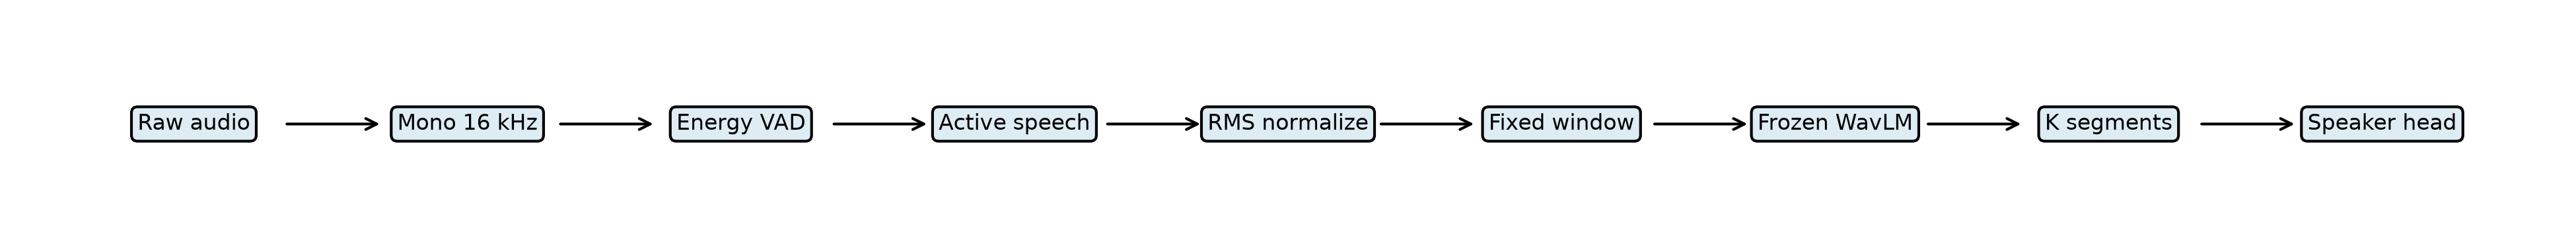

### Fig02 vad active speech

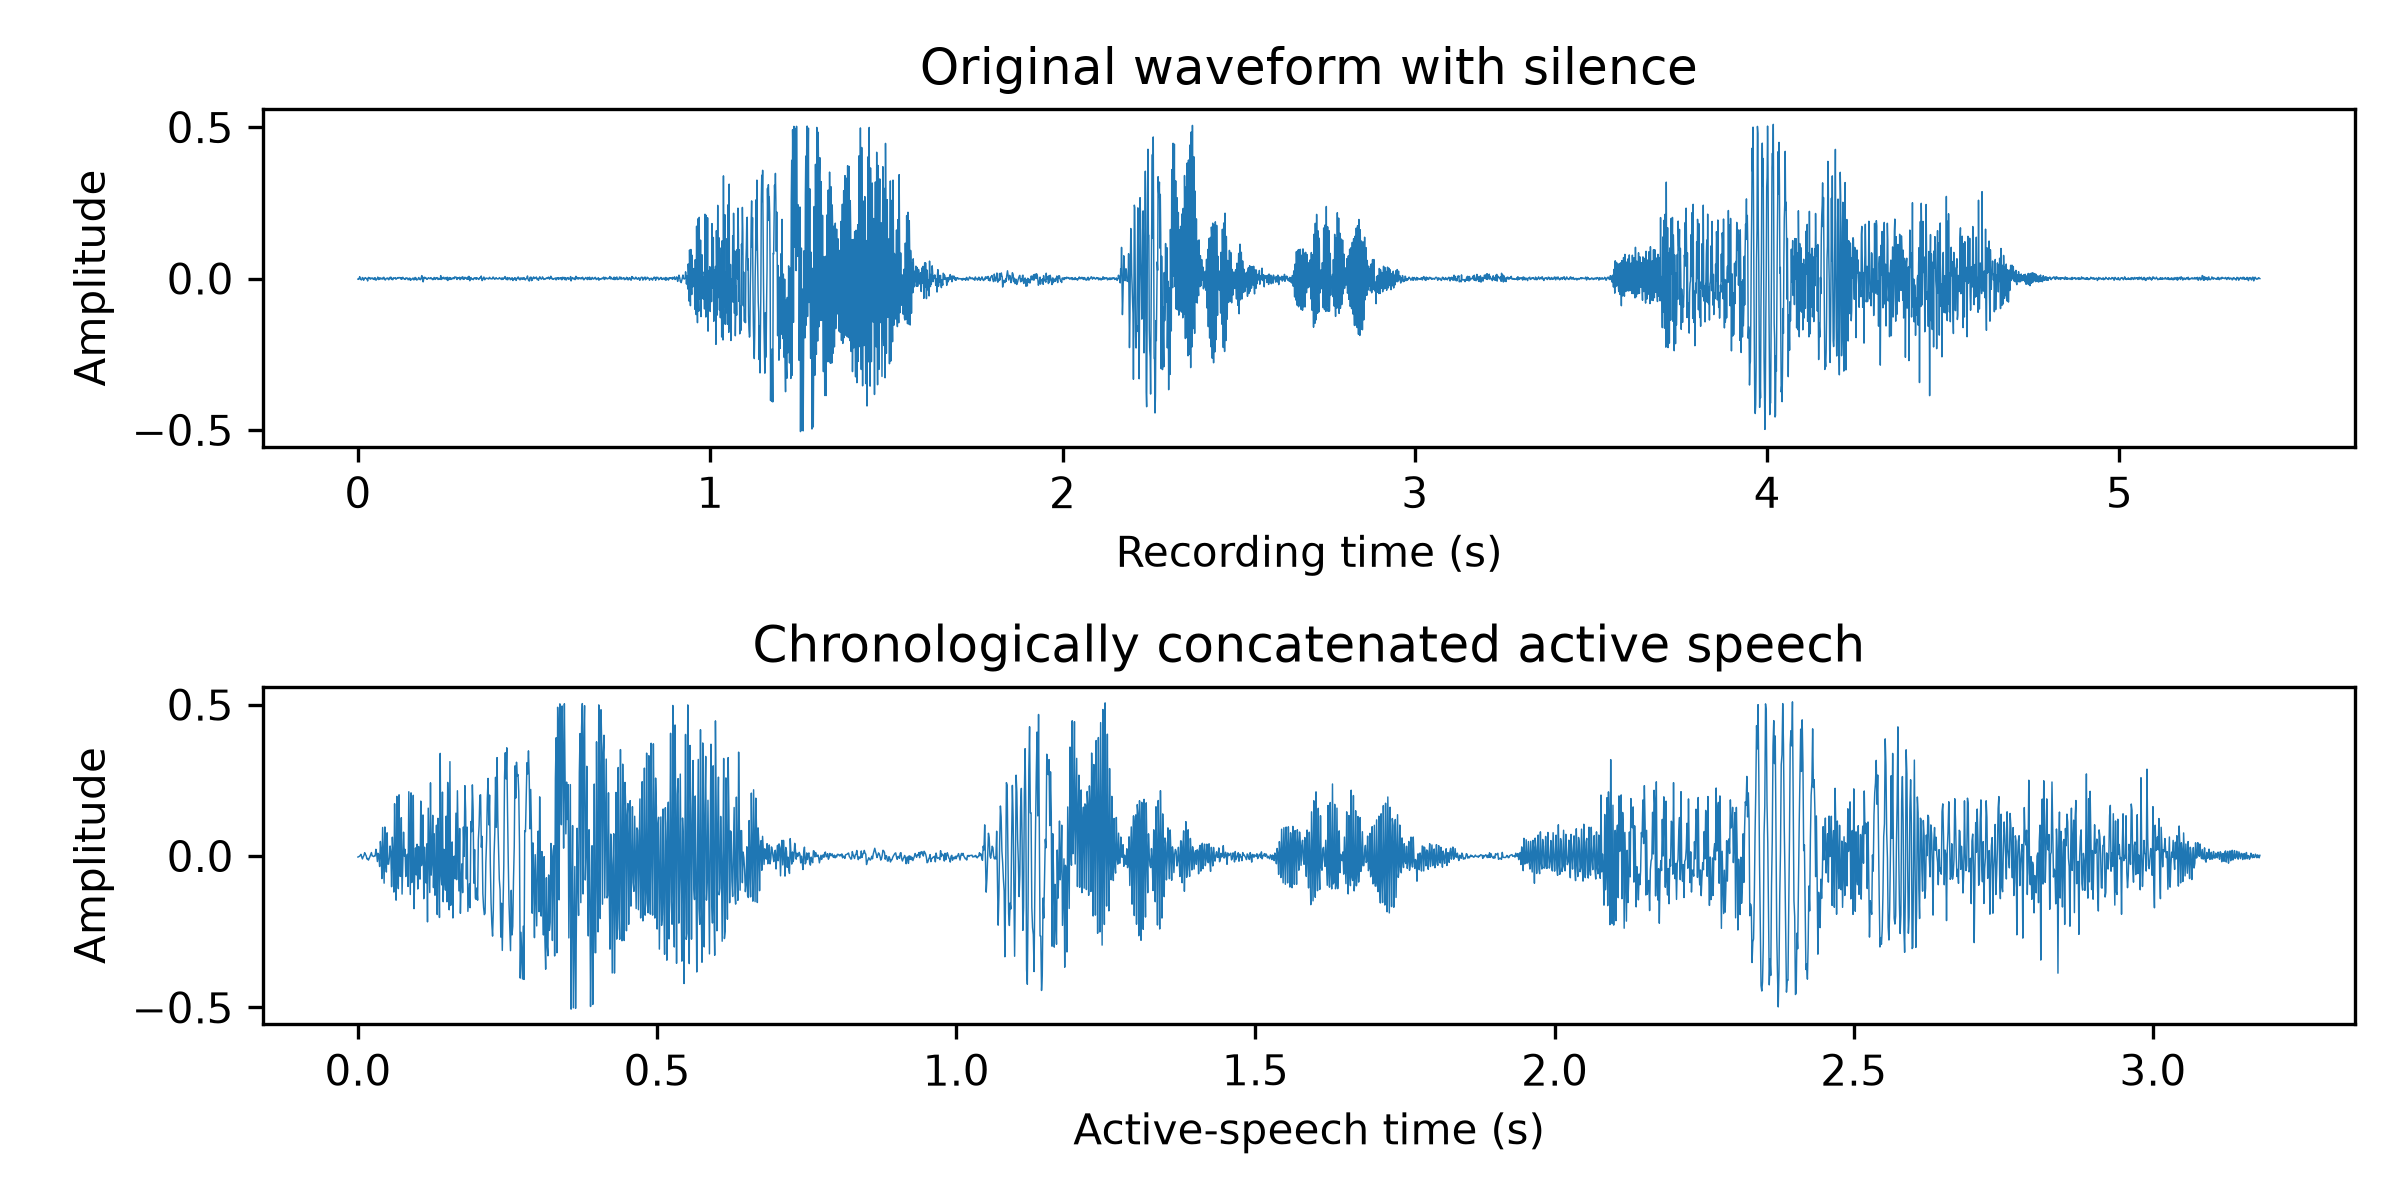

### Fig03 torgo roc pr

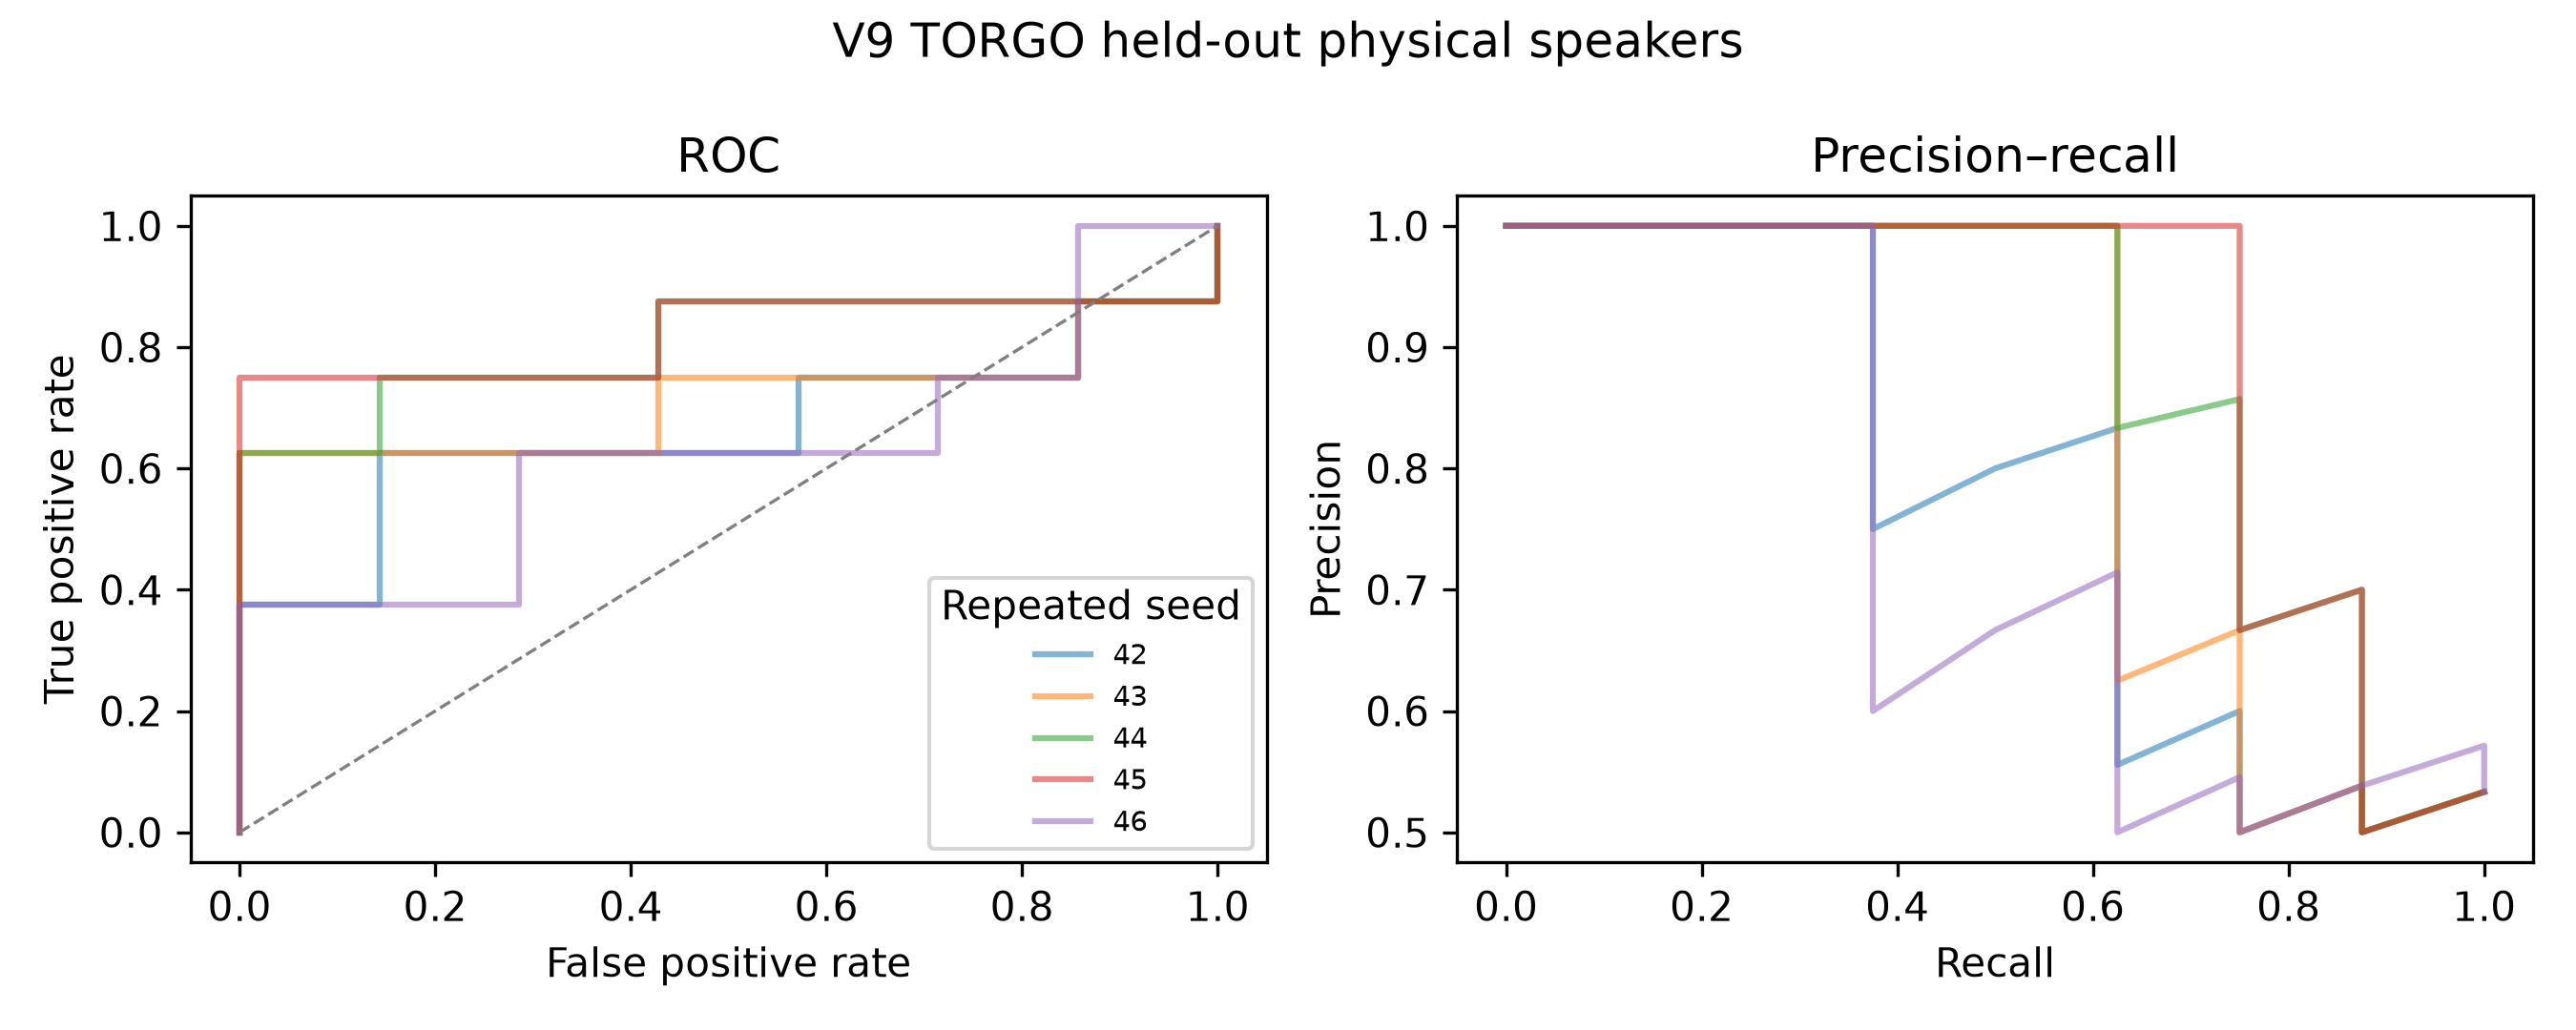

### Fig04 v8 v9 performance

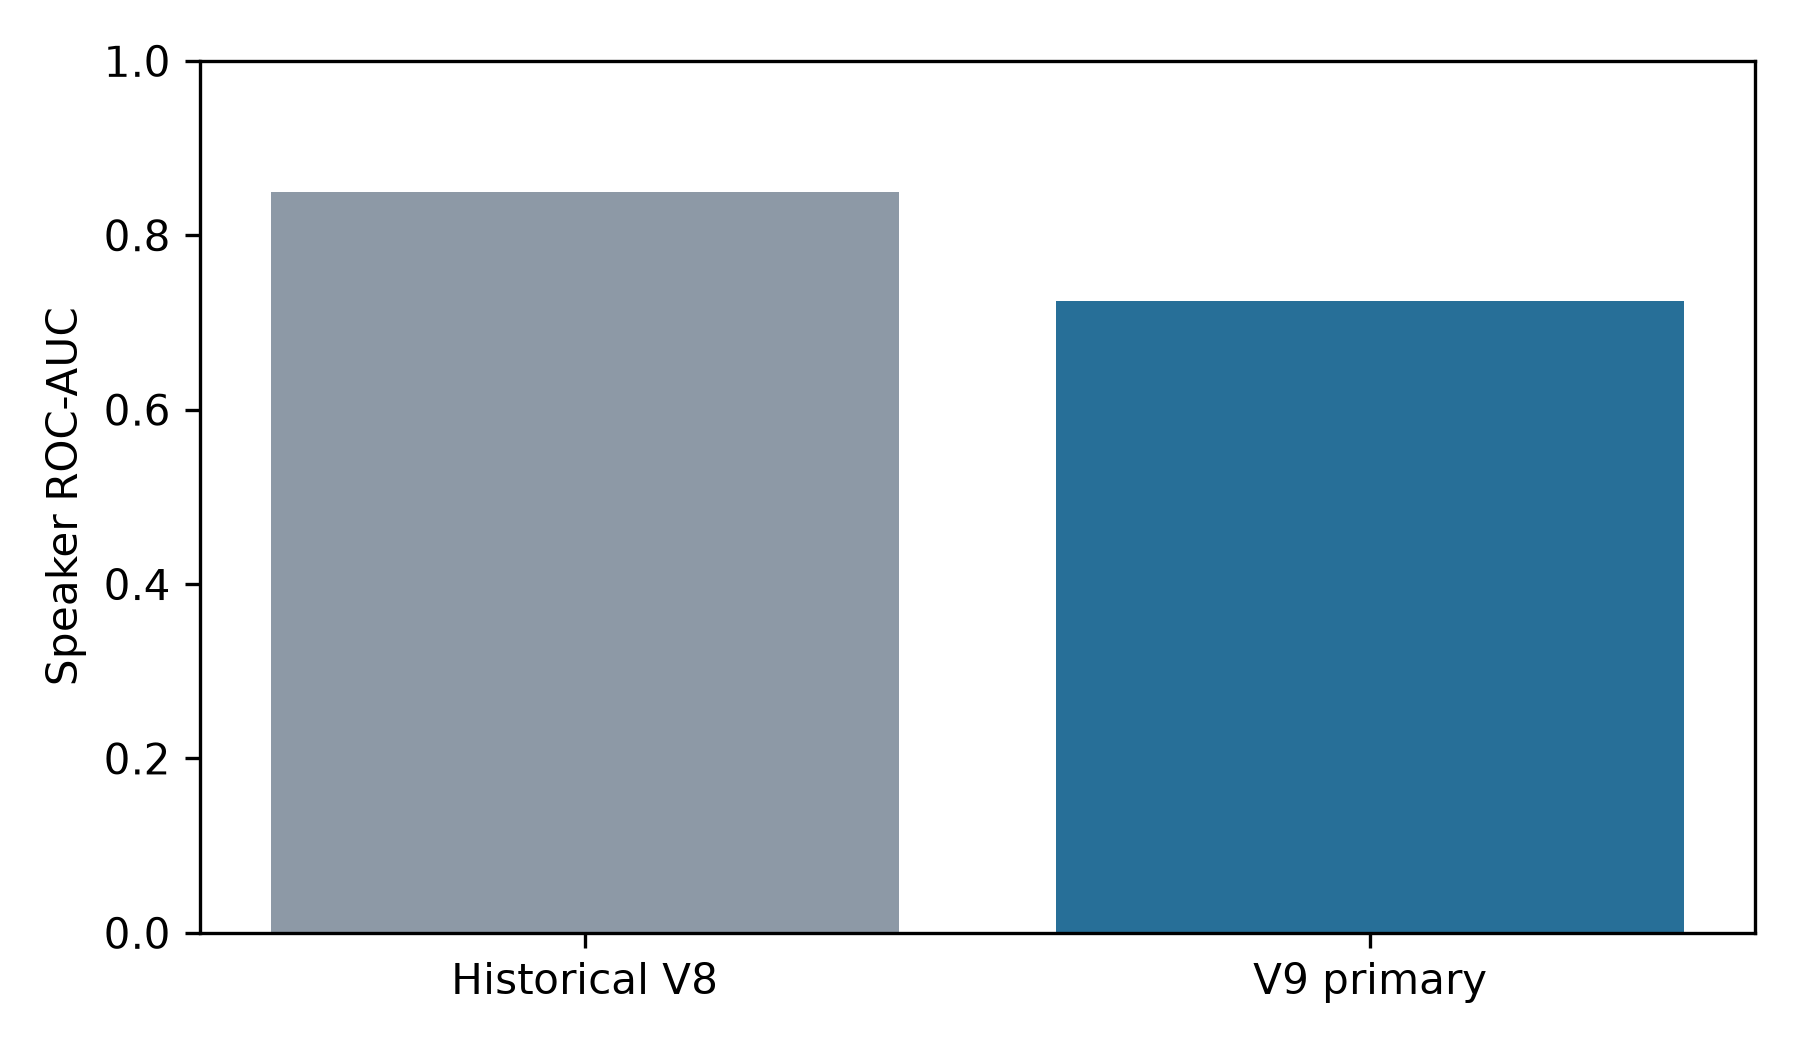

### Fig05 v8 v9 confound auc

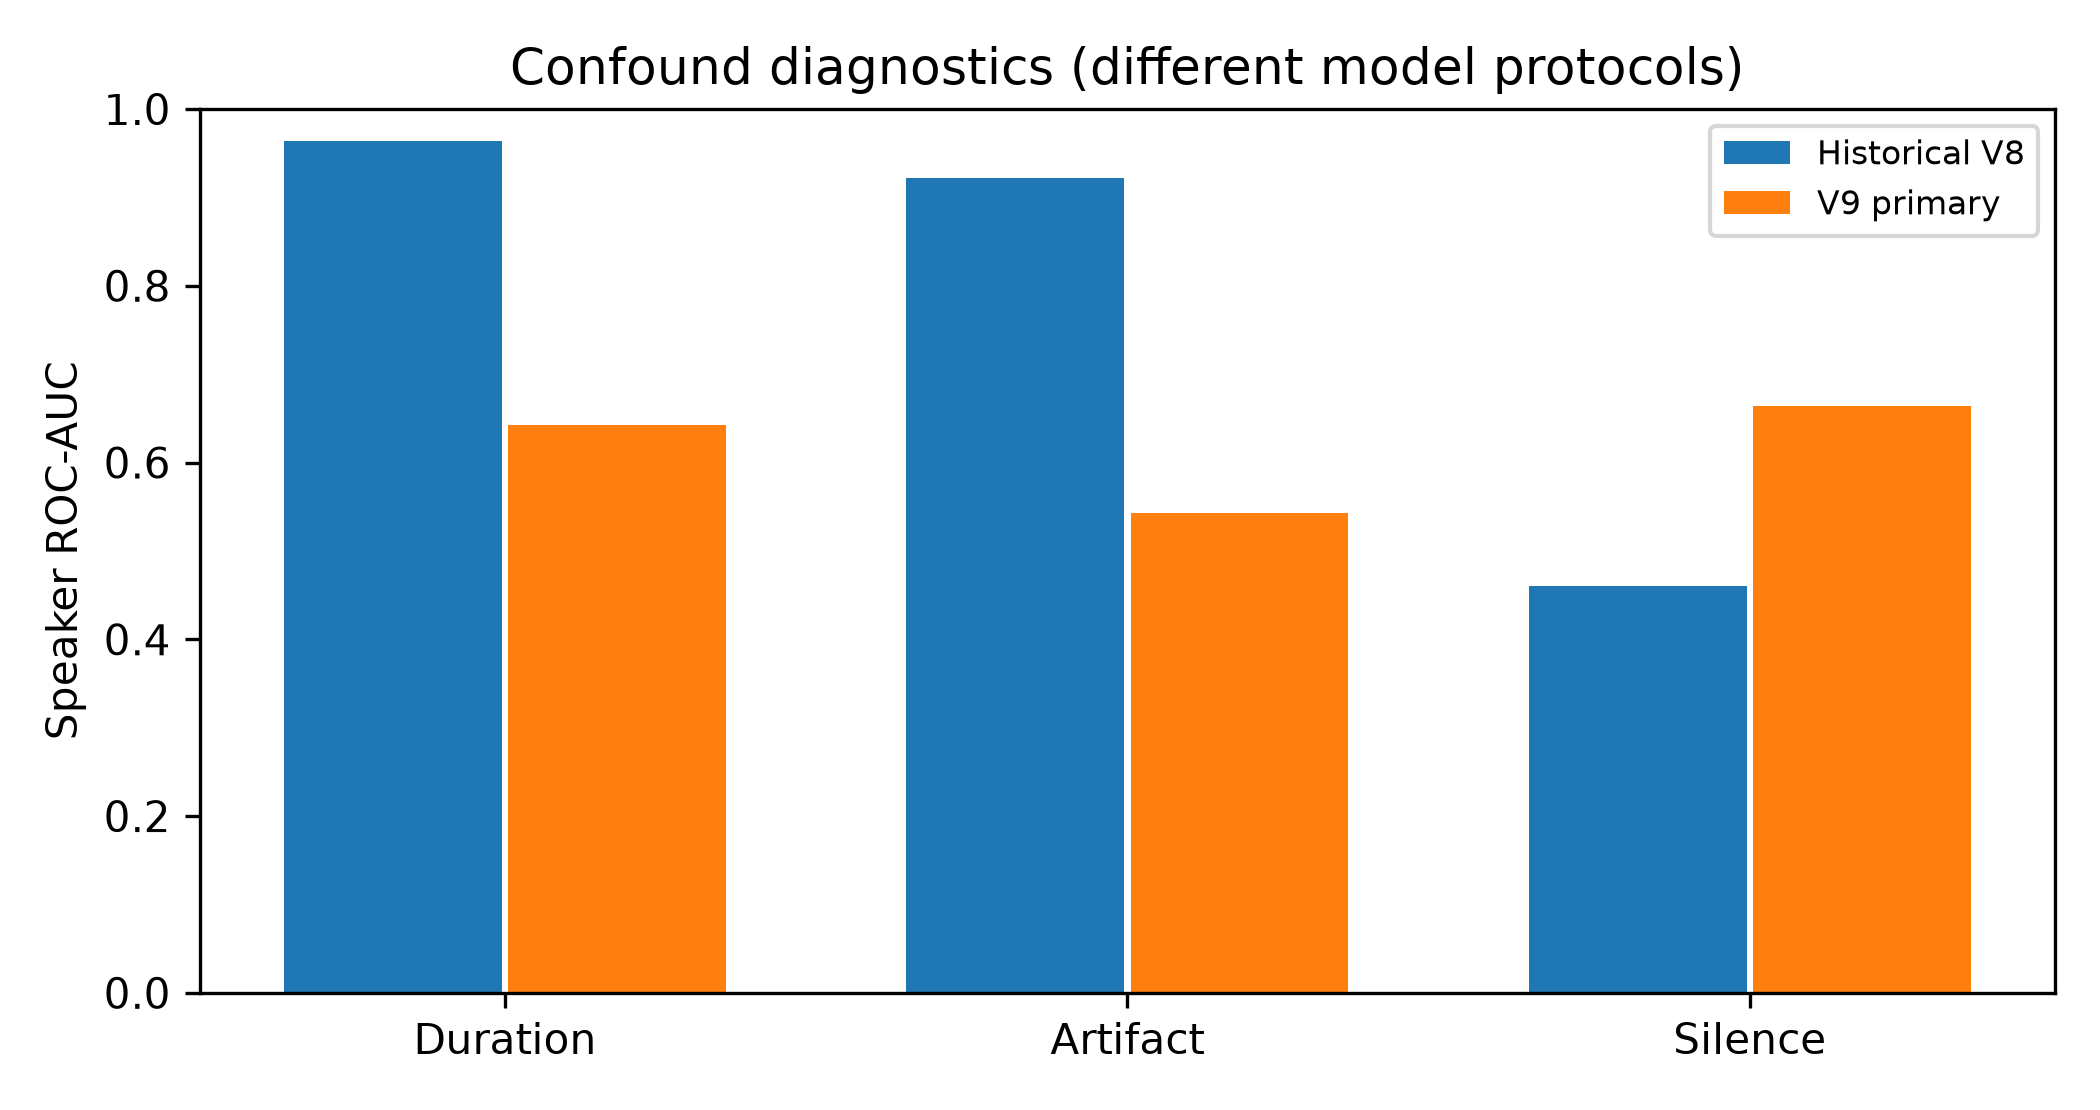

### Fig05 v9 confound auc

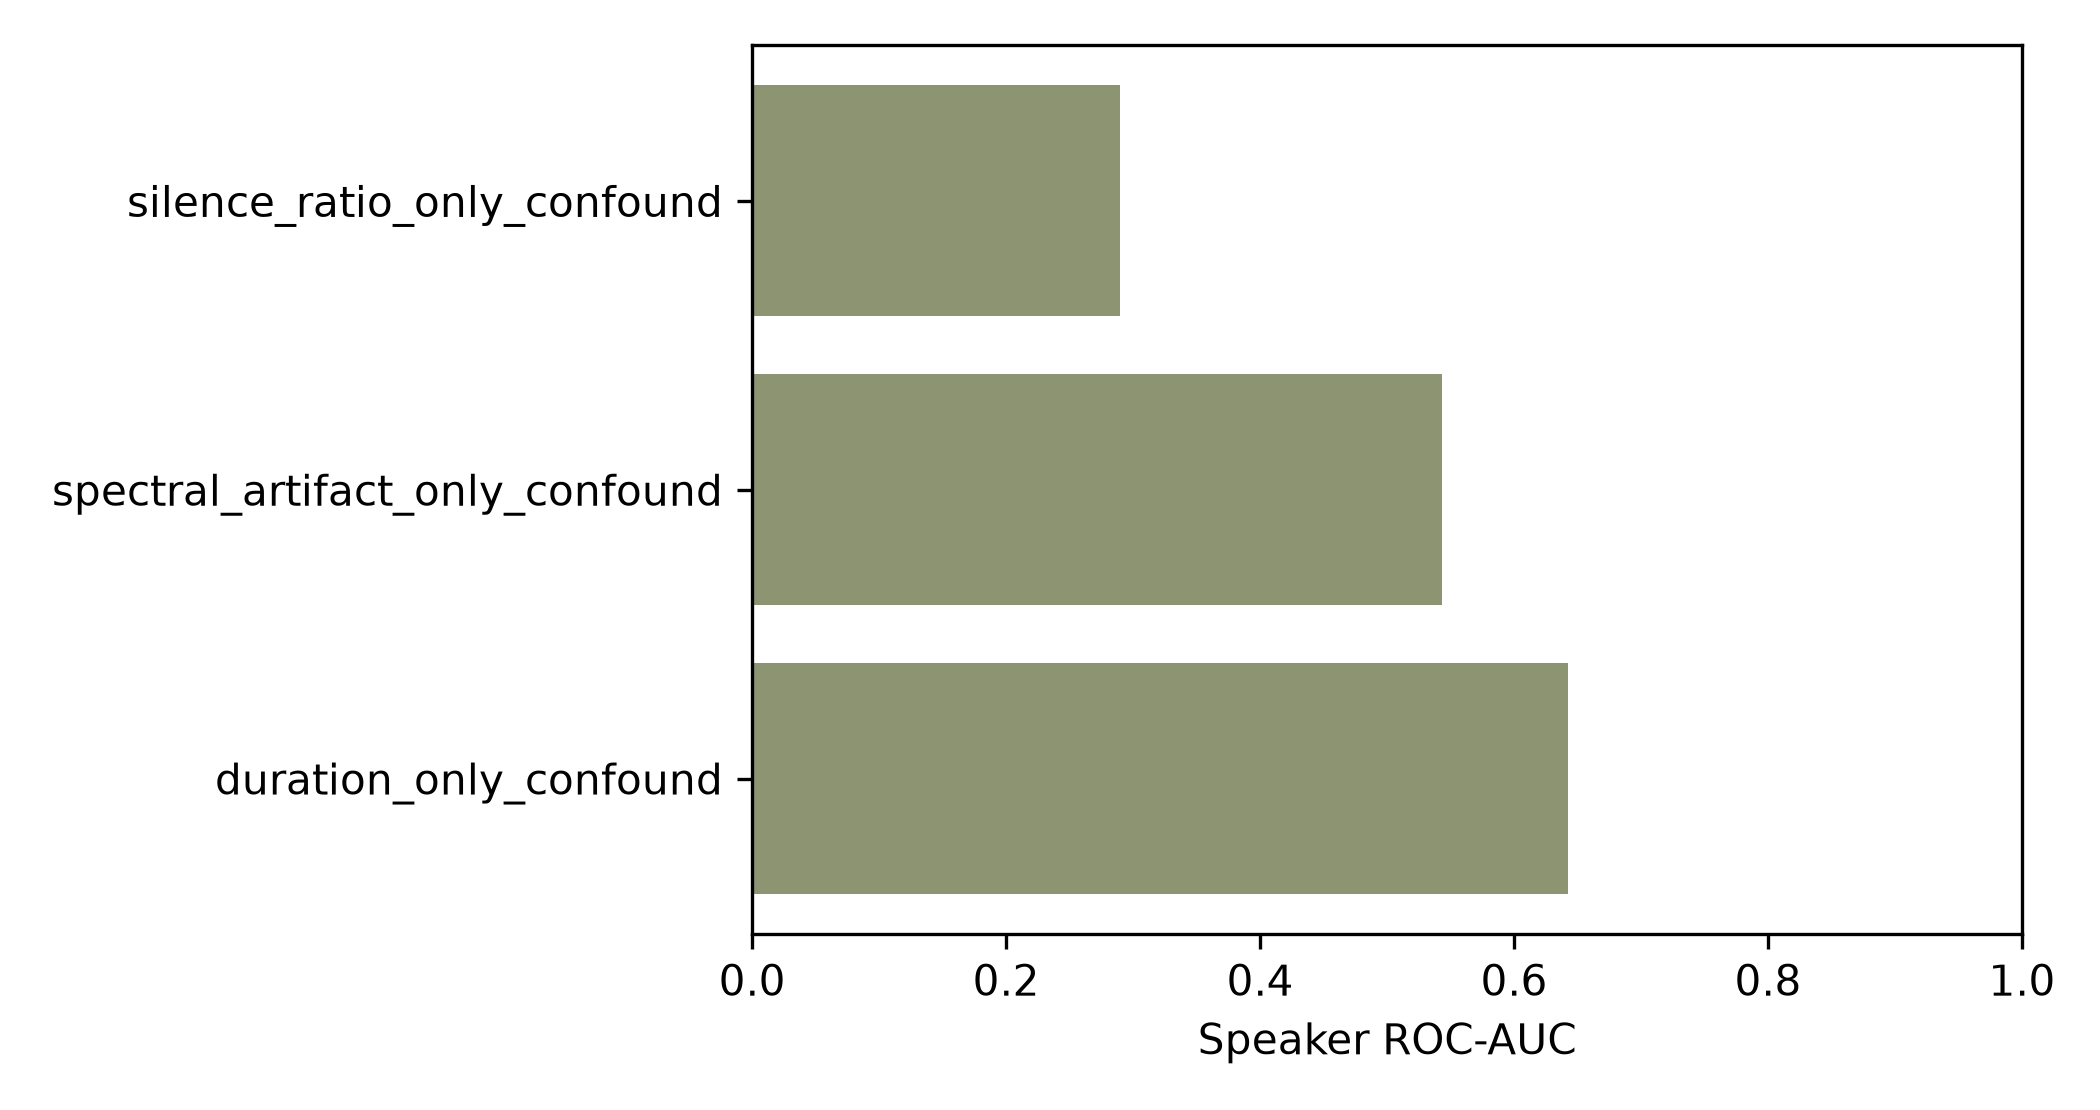

### Fig06 incremental value

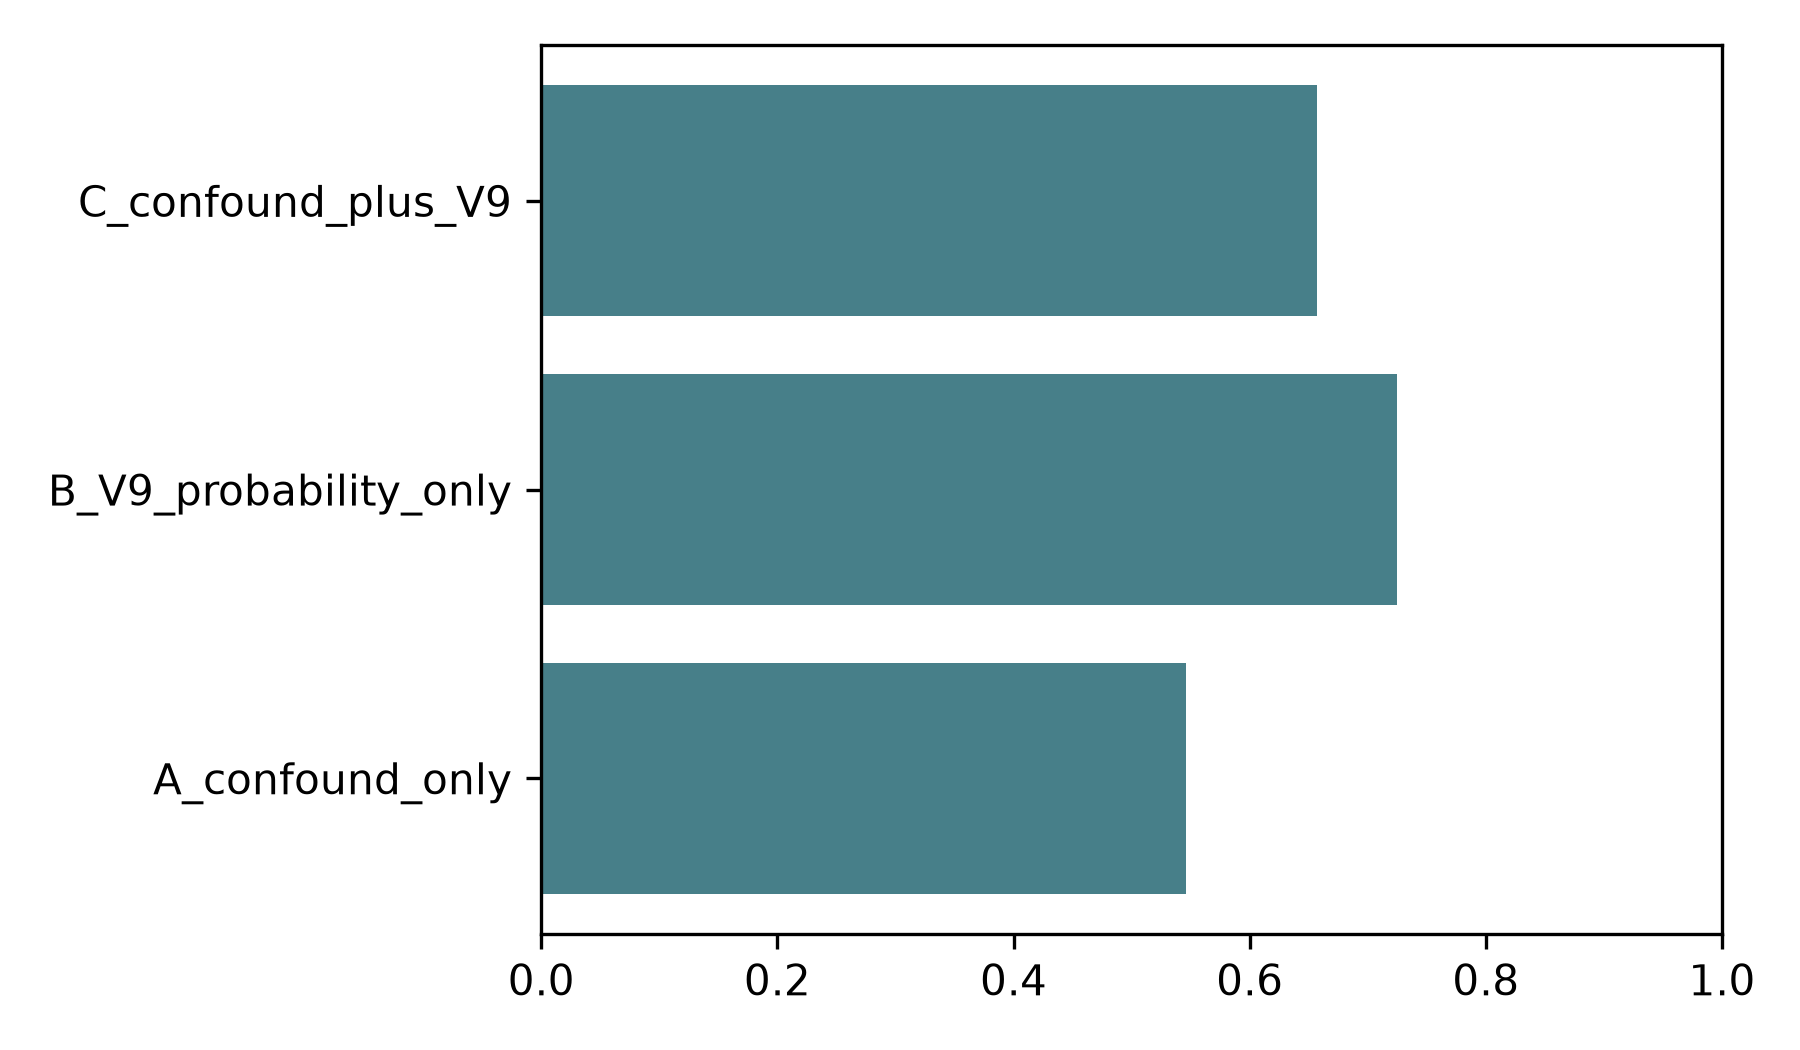

### Fig09 m3 fixed budget feasibility

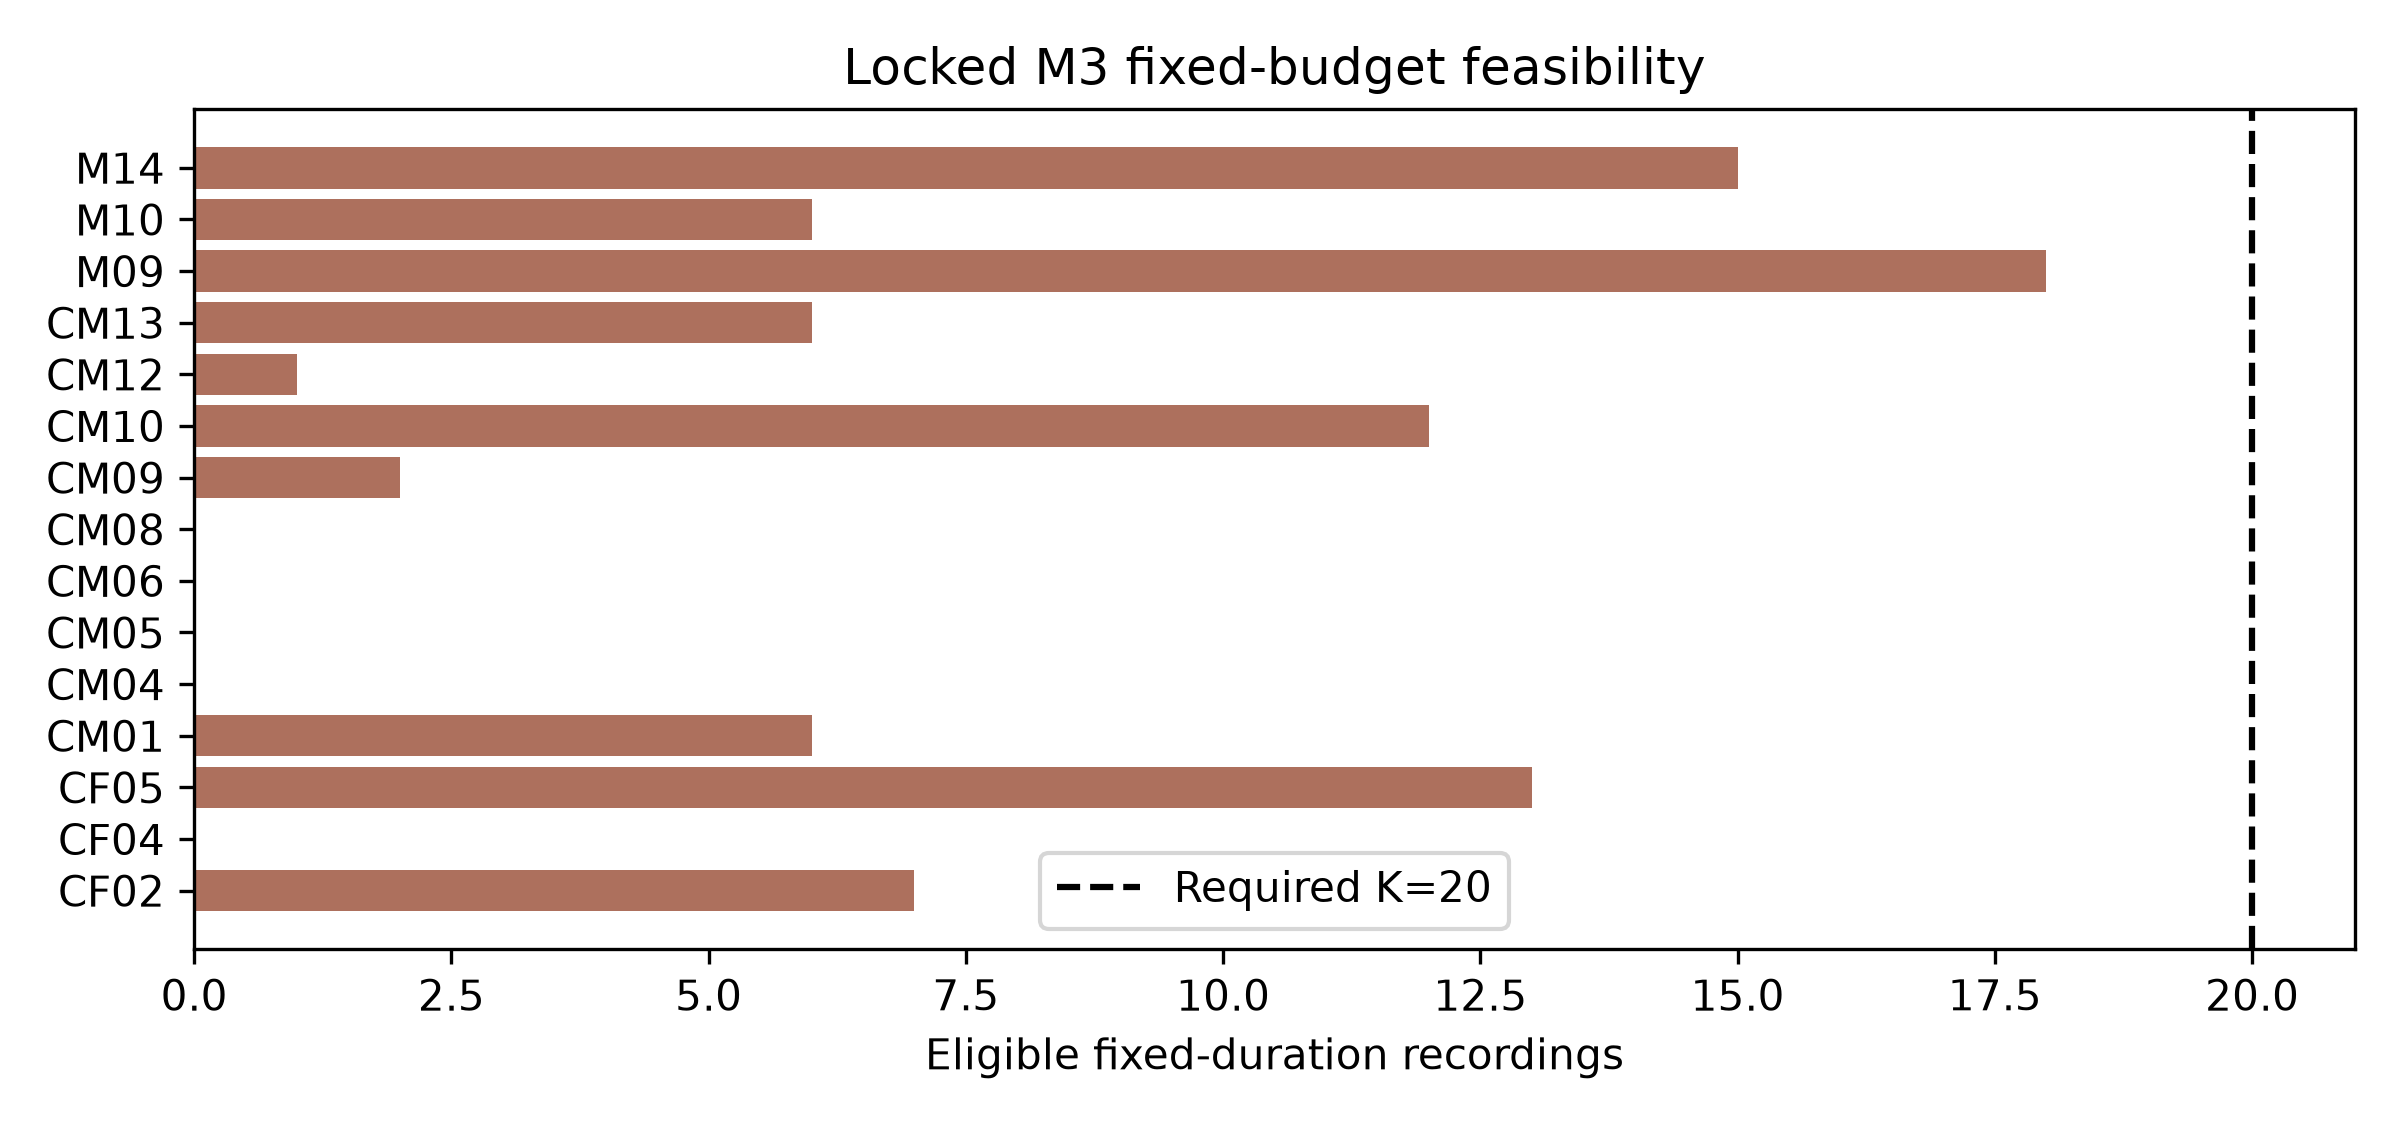

### Fig11 channel budget feasibility

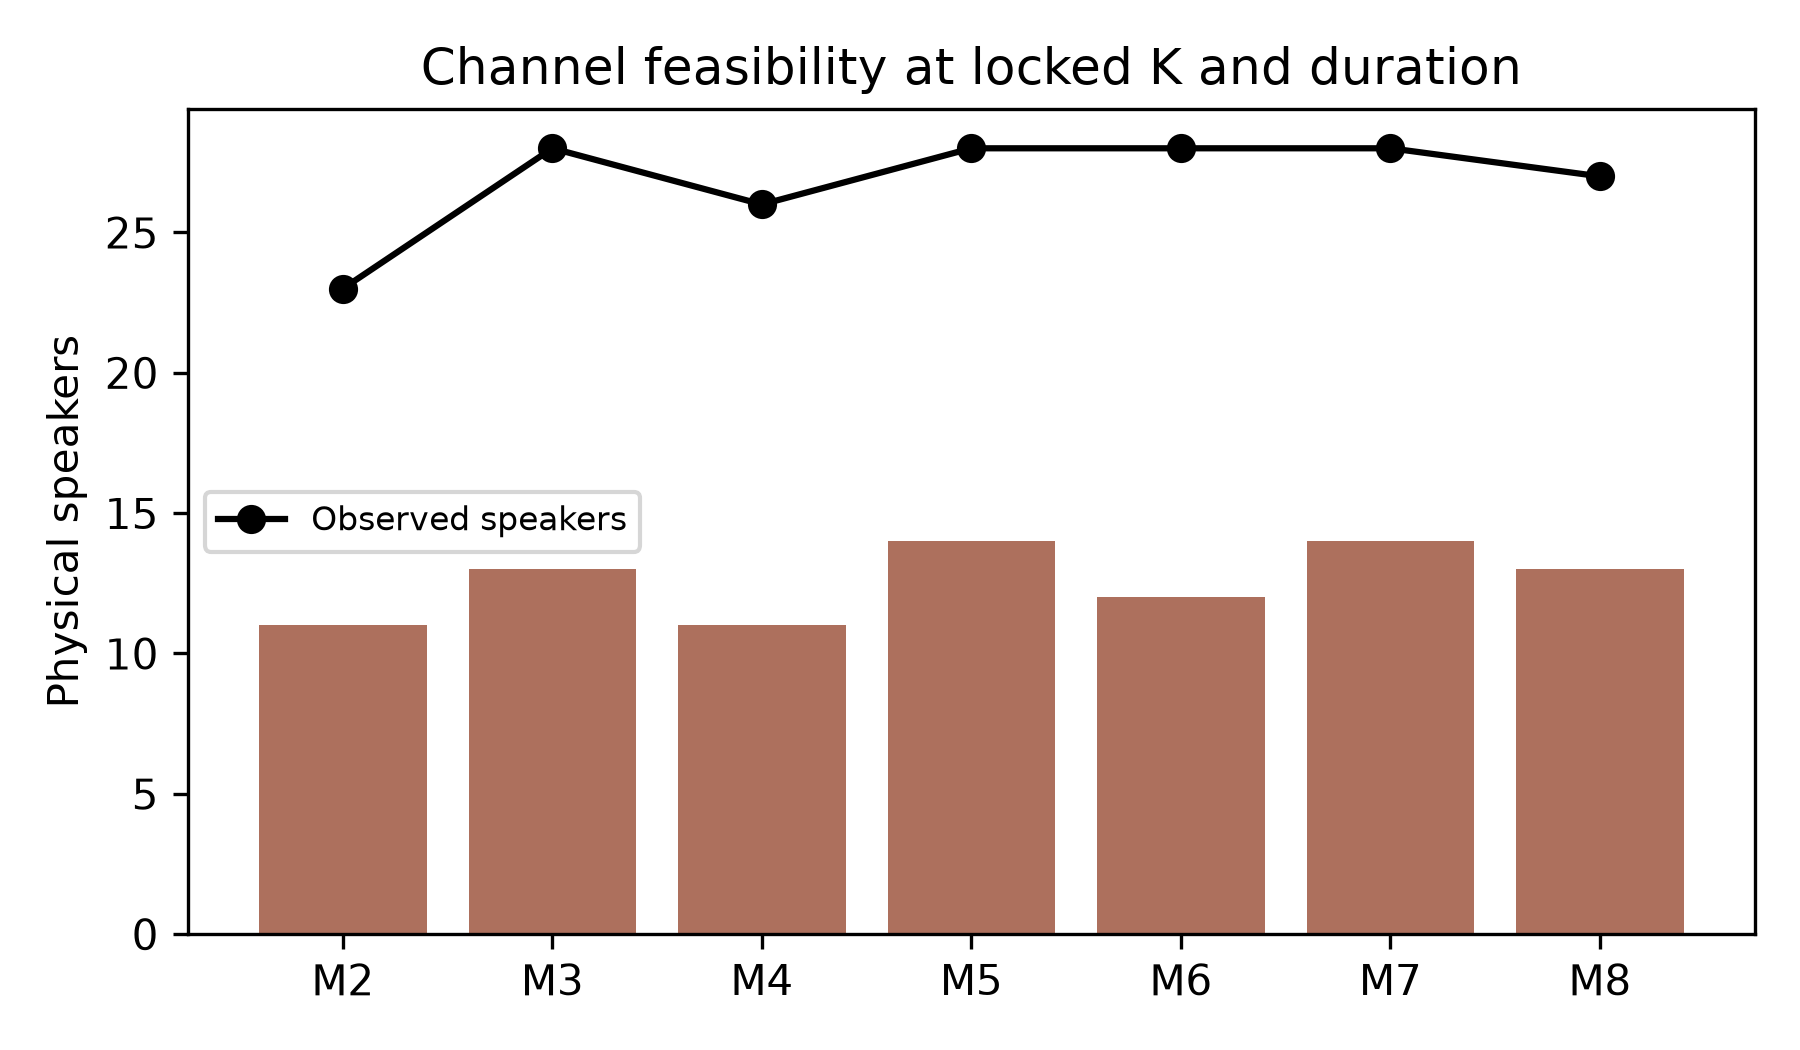

### Fig12 consistently wrong speakers

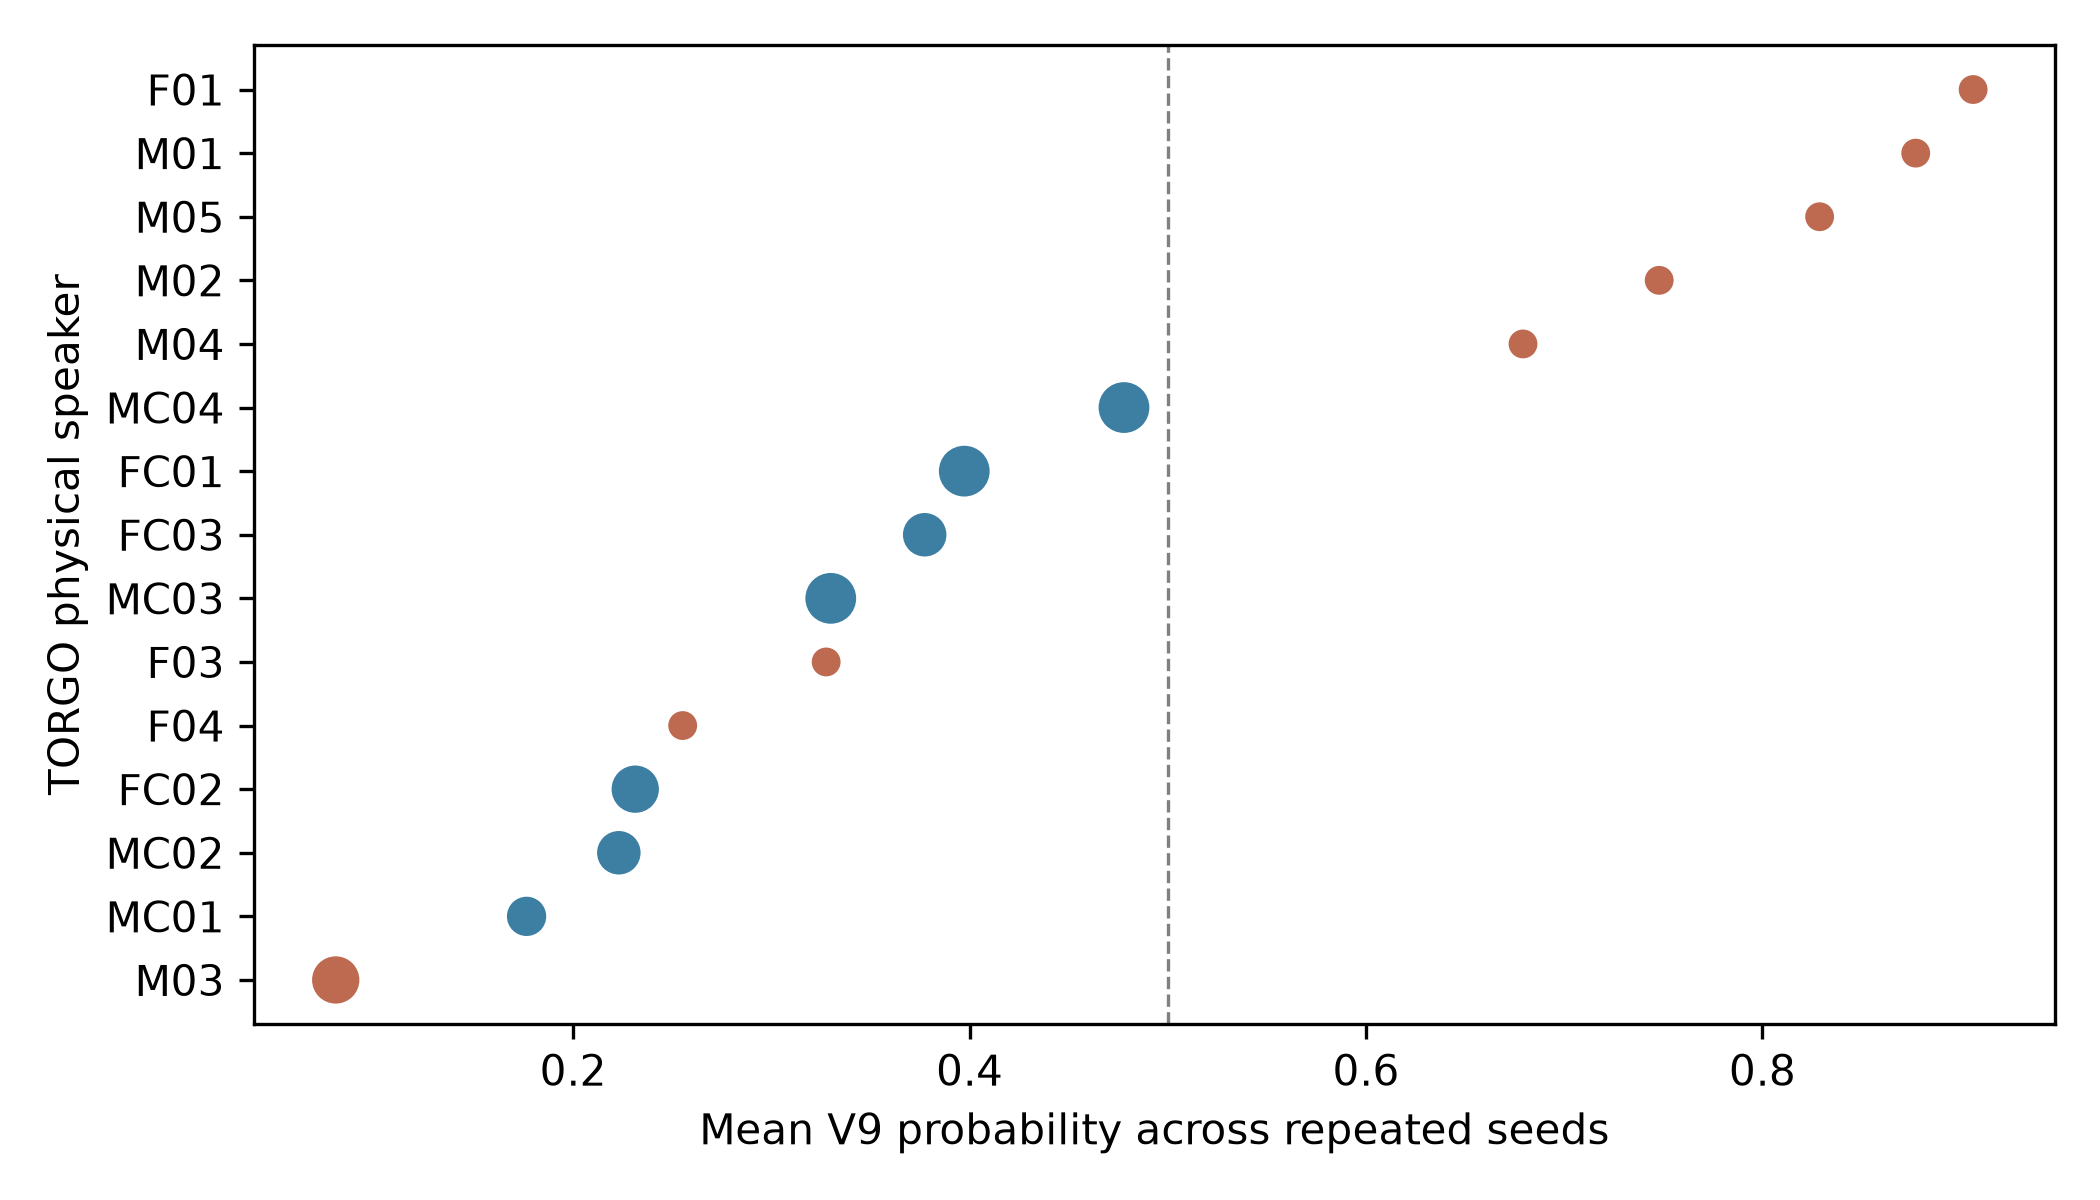

### Fig13 wavlm layer weights

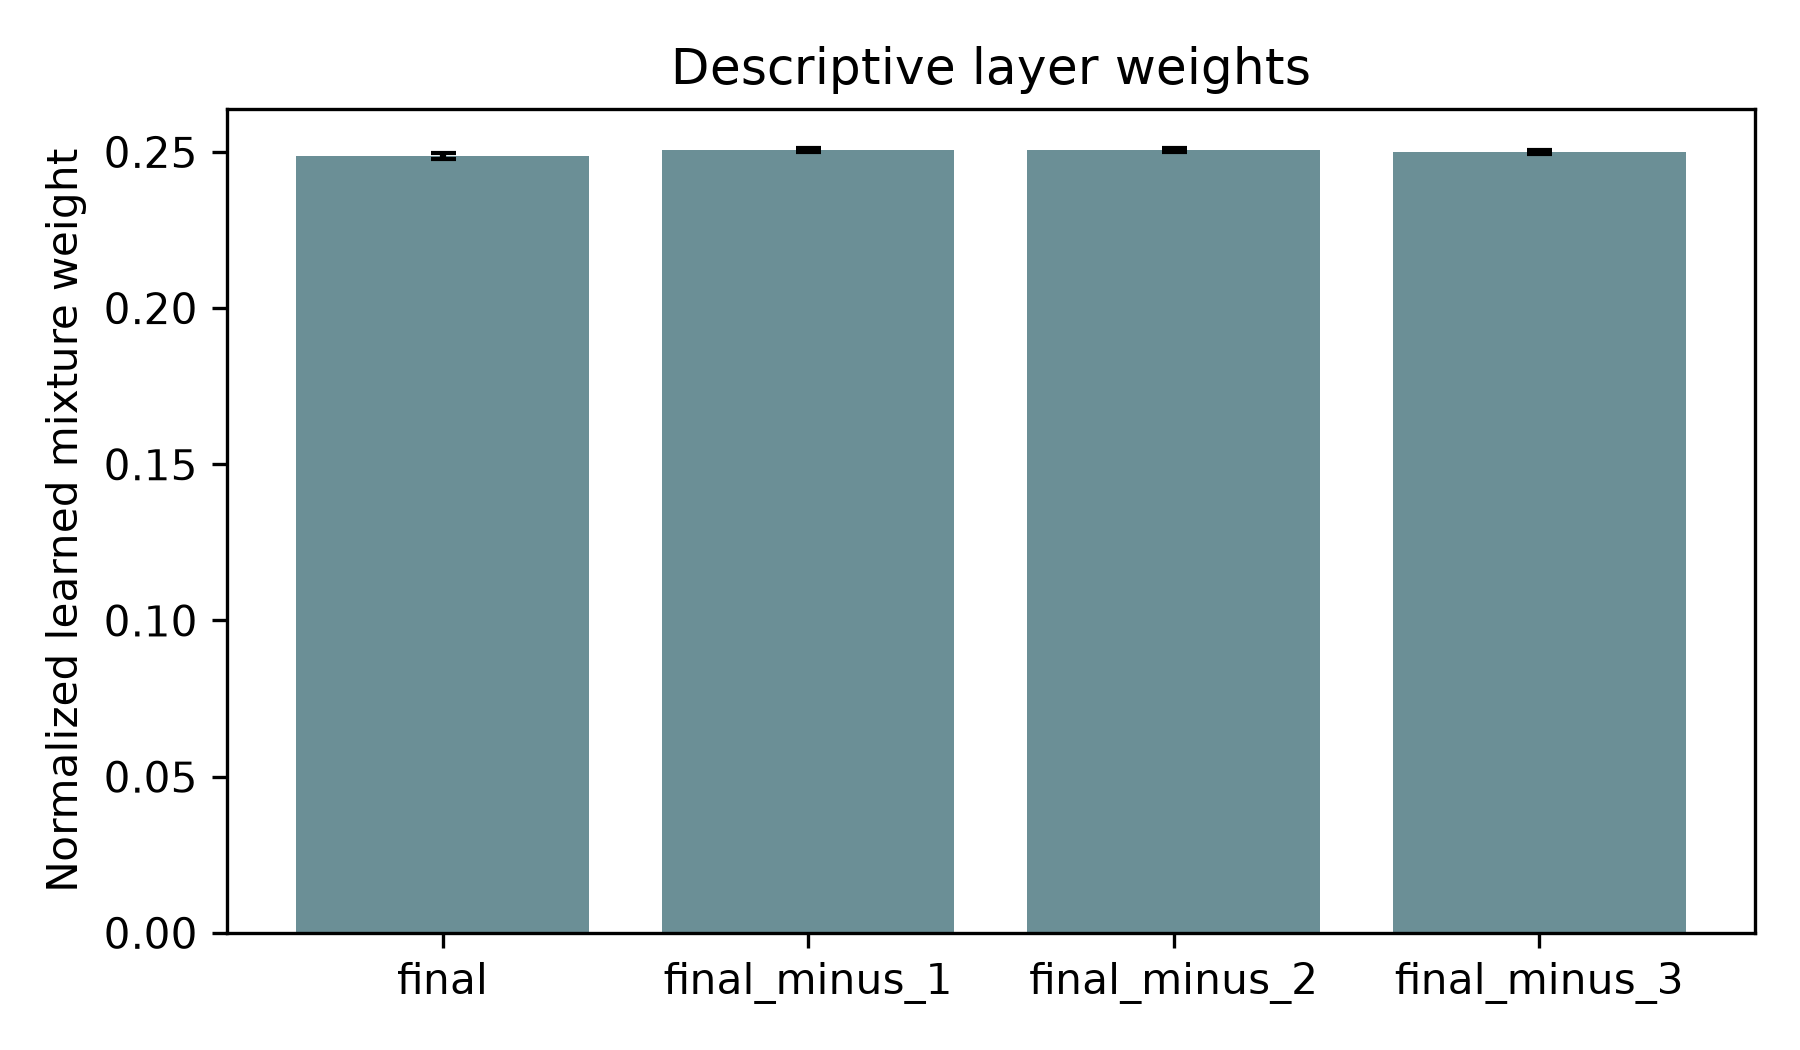

### Fig14 per layer linear probe

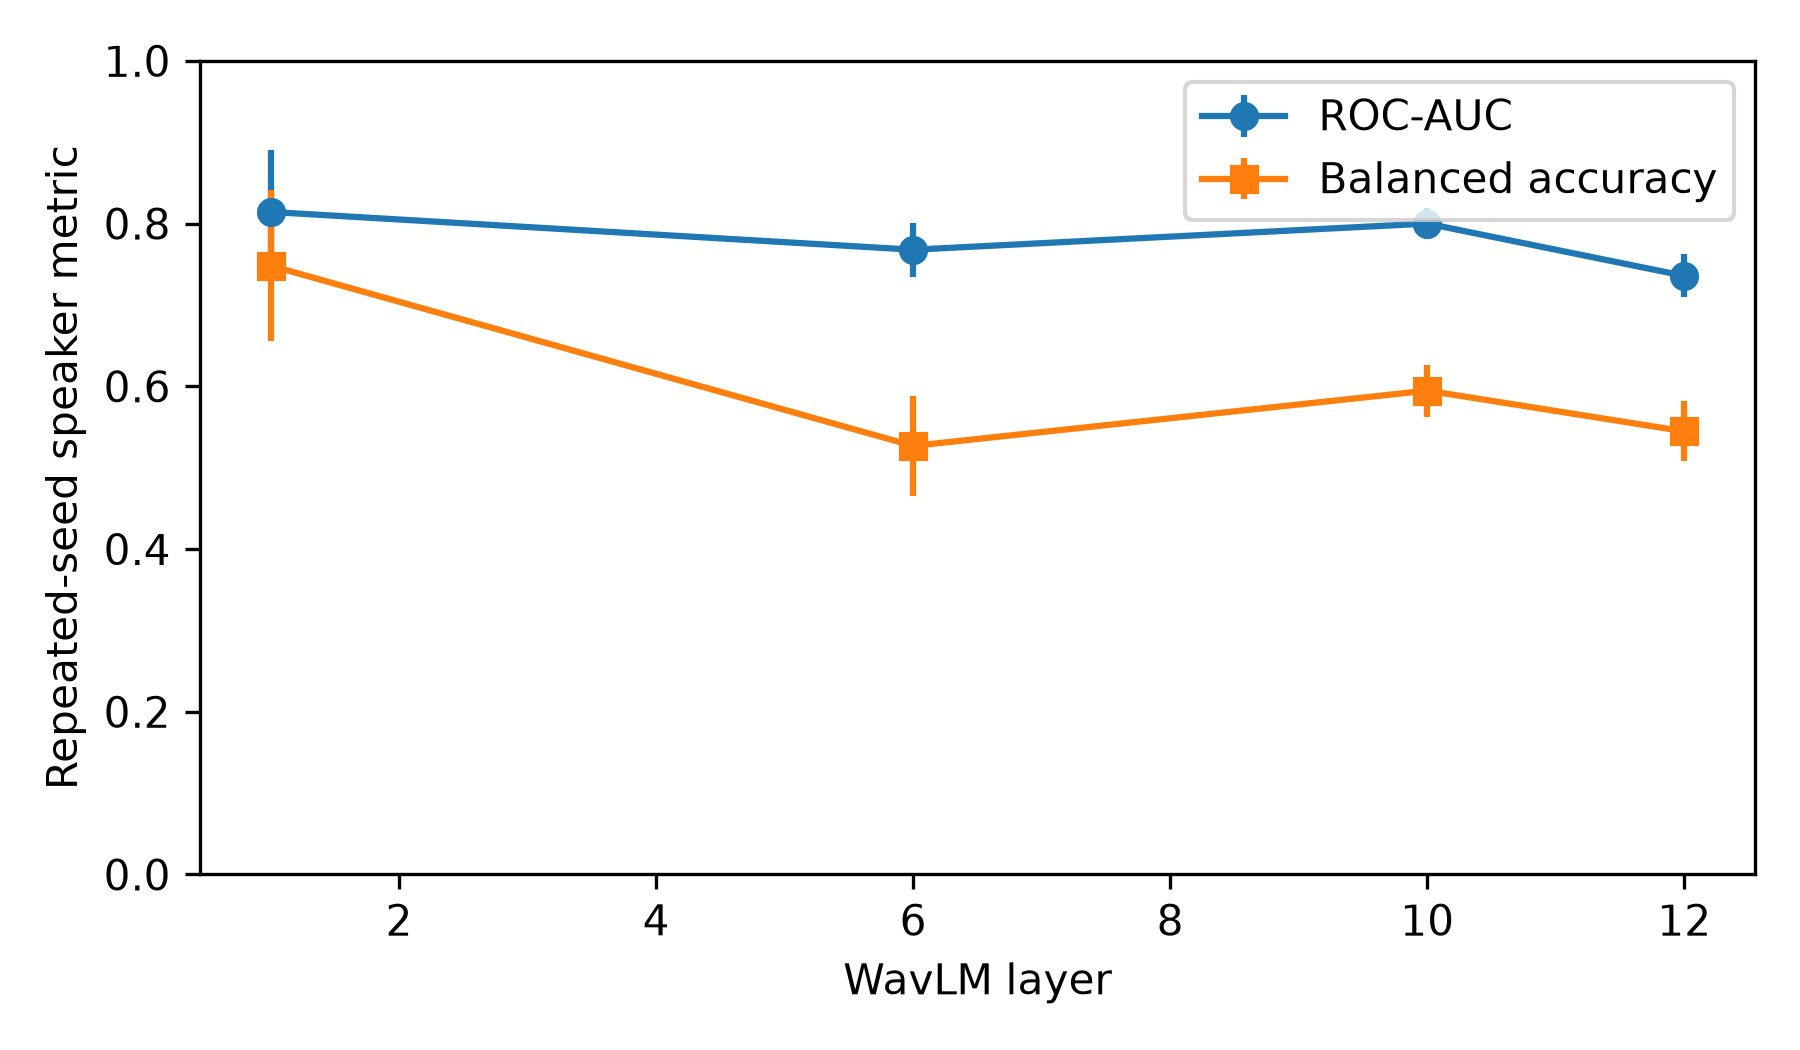

### Fig15 epoch stability

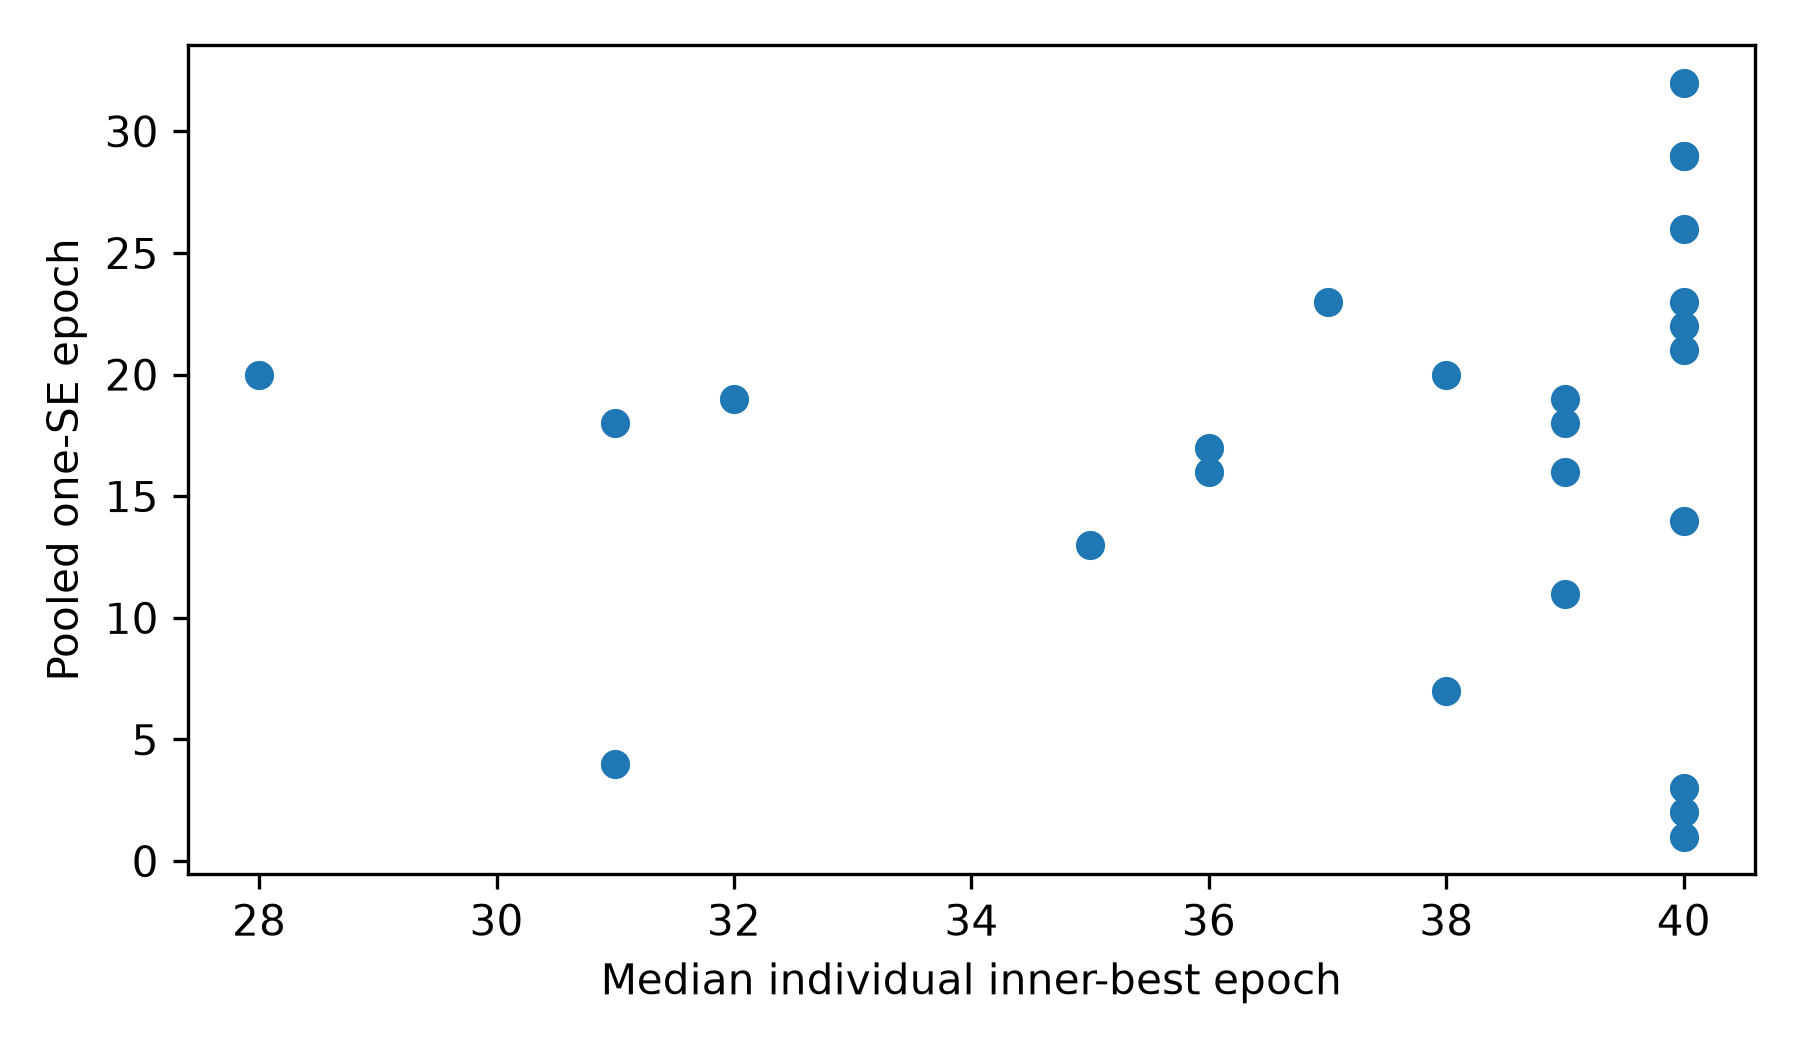

### Fig16 calibration

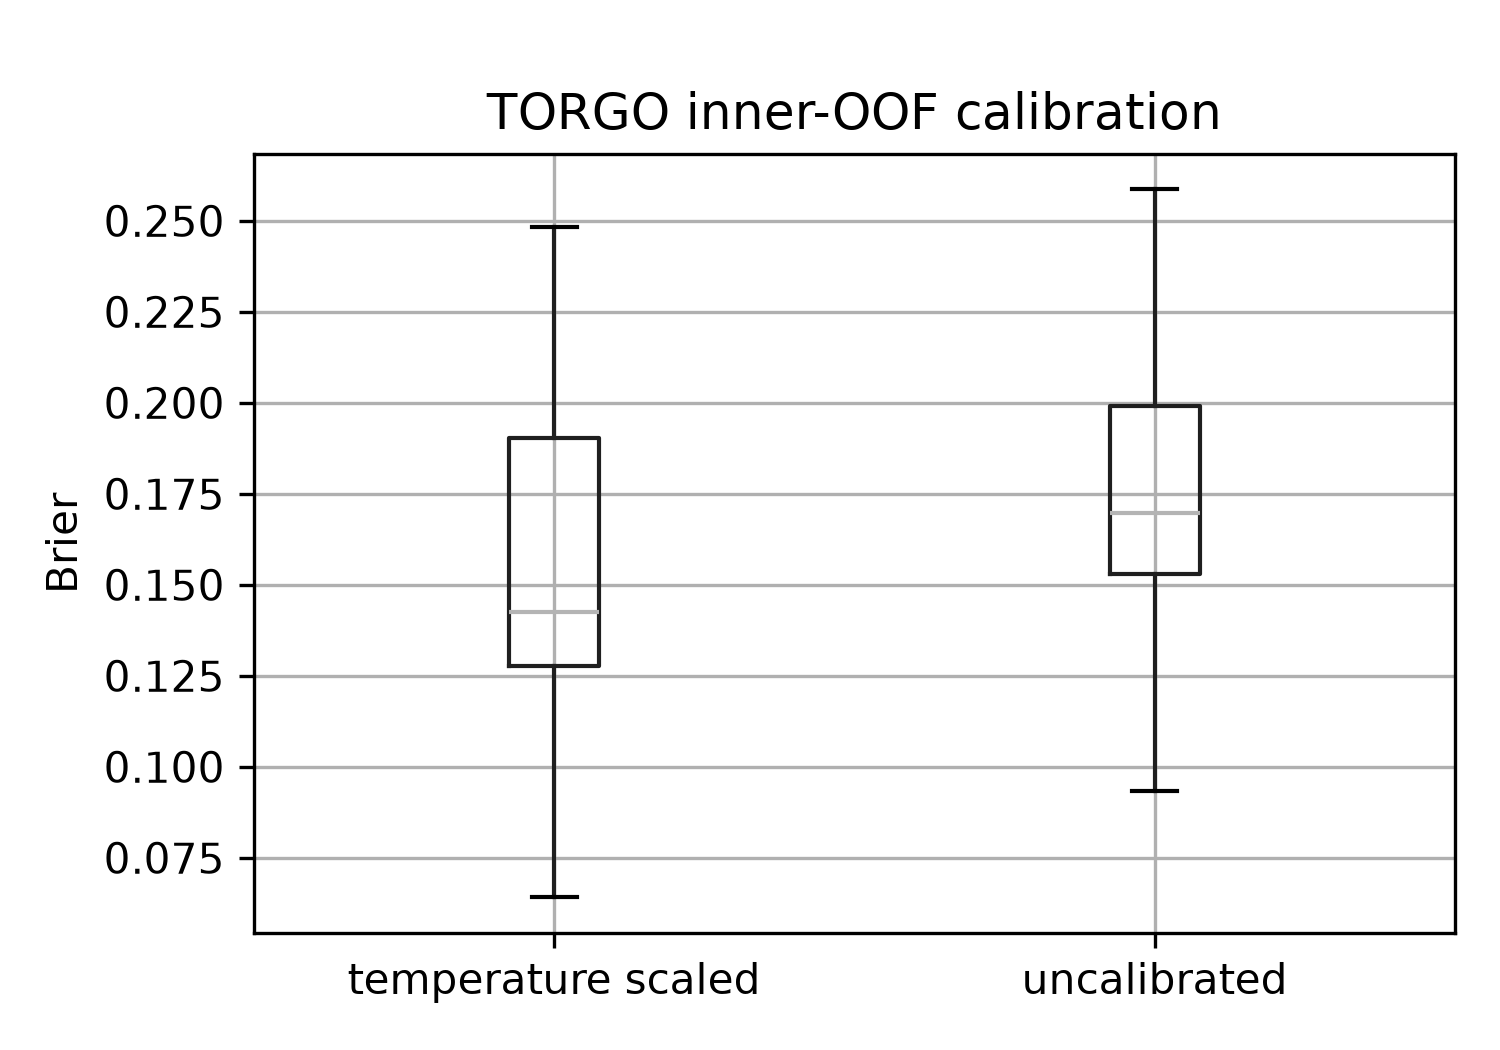

### Fig17 attention confound association

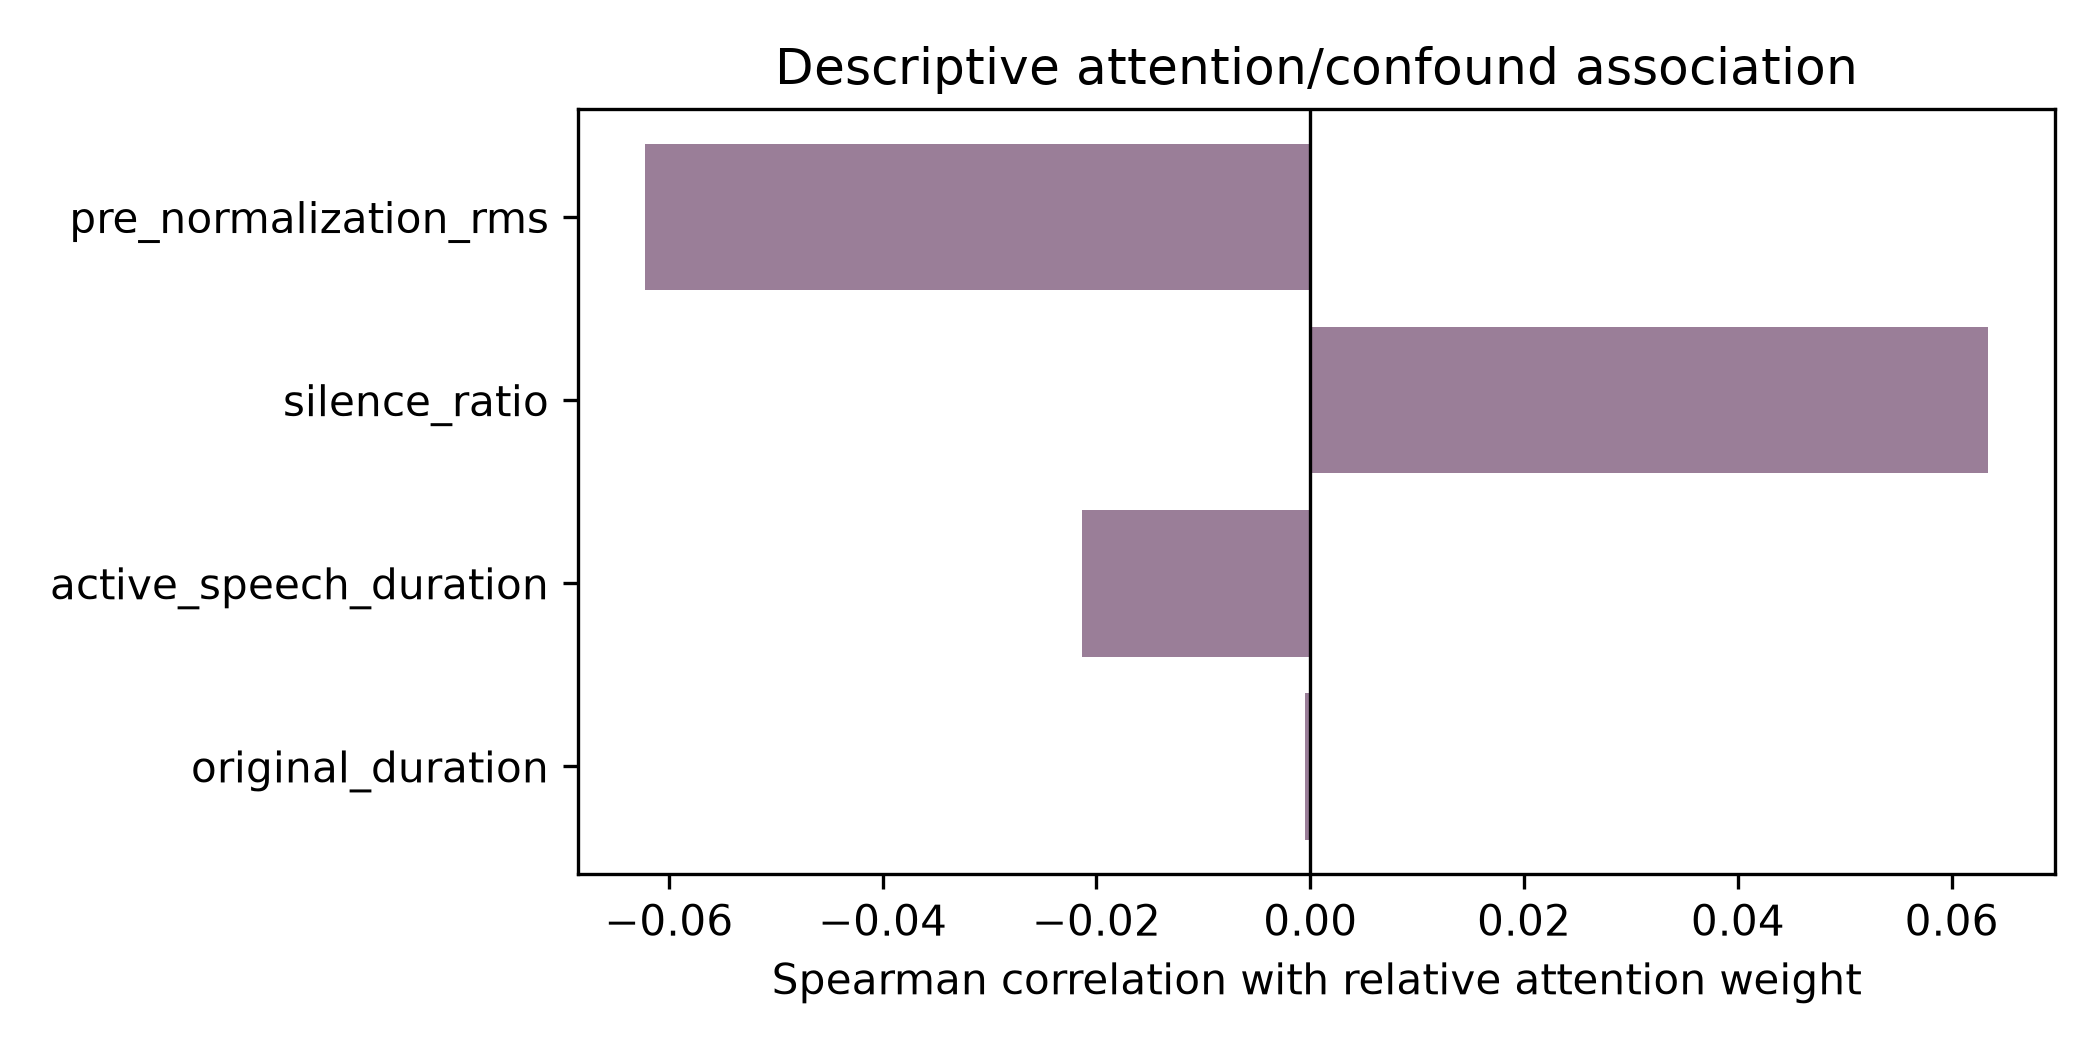

## Saved result tables

These tables preserve the exact published CSV values as a readable snapshot. Full precision and source CSVs remain in `v9_publication/tables/` in the research workspace.

### Bootstrap ablation mean final mean

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>metric</th>
      <th>point_difference_b_minus_a</th>
      <th>lower_95</th>
      <th>upper_95</th>
      <th>n_resamples</th>
      <th>resampling_unit</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Balanced_Accuracy</td>
      <td>-0.019643</td>
      <td>-0.121518</td>
      <td>0.064286</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>ROC_AUC</td>
      <td>-0.028571</td>
      <td>-0.085714</td>
      <td>0.014286</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>PR_AUC</td>
      <td>-0.014859</td>
      <td>-0.047865</td>
      <td>0.014578</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>Brier</td>
      <td>0.024564</td>
      <td>0.002681</td>
      <td>0.047387</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
  </tbody>
</table></div>

### Bootstrap ablation mean sd final attention

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>metric</th>
      <th>point_difference_b_minus_a</th>
      <th>lower_95</th>
      <th>upper_95</th>
      <th>n_resamples</th>
      <th>resampling_unit</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Balanced_Accuracy</td>
      <td>0.017857</td>
      <td>-0.078571</td>
      <td>0.117857</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>ROC_AUC</td>
      <td>0.003571</td>
      <td>-0.055446</td>
      <td>0.064286</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>PR_AUC</td>
      <td>-0.003207</td>
      <td>-0.046796</td>
      <td>0.041574</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>Brier</td>
      <td>-0.004689</td>
      <td>-0.030559</td>
      <td>0.023408</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
  </tbody>
</table></div>

### Bootstrap ablation mean sd last four mean

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>metric</th>
      <th>point_difference_b_minus_a</th>
      <th>lower_95</th>
      <th>upper_95</th>
      <th>n_resamples</th>
      <th>resampling_unit</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Balanced_Accuracy</td>
      <td>0.016071</td>
      <td>-0.025000</td>
      <td>0.057143</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>ROC_AUC</td>
      <td>0.010714</td>
      <td>-0.034018</td>
      <td>0.053571</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>PR_AUC</td>
      <td>0.002450</td>
      <td>-0.027107</td>
      <td>0.025947</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>Brier</td>
      <td>-0.004103</td>
      <td>-0.018274</td>
      <td>0.010062</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
  </tbody>
</table></div>

### Bootstrap v8 v9 artifact only

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>metric</th>
      <th>point_difference_b_minus_a</th>
      <th>lower_95</th>
      <th>upper_95</th>
      <th>n_resamples</th>
      <th>resampling_unit</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Balanced_Accuracy</td>
      <td>-0.053571</td>
      <td>-0.164375</td>
      <td>0.070580</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>ROC_AUC</td>
      <td>-0.378571</td>
      <td>-0.675179</td>
      <td>-0.094554</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>PR_AUC</td>
      <td>-0.335407</td>
      <td>-0.472556</td>
      <td>-0.073428</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>Brier</td>
      <td>0.160257</td>
      <td>0.038364</td>
      <td>0.271584</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
  </tbody>
</table></div>

### Bootstrap v8 v9 duration only

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>metric</th>
      <th>point_difference_b_minus_a</th>
      <th>lower_95</th>
      <th>upper_95</th>
      <th>n_resamples</th>
      <th>resampling_unit</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Balanced_Accuracy</td>
      <td>-0.223214</td>
      <td>-0.379598</td>
      <td>-0.076696</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>ROC_AUC</td>
      <td>-0.321429</td>
      <td>-0.614464</td>
      <td>-0.057143</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>PR_AUC</td>
      <td>-0.229731</td>
      <td>-0.412323</td>
      <td>-0.033135</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>Brier</td>
      <td>0.135695</td>
      <td>0.037784</td>
      <td>0.242798</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
  </tbody>
</table></div>

### Bootstrap v8 v9 model

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>metric</th>
      <th>point_difference_b_minus_a</th>
      <th>lower_95</th>
      <th>upper_95</th>
      <th>n_resamples</th>
      <th>resampling_unit</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Balanced_Accuracy</td>
      <td>-0.289286</td>
      <td>-0.418973</td>
      <td>-0.148973</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>ROC_AUC</td>
      <td>-0.125000</td>
      <td>-0.359018</td>
      <td>0.087589</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>PR_AUC</td>
      <td>-0.048506</td>
      <td>-0.195998</td>
      <td>0.083872</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>Brier</td>
      <td>0.049449</td>
      <td>-0.062627</td>
      <td>0.148968</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
  </tbody>
</table></div>

### Bootstrap v8 v9 silence only

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>metric</th>
      <th>point_difference_b_minus_a</th>
      <th>lower_95</th>
      <th>upper_95</th>
      <th>n_resamples</th>
      <th>resampling_unit</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Balanced_Accuracy</td>
      <td>0.105357</td>
      <td>-0.062589</td>
      <td>0.269643</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>ROC_AUC</td>
      <td>0.203571</td>
      <td>-0.139286</td>
      <td>0.541161</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>PR_AUC</td>
      <td>0.212611</td>
      <td>-0.064054</td>
      <td>0.385054</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>Brier</td>
      <td>-0.094485</td>
      <td>-0.261757</td>
      <td>0.059854</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
  </tbody>
</table></div>

### Master v8 v9 comparison

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>Method</th>
      <th>Evaluation protocol</th>
      <th>Speech preprocessing</th>
      <th>Evidence budget</th>
      <th>n_physical_speakers</th>
      <th>Accuracy</th>
      <th>Accuracy_SD_across_repeated_seeds</th>
      <th>Balanced_Accuracy</th>
      <th>Balanced_Accuracy_SD_across_repeated_seeds</th>
      <th>Sensitivity</th>
      <th>Sensitivity_SD_across_repeated_seeds</th>
      <th>Specificity</th>
      <th>Specificity_SD_across_repeated_seeds</th>
      <th>Precision</th>
      <th>Precision_SD_across_repeated_seeds</th>
      <th>NPV</th>
      <th>NPV_SD_across_repeated_seeds</th>
      <th>F1_dysarthric</th>
      <th>F1_dysarthric_SD_across_repeated_seeds</th>
      <th>Macro_F1</th>
      <th>Macro_F1_SD_across_repeated_seeds</th>
      <th>ROC_AUC</th>
      <th>ROC_AUC_SD_across_repeated_seeds</th>
      <th>PR_AUC</th>
      <th>PR_AUC_SD_across_repeated_seeds</th>
      <th>Brier</th>
      <th>Brier_SD_across_repeated_seeds</th>
      <th>ECE</th>
      <th>ECE_SD_across_repeated_seeds</th>
      <th>Duration-only AUC</th>
      <th>Artifact-only AUC</th>
      <th>Silence-only AUC</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Historical V8</td>
      <td>frozen V8 TORGO speaker folds</td>
      <td>V8 original</td>
      <td>variable</td>
      <td>15</td>
      <td>0.853333</td>
      <td>0.086923</td>
      <td>0.853571</td>
      <td>0.081490</td>
      <td>0.85</td>
      <td>0.162980</td>
      <td>0.857143</td>
      <td>0.000000</td>
      <td>0.868651</td>
      <td>0.02366</td>
      <td>0.854762</td>
      <td>0.148786</td>
      <td>0.854328</td>
      <td>0.097565</td>
      <td>0.852494</td>
      <td>0.086757</td>
      <td>0.850</td>
      <td>0.136347</td>
      <td>0.883598</td>
      <td>0.089320</td>
      <td>0.159843</td>
      <td>0.090498</td>
      <td>0.230001</td>
      <td>0.115914</td>
      <td>0.964286</td>
      <td>0.921429</td>
      <td>0.460714</td>
    </tr>
    <tr>
      <td>V9 primary</td>
      <td>5x5 nested physical-speaker TORGO</td>
      <td>VAD active speech, RMS normalized, fixed 1s</td>
      <td>inner-selected K per outer fold</td>
      <td>15</td>
      <td>0.586667</td>
      <td>0.073030</td>
      <td>0.564286</td>
      <td>0.079959</td>
      <td>0.90</td>
      <td>0.055902</td>
      <td>0.228571</td>
      <td>0.191663</td>
      <td>0.576597</td>
      <td>0.05460</td>
      <td>0.625000</td>
      <td>0.144338</td>
      <td>0.700534</td>
      <td>0.035194</td>
      <td>0.503802</td>
      <td>0.131437</td>
      <td>0.725</td>
      <td>0.086197</td>
      <td>0.835092</td>
      <td>0.063522</td>
      <td>0.209292</td>
      <td>0.046675</td>
      <td>0.222491</td>
      <td>0.049278</td>
      <td>0.642857</td>
      <td>0.542857</td>
      <td>0.664286</td>
    </tr>
  </tbody>
</table></div>

### Supplement channel budget feasibility

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>channel</th>
      <th>observed_speakers</th>
      <th>speakers_below_K</th>
      <th>eligible_speakers</th>
      <th>required_K</th>
      <th>segment_seconds</th>
      <th>observed_cohort_estimable</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>M2</td>
      <td>23</td>
      <td>12</td>
      <td>11</td>
      <td>20</td>
      <td>1.0</td>
      <td>False</td>
    </tr>
    <tr>
      <td>M3</td>
      <td>28</td>
      <td>15</td>
      <td>13</td>
      <td>20</td>
      <td>1.0</td>
      <td>False</td>
    </tr>
    <tr>
      <td>M4</td>
      <td>26</td>
      <td>15</td>
      <td>11</td>
      <td>20</td>
      <td>1.0</td>
      <td>False</td>
    </tr>
    <tr>
      <td>M5</td>
      <td>28</td>
      <td>14</td>
      <td>14</td>
      <td>20</td>
      <td>1.0</td>
      <td>False</td>
    </tr>
    <tr>
      <td>M6</td>
      <td>28</td>
      <td>16</td>
      <td>12</td>
      <td>20</td>
      <td>1.0</td>
      <td>False</td>
    </tr>
    <tr>
      <td>M7</td>
      <td>28</td>
      <td>14</td>
      <td>14</td>
      <td>20</td>
      <td>1.0</td>
      <td>False</td>
    </tr>
    <tr>
      <td>M8</td>
      <td>27</td>
      <td>14</td>
      <td>13</td>
      <td>20</td>
      <td>1.0</td>
      <td>False</td>
    </tr>
  </tbody>
</table></div>

### Supplement hubert comparison

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>Method</th>
      <th>Evaluation protocol</th>
      <th>Speech preprocessing</th>
      <th>Evidence budget</th>
      <th>n_physical_speakers</th>
      <th>Accuracy</th>
      <th>Accuracy_SD_across_repeated_seeds</th>
      <th>Balanced_Accuracy</th>
      <th>Balanced_Accuracy_SD_across_repeated_seeds</th>
      <th>Sensitivity</th>
      <th>Sensitivity_SD_across_repeated_seeds</th>
      <th>Specificity</th>
      <th>Specificity_SD_across_repeated_seeds</th>
      <th>Precision</th>
      <th>Precision_SD_across_repeated_seeds</th>
      <th>NPV</th>
      <th>NPV_SD_across_repeated_seeds</th>
      <th>F1_dysarthric</th>
      <th>F1_dysarthric_SD_across_repeated_seeds</th>
      <th>Macro_F1</th>
      <th>Macro_F1_SD_across_repeated_seeds</th>
      <th>ROC_AUC</th>
      <th>ROC_AUC_SD_across_repeated_seeds</th>
      <th>PR_AUC</th>
      <th>PR_AUC_SD_across_repeated_seeds</th>
      <th>Brier</th>
      <th>Brier_SD_across_repeated_seeds</th>
      <th>ECE</th>
      <th>ECE_SD_across_repeated_seeds</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>V9 primary</td>
      <td>5x5 nested physical-speaker TORGO</td>
      <td>VAD active speech, RMS normalized, fixed 1s</td>
      <td>inner-selected K per outer fold</td>
      <td>15</td>
      <td>0.586667</td>
      <td>0.073030</td>
      <td>0.564286</td>
      <td>0.079959</td>
      <td>0.900</td>
      <td>0.055902</td>
      <td>0.228571</td>
      <td>0.191663</td>
      <td>0.576597</td>
      <td>0.05460</td>
      <td>0.625</td>
      <td>0.144338</td>
      <td>0.700534</td>
      <td>0.035194</td>
      <td>0.503802</td>
      <td>0.131437</td>
      <td>0.725000</td>
      <td>0.086197</td>
      <td>0.835092</td>
      <td>0.063522</td>
      <td>0.209292</td>
      <td>0.046675</td>
      <td>0.222491</td>
      <td>0.049278</td>
    </tr>
    <tr>
      <td>HuBERT Base</td>
      <td>same TORGO physical-speaker folds</td>
      <td>V9 fixed active speech</td>
      <td>same fold K as WavLM</td>
      <td>15</td>
      <td>0.546667</td>
      <td>0.029814</td>
      <td>0.526786</td>
      <td>0.035152</td>
      <td>0.825</td>
      <td>0.068465</td>
      <td>0.228571</td>
      <td>0.127775</td>
      <td>0.552168</td>
      <td>0.02691</td>
      <td>0.520</td>
      <td>0.044721</td>
      <td>0.659649</td>
      <td>0.015692</td>
      <td>0.482855</td>
      <td>0.060703</td>
      <td>0.717857</td>
      <td>0.066096</td>
      <td>0.829580</td>
      <td>0.051883</td>
      <td>0.211972</td>
      <td>0.037827</td>
      <td>0.224666</td>
      <td>0.019831</td>
    </tr>
  </tbody>
</table></div>

### Supplement hubert paired differences

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>metric</th>
      <th>point_difference_b_minus_a</th>
      <th>lower_95</th>
      <th>upper_95</th>
      <th>n_resamples</th>
      <th>resampling_unit</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Balanced_Accuracy</td>
      <td>-0.037500</td>
      <td>-0.140223</td>
      <td>0.052902</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>ROC_AUC</td>
      <td>-0.007143</td>
      <td>-0.055446</td>
      <td>0.044732</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>PR_AUC</td>
      <td>-0.005512</td>
      <td>-0.035638</td>
      <td>0.025260</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
    <tr>
      <td>Brier</td>
      <td>0.002681</td>
      <td>-0.013307</td>
      <td>0.021958</td>
      <td>500</td>
      <td>physical_speaker</td>
    </tr>
  </tbody>
</table></div>

### Table01 cohort preprocessing

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>corpus</th>
      <th>n_physical_speakers</th>
      <th>n_control</th>
      <th>n_dysarthric</th>
      <th>n_recordings</th>
      <th>n_VAD_failed</th>
      <th>n_no_active_speech</th>
      <th>n_eligible_fixed_duration</th>
      <th>n_selected_segments</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>TORGO</td>
      <td>15</td>
      <td>7</td>
      <td>8</td>
      <td>17630</td>
      <td>0</td>
      <td>320</td>
      <td>5005</td>
      <td>300</td>
    </tr>
  </tbody>
</table></div>

### Table02 speaker bootstrap ci

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>metric</th>
      <th>point</th>
      <th>lower_95</th>
      <th>upper_95</th>
      <th>n_bootstrap</th>
      <th>resampling_unit</th>
      <th>same_speaker_draw_across_seeds</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Accuracy</td>
      <td>0.586667</td>
      <td>0.453333</td>
      <td>0.693333</td>
      <td>1000</td>
      <td>physical_speaker</td>
      <td>True</td>
    </tr>
    <tr>
      <td>Balanced_Accuracy</td>
      <td>0.564286</td>
      <td>0.435714</td>
      <td>0.671607</td>
      <td>1000</td>
      <td>physical_speaker</td>
      <td>True</td>
    </tr>
    <tr>
      <td>Sensitivity</td>
      <td>0.900000</td>
      <td>0.700000</td>
      <td>1.000000</td>
      <td>1000</td>
      <td>physical_speaker</td>
      <td>True</td>
    </tr>
    <tr>
      <td>Specificity</td>
      <td>0.228571</td>
      <td>0.057143</td>
      <td>0.400000</td>
      <td>1000</td>
      <td>physical_speaker</td>
      <td>True</td>
    </tr>
    <tr>
      <td>Precision</td>
      <td>0.576597</td>
      <td>0.495485</td>
      <td>0.661587</td>
      <td>1000</td>
      <td>physical_speaker</td>
      <td>True</td>
    </tr>
    <tr>
      <td>NPV</td>
      <td>0.625000</td>
      <td>0.249821</td>
      <td>1.000000</td>
      <td>1000</td>
      <td>physical_speaker</td>
      <td>True</td>
    </tr>
    <tr>
      <td>F1_dysarthric</td>
      <td>0.700534</td>
      <td>0.578336</td>
      <td>0.786197</td>
      <td>1000</td>
      <td>physical_speaker</td>
      <td>True</td>
    </tr>
    <tr>
      <td>Macro_F1</td>
      <td>0.503802</td>
      <td>0.366708</td>
      <td>0.623070</td>
      <td>1000</td>
      <td>physical_speaker</td>
      <td>True</td>
    </tr>
    <tr>
      <td>ROC_AUC</td>
      <td>0.725000</td>
      <td>0.457143</td>
      <td>0.928571</td>
      <td>1000</td>
      <td>physical_speaker</td>
      <td>True</td>
    </tr>
    <tr>
      <td>PR_AUC</td>
      <td>0.835092</td>
      <td>0.684482</td>
      <td>0.955576</td>
      <td>1000</td>
      <td>physical_speaker</td>
      <td>True</td>
    </tr>
    <tr>
      <td>Brier</td>
      <td>0.209292</td>
      <td>0.110781</td>
      <td>0.327891</td>
      <td>1000</td>
      <td>physical_speaker</td>
      <td>True</td>
    </tr>
    <tr>
      <td>ECE</td>
      <td>0.222491</td>
      <td>0.176049</td>
      <td>0.396749</td>
      <td>1000</td>
      <td>physical_speaker</td>
      <td>True</td>
    </tr>
  </tbody>
</table></div>

### Table02 torgo primary

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>Method</th>
      <th>Evaluation protocol</th>
      <th>Speech preprocessing</th>
      <th>Evidence budget</th>
      <th>n_physical_speakers</th>
      <th>Accuracy</th>
      <th>Accuracy_SD_across_repeated_seeds</th>
      <th>Balanced_Accuracy</th>
      <th>Balanced_Accuracy_SD_across_repeated_seeds</th>
      <th>Sensitivity</th>
      <th>Sensitivity_SD_across_repeated_seeds</th>
      <th>Specificity</th>
      <th>Specificity_SD_across_repeated_seeds</th>
      <th>Precision</th>
      <th>Precision_SD_across_repeated_seeds</th>
      <th>NPV</th>
      <th>NPV_SD_across_repeated_seeds</th>
      <th>F1_dysarthric</th>
      <th>F1_dysarthric_SD_across_repeated_seeds</th>
      <th>Macro_F1</th>
      <th>Macro_F1_SD_across_repeated_seeds</th>
      <th>ROC_AUC</th>
      <th>ROC_AUC_SD_across_repeated_seeds</th>
      <th>PR_AUC</th>
      <th>PR_AUC_SD_across_repeated_seeds</th>
      <th>Brier</th>
      <th>Brier_SD_across_repeated_seeds</th>
      <th>ECE</th>
      <th>ECE_SD_across_repeated_seeds</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>V9 primary</td>
      <td>5x5 nested physical-speaker TORGO</td>
      <td>VAD active speech, RMS normalized, fixed 1s</td>
      <td>inner-selected K per outer fold</td>
      <td>15</td>
      <td>0.586667</td>
      <td>0.07303</td>
      <td>0.564286</td>
      <td>0.079959</td>
      <td>0.9</td>
      <td>0.055902</td>
      <td>0.228571</td>
      <td>0.191663</td>
      <td>0.576597</td>
      <td>0.0546</td>
      <td>0.625</td>
      <td>0.144338</td>
      <td>0.700534</td>
      <td>0.035194</td>
      <td>0.503802</td>
      <td>0.131437</td>
      <td>0.725</td>
      <td>0.086197</td>
      <td>0.835092</td>
      <td>0.063522</td>
      <td>0.209292</td>
      <td>0.046675</td>
      <td>0.222491</td>
      <td>0.049278</td>
    </tr>
  </tbody>
</table></div>

### Table03 simple and confound baselines

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>Method</th>
      <th>Evaluation protocol</th>
      <th>Speech preprocessing</th>
      <th>Evidence budget</th>
      <th>n_physical_speakers</th>
      <th>Accuracy</th>
      <th>Accuracy_SD_across_repeated_seeds</th>
      <th>Balanced_Accuracy</th>
      <th>Balanced_Accuracy_SD_across_repeated_seeds</th>
      <th>Sensitivity</th>
      <th>Sensitivity_SD_across_repeated_seeds</th>
      <th>Specificity</th>
      <th>Specificity_SD_across_repeated_seeds</th>
      <th>Precision</th>
      <th>Precision_SD_across_repeated_seeds</th>
      <th>NPV</th>
      <th>NPV_SD_across_repeated_seeds</th>
      <th>F1_dysarthric</th>
      <th>F1_dysarthric_SD_across_repeated_seeds</th>
      <th>Macro_F1</th>
      <th>Macro_F1_SD_across_repeated_seeds</th>
      <th>ROC_AUC</th>
      <th>ROC_AUC_SD_across_repeated_seeds</th>
      <th>PR_AUC</th>
      <th>PR_AUC_SD_across_repeated_seeds</th>
      <th>Brier</th>
      <th>Brier_SD_across_repeated_seeds</th>
      <th>ECE</th>
      <th>ECE_SD_across_repeated_seeds</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>active_speech_duration_only_confound</td>
      <td>5x5 physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>K=5</td>
      <td>15</td>
      <td>0.560000</td>
      <td>0.059628</td>
      <td>0.537500</td>
      <td>0.063888</td>
      <td>0.875</td>
      <td>0.000000</td>
      <td>0.200000</td>
      <td>0.127775</td>
      <td>0.558042</td>
      <td>0.043783</td>
      <td>0.550000</td>
      <td>0.111803</td>
      <td>0.680702</td>
      <td>0.031383</td>
      <td>0.483785</td>
      <td>0.087969</td>
      <td>0.617857</td>
      <td>0.081441</td>
      <td>0.717893</td>
      <td>0.079296</td>
      <td>0.242075</td>
      <td>0.014793</td>
      <td>0.227381</td>
      <td>0.088064</td>
    </tr>
    <tr>
      <td>combined_confound</td>
      <td>5x5 physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>K=5</td>
      <td>15</td>
      <td>0.440000</td>
      <td>0.036515</td>
      <td>0.417857</td>
      <td>0.039123</td>
      <td>0.750</td>
      <td>0.000000</td>
      <td>0.085714</td>
      <td>0.078246</td>
      <td>0.484615</td>
      <td>0.021066</td>
      <td>0.200000</td>
      <td>0.182574</td>
      <td>0.588571</td>
      <td>0.015649</td>
      <td>0.354286</td>
      <td>0.062597</td>
      <td>0.578571</td>
      <td>0.058685</td>
      <td>0.671523</td>
      <td>0.067966</td>
      <td>0.299509</td>
      <td>0.029342</td>
      <td>0.345300</td>
      <td>0.044788</td>
    </tr>
    <tr>
      <td>duration_only_confound</td>
      <td>5x5 physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>K=5</td>
      <td>15</td>
      <td>0.493333</td>
      <td>0.036515</td>
      <td>0.466071</td>
      <td>0.039123</td>
      <td>0.875</td>
      <td>0.000000</td>
      <td>0.057143</td>
      <td>0.078246</td>
      <td>0.515385</td>
      <td>0.021066</td>
      <td>0.200000</td>
      <td>0.273861</td>
      <td>0.648485</td>
      <td>0.016598</td>
      <td>0.368687</td>
      <td>0.069157</td>
      <td>0.642857</td>
      <td>0.048904</td>
      <td>0.742908</td>
      <td>0.036689</td>
      <td>0.244550</td>
      <td>0.015011</td>
      <td>0.269877</td>
      <td>0.074207</td>
    </tr>
    <tr>
      <td>MFCC Logistic Regression</td>
      <td>5x5 physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>K=5</td>
      <td>15</td>
      <td>0.586667</td>
      <td>0.109545</td>
      <td>0.569643</td>
      <td>0.116824</td>
      <td>0.825</td>
      <td>0.111803</td>
      <td>0.314286</td>
      <td>0.255551</td>
      <td>0.591259</td>
      <td>0.097858</td>
      <td>0.542857</td>
      <td>0.366311</td>
      <td>0.682285</td>
      <td>0.067408</td>
      <td>0.529743</td>
      <td>0.152628</td>
      <td>0.682143</td>
      <td>0.064878</td>
      <td>0.767860</td>
      <td>0.059245</td>
      <td>0.246511</td>
      <td>0.037808</td>
      <td>0.289859</td>
      <td>0.064249</td>
    </tr>
    <tr>
      <td>MFCC RBF SVM</td>
      <td>5x5 physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>K=5</td>
      <td>15</td>
      <td>0.466667</td>
      <td>0.081650</td>
      <td>0.441071</td>
      <td>0.078500</td>
      <td>0.825</td>
      <td>0.142522</td>
      <td>0.057143</td>
      <td>0.078246</td>
      <td>0.497692</td>
      <td>0.048755</td>
      <td>0.208333</td>
      <td>0.250000</td>
      <td>0.619736</td>
      <td>0.075777</td>
      <td>0.352090</td>
      <td>0.074858</td>
      <td>0.250000</td>
      <td>0.063135</td>
      <td>0.439635</td>
      <td>0.027128</td>
      <td>0.325375</td>
      <td>0.035773</td>
      <td>0.255221</td>
      <td>0.060542</td>
    </tr>
    <tr>
      <td>rms_energy_only_confound</td>
      <td>5x5 physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>K=5</td>
      <td>15</td>
      <td>0.493333</td>
      <td>0.076012</td>
      <td>0.466071</td>
      <td>0.075603</td>
      <td>0.875</td>
      <td>0.088388</td>
      <td>0.057143</td>
      <td>0.078246</td>
      <td>0.514286</td>
      <td>0.041953</td>
      <td>0.300000</td>
      <td>0.447214</td>
      <td>0.647619</td>
      <td>0.056493</td>
      <td>0.371032</td>
      <td>0.089562</td>
      <td>0.571429</td>
      <td>0.060557</td>
      <td>0.661840</td>
      <td>0.077951</td>
      <td>0.249935</td>
      <td>0.015091</td>
      <td>0.243362</td>
      <td>0.073642</td>
    </tr>
    <tr>
      <td>silence_ratio_only_confound</td>
      <td>5x5 physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>K=5</td>
      <td>15</td>
      <td>0.426667</td>
      <td>0.121106</td>
      <td>0.401786</td>
      <td>0.111875</td>
      <td>0.775</td>
      <td>0.256174</td>
      <td>0.028571</td>
      <td>0.063888</td>
      <td>0.466061</td>
      <td>0.079148</td>
      <td>0.066667</td>
      <td>0.115470</td>
      <td>0.578633</td>
      <td>0.135608</td>
      <td>0.305983</td>
      <td>0.056486</td>
      <td>0.289286</td>
      <td>0.130247</td>
      <td>0.460524</td>
      <td>0.053820</td>
      <td>0.285401</td>
      <td>0.032259</td>
      <td>0.205358</td>
      <td>0.085112</td>
    </tr>
    <tr>
      <td>spectral_artifact_only_confound</td>
      <td>5x5 physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>K=5</td>
      <td>15</td>
      <td>0.546667</td>
      <td>0.128236</td>
      <td>0.521429</td>
      <td>0.131919</td>
      <td>0.900</td>
      <td>0.104583</td>
      <td>0.142857</td>
      <td>0.202031</td>
      <td>0.548974</td>
      <td>0.079562</td>
      <td>0.416667</td>
      <td>0.500000</td>
      <td>0.680689</td>
      <td>0.084756</td>
      <td>0.440344</td>
      <td>0.178072</td>
      <td>0.542857</td>
      <td>0.065124</td>
      <td>0.611626</td>
      <td>0.073291</td>
      <td>0.283509</td>
      <td>0.024745</td>
      <td>0.259493</td>
      <td>0.031404</td>
    </tr>
    <tr>
      <td>WavLM layer 10 Logistic Regression</td>
      <td>5x5 physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>K=5</td>
      <td>15</td>
      <td>0.613333</td>
      <td>0.029814</td>
      <td>0.594643</td>
      <td>0.031944</td>
      <td>0.875</td>
      <td>0.000000</td>
      <td>0.314286</td>
      <td>0.063888</td>
      <td>0.593939</td>
      <td>0.023716</td>
      <td>0.683333</td>
      <td>0.037268</td>
      <td>0.707368</td>
      <td>0.016476</td>
      <td>0.568230</td>
      <td>0.040763</td>
      <td>0.800000</td>
      <td>0.019562</td>
      <td>0.876795</td>
      <td>0.009682</td>
      <td>0.185958</td>
      <td>0.017929</td>
      <td>0.208368</td>
      <td>0.049244</td>
    </tr>
    <tr>
      <td>WavLM layer 12 Logistic Regression</td>
      <td>5x5 physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>K=5</td>
      <td>15</td>
      <td>0.560000</td>
      <td>0.036515</td>
      <td>0.544643</td>
      <td>0.036813</td>
      <td>0.775</td>
      <td>0.055902</td>
      <td>0.314286</td>
      <td>0.063888</td>
      <td>0.563939</td>
      <td>0.025988</td>
      <td>0.553333</td>
      <td>0.076739</td>
      <td>0.652281</td>
      <td>0.030699</td>
      <td>0.525231</td>
      <td>0.039619</td>
      <td>0.735714</td>
      <td>0.026486</td>
      <td>0.848193</td>
      <td>0.011393</td>
      <td>0.223560</td>
      <td>0.020555</td>
      <td>0.288967</td>
      <td>0.021687</td>
    </tr>
    <tr>
      <td>WavLM layer 1 Logistic Regression</td>
      <td>5x5 physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>K=5</td>
      <td>15</td>
      <td>0.760000</td>
      <td>0.089443</td>
      <td>0.748214</td>
      <td>0.092444</td>
      <td>0.925</td>
      <td>0.111803</td>
      <td>0.571429</td>
      <td>0.174964</td>
      <td>0.717420</td>
      <td>0.076725</td>
      <td>0.900000</td>
      <td>0.149071</td>
      <td>0.804462</td>
      <td>0.071480</td>
      <td>0.741198</td>
      <td>0.105897</td>
      <td>0.814286</td>
      <td>0.076390</td>
      <td>0.840711</td>
      <td>0.048270</td>
      <td>0.221232</td>
      <td>0.047263</td>
      <td>0.269577</td>
      <td>0.059882</td>
    </tr>
    <tr>
      <td>WavLM layer 6 Logistic Regression</td>
      <td>5x5 physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>K=5</td>
      <td>15</td>
      <td>0.546667</td>
      <td>0.055777</td>
      <td>0.526786</td>
      <td>0.061536</td>
      <td>0.825</td>
      <td>0.068465</td>
      <td>0.228571</td>
      <td>0.162882</td>
      <td>0.553450</td>
      <td>0.039387</td>
      <td>0.453333</td>
      <td>0.263101</td>
      <td>0.660255</td>
      <td>0.027636</td>
      <td>0.478713</td>
      <td>0.104078</td>
      <td>0.767857</td>
      <td>0.033408</td>
      <td>0.871113</td>
      <td>0.023063</td>
      <td>0.185792</td>
      <td>0.026552</td>
      <td>0.225487</td>
      <td>0.039152</td>
    </tr>
    <tr>
      <td>WavLM Logistic Regression</td>
      <td>5x5 physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>K=5</td>
      <td>15</td>
      <td>0.560000</td>
      <td>0.036515</td>
      <td>0.544643</td>
      <td>0.036813</td>
      <td>0.775</td>
      <td>0.055902</td>
      <td>0.314286</td>
      <td>0.063888</td>
      <td>0.563939</td>
      <td>0.025988</td>
      <td>0.553333</td>
      <td>0.076739</td>
      <td>0.652281</td>
      <td>0.030699</td>
      <td>0.525231</td>
      <td>0.039619</td>
      <td>0.735714</td>
      <td>0.026486</td>
      <td>0.848193</td>
      <td>0.011393</td>
      <td>0.223560</td>
      <td>0.020555</td>
      <td>0.288967</td>
      <td>0.021687</td>
    </tr>
    <tr>
      <td>WavLM silence Logistic Regression</td>
      <td>5x5 physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>K=5</td>
      <td>15</td>
      <td>0.573333</td>
      <td>0.101105</td>
      <td>0.557143</td>
      <td>0.099944</td>
      <td>0.800</td>
      <td>0.142522</td>
      <td>0.314286</td>
      <td>0.119523</td>
      <td>0.570117</td>
      <td>0.064695</td>
      <td>0.600000</td>
      <td>0.234521</td>
      <td>0.664094</td>
      <td>0.088489</td>
      <td>0.533966</td>
      <td>0.108806</td>
      <td>0.664286</td>
      <td>0.122031</td>
      <td>0.769675</td>
      <td>0.083284</td>
      <td>0.296052</td>
      <td>0.083640</td>
      <td>0.351813</td>
      <td>0.096060</td>
    </tr>
    <tr>
      <td>V9 primary</td>
      <td>5x5 nested physical-speaker TORGO</td>
      <td>VAD active speech, RMS normalized, fixed 1s</td>
      <td>inner-selected K per outer fold</td>
      <td>15</td>
      <td>0.586667</td>
      <td>0.073030</td>
      <td>0.564286</td>
      <td>0.079959</td>
      <td>0.900</td>
      <td>0.055902</td>
      <td>0.228571</td>
      <td>0.191663</td>
      <td>0.576597</td>
      <td>0.054600</td>
      <td>0.625000</td>
      <td>0.144338</td>
      <td>0.700534</td>
      <td>0.035194</td>
      <td>0.503802</td>
      <td>0.131437</td>
      <td>0.725000</td>
      <td>0.086197</td>
      <td>0.835092</td>
      <td>0.063522</td>
      <td>0.209292</td>
      <td>0.046675</td>
      <td>0.222491</td>
      <td>0.049278</td>
    </tr>
    <tr>
      <td>Historical V8</td>
      <td>Frozen V8 TORGO</td>
      <td>V8 trim/normalize/crop</td>
      <td>variable utterances</td>
      <td>15</td>
      <td>0.853333</td>
      <td>0.086923</td>
      <td>0.853571</td>
      <td>0.081490</td>
      <td>0.850</td>
      <td>0.162980</td>
      <td>0.857143</td>
      <td>0.000000</td>
      <td>0.868651</td>
      <td>0.023660</td>
      <td>0.854762</td>
      <td>0.148786</td>
      <td>0.854328</td>
      <td>0.097565</td>
      <td>0.852494</td>
      <td>0.086757</td>
      <td>0.850000</td>
      <td>0.136347</td>
      <td>0.883598</td>
      <td>0.089320</td>
      <td>0.159843</td>
      <td>0.090498</td>
      <td>0.230001</td>
      <td>0.115914</td>
    </tr>
  </tbody>
</table></div>

### Table04 paired differences

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>metric</th>
      <th>point_difference_b_minus_a</th>
      <th>lower_95</th>
      <th>upper_95</th>
      <th>n_resamples</th>
      <th>resampling_unit</th>
      <th>comparison</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Balanced_Accuracy</td>
      <td>-0.019643</td>
      <td>-0.121518</td>
      <td>0.064286</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>mean_final_mean minus V9 primary</td>
    </tr>
    <tr>
      <td>ROC_AUC</td>
      <td>-0.028571</td>
      <td>-0.085714</td>
      <td>0.014286</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>mean_final_mean minus V9 primary</td>
    </tr>
    <tr>
      <td>PR_AUC</td>
      <td>-0.014859</td>
      <td>-0.047865</td>
      <td>0.014578</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>mean_final_mean minus V9 primary</td>
    </tr>
    <tr>
      <td>Brier</td>
      <td>0.024564</td>
      <td>0.002681</td>
      <td>0.047387</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>mean_final_mean minus V9 primary</td>
    </tr>
    <tr>
      <td>Balanced_Accuracy</td>
      <td>0.017857</td>
      <td>-0.078571</td>
      <td>0.117857</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>mean_sd_final_attention minus V9 primary</td>
    </tr>
    <tr>
      <td>ROC_AUC</td>
      <td>0.003571</td>
      <td>-0.055446</td>
      <td>0.064286</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>mean_sd_final_attention minus V9 primary</td>
    </tr>
    <tr>
      <td>PR_AUC</td>
      <td>-0.003207</td>
      <td>-0.046796</td>
      <td>0.041574</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>mean_sd_final_attention minus V9 primary</td>
    </tr>
    <tr>
      <td>Brier</td>
      <td>-0.004689</td>
      <td>-0.030559</td>
      <td>0.023408</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>mean_sd_final_attention minus V9 primary</td>
    </tr>
    <tr>
      <td>Balanced_Accuracy</td>
      <td>0.016071</td>
      <td>-0.025000</td>
      <td>0.057143</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>mean_sd_last_four_mean minus V9 primary</td>
    </tr>
    <tr>
      <td>ROC_AUC</td>
      <td>0.010714</td>
      <td>-0.034018</td>
      <td>0.053571</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>mean_sd_last_four_mean minus V9 primary</td>
    </tr>
    <tr>
      <td>PR_AUC</td>
      <td>0.002450</td>
      <td>-0.027107</td>
      <td>0.025947</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>mean_sd_last_four_mean minus V9 primary</td>
    </tr>
    <tr>
      <td>Brier</td>
      <td>-0.004103</td>
      <td>-0.018274</td>
      <td>0.010062</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>mean_sd_last_four_mean minus V9 primary</td>
    </tr>
  </tbody>
</table></div>

### Table04 representation pooling ablation

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>Method</th>
      <th>Evaluation protocol</th>
      <th>Speech preprocessing</th>
      <th>Evidence budget</th>
      <th>n_physical_speakers</th>
      <th>Accuracy</th>
      <th>Accuracy_SD_across_repeated_seeds</th>
      <th>Balanced_Accuracy</th>
      <th>Balanced_Accuracy_SD_across_repeated_seeds</th>
      <th>Sensitivity</th>
      <th>Sensitivity_SD_across_repeated_seeds</th>
      <th>Specificity</th>
      <th>Specificity_SD_across_repeated_seeds</th>
      <th>Precision</th>
      <th>Precision_SD_across_repeated_seeds</th>
      <th>NPV</th>
      <th>NPV_SD_across_repeated_seeds</th>
      <th>F1_dysarthric</th>
      <th>F1_dysarthric_SD_across_repeated_seeds</th>
      <th>Macro_F1</th>
      <th>Macro_F1_SD_across_repeated_seeds</th>
      <th>ROC_AUC</th>
      <th>ROC_AUC_SD_across_repeated_seeds</th>
      <th>PR_AUC</th>
      <th>PR_AUC_SD_across_repeated_seeds</th>
      <th>Brier</th>
      <th>Brier_SD_across_repeated_seeds</th>
      <th>ECE</th>
      <th>ECE_SD_across_repeated_seeds</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>mean_final_mean</td>
      <td>5x5 nested physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>inner-selected K per outer fold</td>
      <td>15</td>
      <td>0.560000</td>
      <td>0.059628</td>
      <td>0.544643</td>
      <td>0.065307</td>
      <td>0.775</td>
      <td>0.104583</td>
      <td>0.314286</td>
      <td>0.186263</td>
      <td>0.568920</td>
      <td>0.055089</td>
      <td>0.533333</td>
      <td>0.074536</td>
      <td>0.651806</td>
      <td>0.044205</td>
      <td>0.514403</td>
      <td>0.088831</td>
      <td>0.696429</td>
      <td>0.066815</td>
      <td>0.820234</td>
      <td>0.048493</td>
      <td>0.233856</td>
      <td>0.037156</td>
      <td>0.270766</td>
      <td>0.078393</td>
    </tr>
    <tr>
      <td>mean_sd_final_attention</td>
      <td>5x5 nested physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>inner-selected K per outer fold</td>
      <td>15</td>
      <td>0.600000</td>
      <td>0.081650</td>
      <td>0.582143</td>
      <td>0.078450</td>
      <td>0.850</td>
      <td>0.136931</td>
      <td>0.314286</td>
      <td>0.063888</td>
      <td>0.583683</td>
      <td>0.051921</td>
      <td>0.696667</td>
      <td>0.214864</td>
      <td>0.690860</td>
      <td>0.080056</td>
      <td>0.557753</td>
      <td>0.074123</td>
      <td>0.728571</td>
      <td>0.054163</td>
      <td>0.831886</td>
      <td>0.049535</td>
      <td>0.204603</td>
      <td>0.044980</td>
      <td>0.271358</td>
      <td>0.056891</td>
    </tr>
    <tr>
      <td>mean_sd_final_mean</td>
      <td>5x5 nested physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>inner-selected K per outer fold</td>
      <td>15</td>
      <td>0.586667</td>
      <td>0.073030</td>
      <td>0.564286</td>
      <td>0.079959</td>
      <td>0.900</td>
      <td>0.055902</td>
      <td>0.228571</td>
      <td>0.191663</td>
      <td>0.576597</td>
      <td>0.054600</td>
      <td>0.625000</td>
      <td>0.144338</td>
      <td>0.700534</td>
      <td>0.035194</td>
      <td>0.503802</td>
      <td>0.131437</td>
      <td>0.725000</td>
      <td>0.086197</td>
      <td>0.835092</td>
      <td>0.063522</td>
      <td>0.209292</td>
      <td>0.046675</td>
      <td>0.222491</td>
      <td>0.049278</td>
    </tr>
    <tr>
      <td>mean_sd_last_four_mean</td>
      <td>5x5 nested physical-speaker TORGO</td>
      <td>V9 fixed active speech</td>
      <td>inner-selected K per outer fold</td>
      <td>15</td>
      <td>0.600000</td>
      <td>0.066667</td>
      <td>0.580357</td>
      <td>0.071429</td>
      <td>0.875</td>
      <td>0.000000</td>
      <td>0.285714</td>
      <td>0.142857</td>
      <td>0.586597</td>
      <td>0.048985</td>
      <td>0.633333</td>
      <td>0.126381</td>
      <td>0.701404</td>
      <td>0.035096</td>
      <td>0.544237</td>
      <td>0.098405</td>
      <td>0.735714</td>
      <td>0.093984</td>
      <td>0.837542</td>
      <td>0.068233</td>
      <td>0.205189</td>
      <td>0.046303</td>
      <td>0.242620</td>
      <td>0.073749</td>
    </tr>
  </tbody>
</table></div>

### Table05 paired v8 v9 differences

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>metric</th>
      <th>point_difference_b_minus_a</th>
      <th>lower_95</th>
      <th>upper_95</th>
      <th>n_resamples</th>
      <th>resampling_unit</th>
      <th>comparison</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Balanced_Accuracy</td>
      <td>-0.289286</td>
      <td>-0.418973</td>
      <td>-0.148973</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>V9 minus V8 model</td>
    </tr>
    <tr>
      <td>ROC_AUC</td>
      <td>-0.125000</td>
      <td>-0.359018</td>
      <td>0.087589</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>V9 minus V8 model</td>
    </tr>
    <tr>
      <td>PR_AUC</td>
      <td>-0.048506</td>
      <td>-0.195998</td>
      <td>0.083872</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>V9 minus V8 model</td>
    </tr>
    <tr>
      <td>Brier</td>
      <td>0.049449</td>
      <td>-0.062627</td>
      <td>0.148968</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>V9 minus V8 model</td>
    </tr>
    <tr>
      <td>Balanced_Accuracy</td>
      <td>-0.223214</td>
      <td>-0.379598</td>
      <td>-0.076696</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>V9 minus V8 duration_only</td>
    </tr>
    <tr>
      <td>ROC_AUC</td>
      <td>-0.321429</td>
      <td>-0.614464</td>
      <td>-0.057143</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>V9 minus V8 duration_only</td>
    </tr>
    <tr>
      <td>PR_AUC</td>
      <td>-0.229731</td>
      <td>-0.412323</td>
      <td>-0.033135</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>V9 minus V8 duration_only</td>
    </tr>
    <tr>
      <td>Brier</td>
      <td>0.135695</td>
      <td>0.037784</td>
      <td>0.242798</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>V9 minus V8 duration_only</td>
    </tr>
    <tr>
      <td>Balanced_Accuracy</td>
      <td>-0.053571</td>
      <td>-0.164375</td>
      <td>0.070580</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>V9 minus V8 artifact_only</td>
    </tr>
    <tr>
      <td>ROC_AUC</td>
      <td>-0.378571</td>
      <td>-0.675179</td>
      <td>-0.094554</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>V9 minus V8 artifact_only</td>
    </tr>
    <tr>
      <td>PR_AUC</td>
      <td>-0.335407</td>
      <td>-0.472556</td>
      <td>-0.073428</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>V9 minus V8 artifact_only</td>
    </tr>
    <tr>
      <td>Brier</td>
      <td>0.160257</td>
      <td>0.038364</td>
      <td>0.271584</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>V9 minus V8 artifact_only</td>
    </tr>
    <tr>
      <td>Balanced_Accuracy</td>
      <td>0.105357</td>
      <td>-0.062589</td>
      <td>0.269643</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>V9 minus V8 silence_only</td>
    </tr>
    <tr>
      <td>ROC_AUC</td>
      <td>0.203571</td>
      <td>-0.139286</td>
      <td>0.541161</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>V9 minus V8 silence_only</td>
    </tr>
    <tr>
      <td>PR_AUC</td>
      <td>0.212611</td>
      <td>-0.064054</td>
      <td>0.385054</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>V9 minus V8 silence_only</td>
    </tr>
    <tr>
      <td>Brier</td>
      <td>-0.094485</td>
      <td>-0.261757</td>
      <td>0.059854</td>
      <td>500</td>
      <td>physical_speaker</td>
      <td>V9 minus V8 silence_only</td>
    </tr>
  </tbody>
</table></div>

### Table05 v8 v9 confound comparison

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>Method</th>
      <th>Evaluation protocol</th>
      <th>Speech preprocessing</th>
      <th>Evidence budget</th>
      <th>n_physical_speakers</th>
      <th>Accuracy</th>
      <th>Accuracy_SD_across_repeated_seeds</th>
      <th>Balanced_Accuracy</th>
      <th>Balanced_Accuracy_SD_across_repeated_seeds</th>
      <th>Sensitivity</th>
      <th>Sensitivity_SD_across_repeated_seeds</th>
      <th>Specificity</th>
      <th>Specificity_SD_across_repeated_seeds</th>
      <th>Precision</th>
      <th>Precision_SD_across_repeated_seeds</th>
      <th>NPV</th>
      <th>NPV_SD_across_repeated_seeds</th>
      <th>F1_dysarthric</th>
      <th>F1_dysarthric_SD_across_repeated_seeds</th>
      <th>Macro_F1</th>
      <th>Macro_F1_SD_across_repeated_seeds</th>
      <th>ROC_AUC</th>
      <th>ROC_AUC_SD_across_repeated_seeds</th>
      <th>PR_AUC</th>
      <th>PR_AUC_SD_across_repeated_seeds</th>
      <th>Brier</th>
      <th>Brier_SD_across_repeated_seeds</th>
      <th>ECE</th>
      <th>ECE_SD_across_repeated_seeds</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Historical V8</td>
      <td>Frozen V8 TORGO</td>
      <td>V8 pipeline</td>
      <td>variable</td>
      <td>15</td>
      <td>0.853333</td>
      <td>0.086923</td>
      <td>0.853571</td>
      <td>0.081490</td>
      <td>0.850</td>
      <td>0.162980</td>
      <td>0.857143</td>
      <td>0.000000</td>
      <td>0.868651</td>
      <td>0.023660</td>
      <td>0.854762</td>
      <td>0.148786</td>
      <td>0.854328</td>
      <td>0.097565</td>
      <td>0.852494</td>
      <td>0.086757</td>
      <td>0.850000</td>
      <td>0.136347</td>
      <td>0.883598</td>
      <td>0.089320</td>
      <td>0.159843</td>
      <td>0.090498</td>
      <td>0.230001</td>
      <td>0.115914</td>
    </tr>
    <tr>
      <td>V9 primary</td>
      <td>5x5 nested physical-speaker TORGO</td>
      <td>VAD active speech, RMS normalized, fixed 1s</td>
      <td>inner-selected K per outer fold</td>
      <td>15</td>
      <td>0.586667</td>
      <td>0.073030</td>
      <td>0.564286</td>
      <td>0.079959</td>
      <td>0.900</td>
      <td>0.055902</td>
      <td>0.228571</td>
      <td>0.191663</td>
      <td>0.576597</td>
      <td>0.054600</td>
      <td>0.625000</td>
      <td>0.144338</td>
      <td>0.700534</td>
      <td>0.035194</td>
      <td>0.503802</td>
      <td>0.131437</td>
      <td>0.725000</td>
      <td>0.086197</td>
      <td>0.835092</td>
      <td>0.063522</td>
      <td>0.209292</td>
      <td>0.046675</td>
      <td>0.222491</td>
      <td>0.049278</td>
    </tr>
    <tr>
      <td>duration_only_confound</td>
      <td>V9 TORGO speaker folds</td>
      <td>V9 fixed active speech</td>
      <td>K=5</td>
      <td>15</td>
      <td>0.493333</td>
      <td>0.036515</td>
      <td>0.466071</td>
      <td>0.039123</td>
      <td>0.875</td>
      <td>0.000000</td>
      <td>0.057143</td>
      <td>0.078246</td>
      <td>0.515385</td>
      <td>0.021066</td>
      <td>0.200000</td>
      <td>0.273861</td>
      <td>0.648485</td>
      <td>0.016598</td>
      <td>0.368687</td>
      <td>0.069157</td>
      <td>0.642857</td>
      <td>0.048904</td>
      <td>0.742908</td>
      <td>0.036689</td>
      <td>0.244550</td>
      <td>0.015011</td>
      <td>0.269877</td>
      <td>0.074207</td>
    </tr>
    <tr>
      <td>spectral_artifact_only_confound</td>
      <td>V9 TORGO speaker folds</td>
      <td>V9 fixed active speech</td>
      <td>K=5</td>
      <td>15</td>
      <td>0.546667</td>
      <td>0.128236</td>
      <td>0.521429</td>
      <td>0.131919</td>
      <td>0.900</td>
      <td>0.104583</td>
      <td>0.142857</td>
      <td>0.202031</td>
      <td>0.548974</td>
      <td>0.079562</td>
      <td>0.416667</td>
      <td>0.500000</td>
      <td>0.680689</td>
      <td>0.084756</td>
      <td>0.440344</td>
      <td>0.178072</td>
      <td>0.542857</td>
      <td>0.065124</td>
      <td>0.611626</td>
      <td>0.073291</td>
      <td>0.283509</td>
      <td>0.024745</td>
      <td>0.259493</td>
      <td>0.031404</td>
    </tr>
    <tr>
      <td>silence_ratio_only_confound</td>
      <td>V9 TORGO speaker folds</td>
      <td>V9 fixed active speech</td>
      <td>K=5</td>
      <td>15</td>
      <td>0.426667</td>
      <td>0.121106</td>
      <td>0.401786</td>
      <td>0.111875</td>
      <td>0.775</td>
      <td>0.256174</td>
      <td>0.028571</td>
      <td>0.063888</td>
      <td>0.466061</td>
      <td>0.079148</td>
      <td>0.066667</td>
      <td>0.115470</td>
      <td>0.578633</td>
      <td>0.135608</td>
      <td>0.305983</td>
      <td>0.056486</td>
      <td>0.289286</td>
      <td>0.130247</td>
      <td>0.460524</td>
      <td>0.053820</td>
      <td>0.285401</td>
      <td>0.032259</td>
      <td>0.205358</td>
      <td>0.085112</td>
    </tr>
  </tbody>
</table></div>

### Table06 incremental value

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>Method</th>
      <th>Evaluation protocol</th>
      <th>Speech preprocessing</th>
      <th>Evidence budget</th>
      <th>n_physical_speakers</th>
      <th>Accuracy</th>
      <th>Accuracy_SD_across_repeated_seeds</th>
      <th>Balanced_Accuracy</th>
      <th>Balanced_Accuracy_SD_across_repeated_seeds</th>
      <th>Sensitivity</th>
      <th>Sensitivity_SD_across_repeated_seeds</th>
      <th>Specificity</th>
      <th>Specificity_SD_across_repeated_seeds</th>
      <th>Precision</th>
      <th>Precision_SD_across_repeated_seeds</th>
      <th>NPV</th>
      <th>NPV_SD_across_repeated_seeds</th>
      <th>F1_dysarthric</th>
      <th>F1_dysarthric_SD_across_repeated_seeds</th>
      <th>Macro_F1</th>
      <th>Macro_F1_SD_across_repeated_seeds</th>
      <th>ROC_AUC</th>
      <th>ROC_AUC_SD_across_repeated_seeds</th>
      <th>PR_AUC</th>
      <th>PR_AUC_SD_across_repeated_seeds</th>
      <th>Brier</th>
      <th>Brier_SD_across_repeated_seeds</th>
      <th>ECE</th>
      <th>ECE_SD_across_repeated_seeds</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>A_confound_only</td>
      <td>V9 outer TORGO speakers</td>
      <td>V9 fixed active speech</td>
      <td>inner-selected K</td>
      <td>15</td>
      <td>0.546667</td>
      <td>0.086923</td>
      <td>0.544643</td>
      <td>0.086104</td>
      <td>0.575</td>
      <td>0.167705</td>
      <td>0.514286</td>
      <td>0.162882</td>
      <td>0.575758</td>
      <td>0.085038</td>
      <td>0.519048</td>
      <td>0.096487</td>
      <td>0.567492</td>
      <td>0.108546</td>
      <td>0.537005</td>
      <td>0.088259</td>
      <td>0.546429</td>
      <td>0.049872</td>
      <td>0.651809</td>
      <td>0.036101</td>
      <td>0.310517</td>
      <td>0.030659</td>
      <td>0.337160</td>
      <td>0.057282</td>
    </tr>
    <tr>
      <td>B_V9_probability_only</td>
      <td>V9 outer TORGO speakers</td>
      <td>V9 fixed active speech</td>
      <td>inner-selected K</td>
      <td>15</td>
      <td>0.586667</td>
      <td>0.073030</td>
      <td>0.564286</td>
      <td>0.079959</td>
      <td>0.900</td>
      <td>0.055902</td>
      <td>0.228571</td>
      <td>0.191663</td>
      <td>0.576597</td>
      <td>0.054600</td>
      <td>0.625000</td>
      <td>0.144338</td>
      <td>0.700534</td>
      <td>0.035194</td>
      <td>0.503802</td>
      <td>0.131437</td>
      <td>0.725000</td>
      <td>0.086197</td>
      <td>0.835092</td>
      <td>0.063522</td>
      <td>0.209292</td>
      <td>0.046675</td>
      <td>0.222491</td>
      <td>0.049278</td>
    </tr>
    <tr>
      <td>C_confound_plus_V9</td>
      <td>V9 outer TORGO speakers</td>
      <td>V9 fixed active speech</td>
      <td>inner-selected K</td>
      <td>15</td>
      <td>0.586667</td>
      <td>0.144530</td>
      <td>0.589286</td>
      <td>0.149404</td>
      <td>0.550</td>
      <td>0.111803</td>
      <td>0.628571</td>
      <td>0.239046</td>
      <td>0.655159</td>
      <td>0.212850</td>
      <td>0.540397</td>
      <td>0.117955</td>
      <td>0.590779</td>
      <td>0.132092</td>
      <td>0.583539</td>
      <td>0.143926</td>
      <td>0.657143</td>
      <td>0.077221</td>
      <td>0.771176</td>
      <td>0.090494</td>
      <td>0.266672</td>
      <td>0.039947</td>
      <td>0.338464</td>
      <td>0.066437</td>
    </tr>
  </tbody>
</table></div>

### Table10 epoch policy performance

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>Method</th>
      <th>Evaluation protocol</th>
      <th>Speech preprocessing</th>
      <th>Evidence budget</th>
      <th>n_physical_speakers</th>
      <th>Accuracy</th>
      <th>Accuracy_SD_across_repeated_seeds</th>
      <th>Balanced_Accuracy</th>
      <th>Balanced_Accuracy_SD_across_repeated_seeds</th>
      <th>Sensitivity</th>
      <th>Sensitivity_SD_across_repeated_seeds</th>
      <th>Specificity</th>
      <th>Specificity_SD_across_repeated_seeds</th>
      <th>Precision</th>
      <th>Precision_SD_across_repeated_seeds</th>
      <th>NPV</th>
      <th>NPV_SD_across_repeated_seeds</th>
      <th>F1_dysarthric</th>
      <th>F1_dysarthric_SD_across_repeated_seeds</th>
      <th>Macro_F1</th>
      <th>Macro_F1_SD_across_repeated_seeds</th>
      <th>ROC_AUC</th>
      <th>ROC_AUC_SD_across_repeated_seeds</th>
      <th>PR_AUC</th>
      <th>PR_AUC_SD_across_repeated_seeds</th>
      <th>Brier</th>
      <th>Brier_SD_across_repeated_seeds</th>
      <th>ECE</th>
      <th>ECE_SD_across_repeated_seeds</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>pooled_one_se</td>
      <td>TORGO physical-speaker outer folds</td>
      <td>V9 fixed active speech</td>
      <td>same fold K</td>
      <td>15</td>
      <td>0.586667</td>
      <td>0.073030</td>
      <td>0.564286</td>
      <td>0.079959</td>
      <td>0.900</td>
      <td>0.055902</td>
      <td>0.228571</td>
      <td>0.191663</td>
      <td>0.576597</td>
      <td>0.054600</td>
      <td>0.625000</td>
      <td>0.144338</td>
      <td>0.700534</td>
      <td>0.035194</td>
      <td>0.503802</td>
      <td>0.131437</td>
      <td>0.725000</td>
      <td>0.086197</td>
      <td>0.835092</td>
      <td>0.063522</td>
      <td>0.209292</td>
      <td>0.046675</td>
      <td>0.222491</td>
      <td>0.049278</td>
    </tr>
    <tr>
      <td>median_inner_best</td>
      <td>TORGO physical-speaker outer folds</td>
      <td>V9 fixed active speech</td>
      <td>same fold K</td>
      <td>15</td>
      <td>0.506667</td>
      <td>0.059628</td>
      <td>0.483929</td>
      <td>0.063575</td>
      <td>0.825</td>
      <td>0.068465</td>
      <td>0.142857</td>
      <td>0.142857</td>
      <td>0.525758</td>
      <td>0.037727</td>
      <td>0.300000</td>
      <td>0.298142</td>
      <td>0.640861</td>
      <td>0.036379</td>
      <td>0.416794</td>
      <td>0.104887</td>
      <td>0.728571</td>
      <td>0.038713</td>
      <td>0.851938</td>
      <td>0.023135</td>
      <td>0.182608</td>
      <td>0.019005</td>
      <td>0.247510</td>
      <td>0.039831</td>
    </tr>
    <tr>
      <td>fixed_global_median</td>
      <td>TORGO physical-speaker outer folds</td>
      <td>V9 fixed active speech</td>
      <td>same fold K</td>
      <td>15</td>
      <td>0.533333</td>
      <td>0.066667</td>
      <td>0.508929</td>
      <td>0.069448</td>
      <td>0.875</td>
      <td>0.088388</td>
      <td>0.142857</td>
      <td>0.142857</td>
      <td>0.540000</td>
      <td>0.041833</td>
      <td>0.416667</td>
      <td>0.319142</td>
      <td>0.666403</td>
      <td>0.045893</td>
      <td>0.433202</td>
      <td>0.110572</td>
      <td>0.725000</td>
      <td>0.048247</td>
      <td>0.852518</td>
      <td>0.026312</td>
      <td>0.182007</td>
      <td>0.017745</td>
      <td>0.275674</td>
      <td>0.059708</td>
    </tr>
  </tbody>
</table></div>

### Table10 epoch stability

<div style="overflow-x:auto;max-width:100%"><table class="dataframe v9-result-table">
  <thead>
    <tr style="text-align: right;">
      <th>seed</th>
      <th>outer_fold</th>
      <th>one_se_epoch</th>
      <th>minimum_loss_epoch</th>
      <th>median_inner_best_epoch</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>42</td>
      <td>0</td>
      <td>19</td>
      <td>33</td>
      <td>39.0</td>
    </tr>
    <tr>
      <td>42</td>
      <td>1</td>
      <td>2</td>
      <td>29</td>
      <td>40.0</td>
    </tr>
    <tr>
      <td>42</td>
      <td>2</td>
      <td>20</td>
      <td>39</td>
      <td>38.0</td>
    </tr>
    <tr>
      <td>42</td>
      <td>3</td>
      <td>32</td>
      <td>34</td>
      <td>40.0</td>
    </tr>
    <tr>
      <td>42</td>
      <td>4</td>
      <td>18</td>
      <td>22</td>
      <td>31.0</td>
    </tr>
    <tr>
      <td>43</td>
      <td>0</td>
      <td>21</td>
      <td>40</td>
      <td>40.0</td>
    </tr>
    <tr>
      <td>43</td>
      <td>1</td>
      <td>14</td>
      <td>35</td>
      <td>40.0</td>
    </tr>
    <tr>
      <td>43</td>
      <td>2</td>
      <td>13</td>
      <td>35</td>
      <td>35.0</td>
    </tr>
    <tr>
      <td>43</td>
      <td>3</td>
      <td>7</td>
      <td>36</td>
      <td>38.0</td>
    </tr>
    <tr>
      <td>43</td>
      <td>4</td>
      <td>16</td>
      <td>36</td>
      <td>36.0</td>
    </tr>
    <tr>
      <td>44</td>
      <td>0</td>
      <td>22</td>
      <td>40</td>
      <td>40.0</td>
    </tr>
    <tr>
      <td>44</td>
      <td>1</td>
      <td>11</td>
      <td>28</td>
      <td>39.0</td>
    </tr>
    <tr>
      <td>44</td>
      <td>2</td>
      <td>18</td>
      <td>40</td>
      <td>39.0</td>
    </tr>
    <tr>
      <td>44</td>
      <td>3</td>
      <td>19</td>
      <td>34</td>
      <td>32.0</td>
    </tr>
    <tr>
      <td>44</td>
      <td>4</td>
      <td>23</td>
      <td>40</td>
      <td>40.0</td>
    </tr>
    <tr>
      <td>45</td>
      <td>0</td>
      <td>23</td>
      <td>38</td>
      <td>37.0</td>
    </tr>
    <tr>
      <td>45</td>
      <td>1</td>
      <td>16</td>
      <td>40</td>
      <td>39.0</td>
    </tr>
    <tr>
      <td>45</td>
      <td>2</td>
      <td>26</td>
      <td>40</td>
      <td>40.0</td>
    </tr>
    <tr>
      <td>45</td>
      <td>3</td>
      <td>3</td>
      <td>40</td>
      <td>40.0</td>
    </tr>
    <tr>
      <td>45</td>
      <td>4</td>
      <td>29</td>
      <td>39</td>
      <td>40.0</td>
    </tr>
    <tr>
      <td>46</td>
      <td>0</td>
      <td>29</td>
      <td>40</td>
      <td>40.0</td>
    </tr>
    <tr>
      <td>46</td>
      <td>1</td>
      <td>17</td>
      <td>36</td>
      <td>36.0</td>
    </tr>
    <tr>
      <td>46</td>
      <td>2</td>
      <td>1</td>
      <td>32</td>
      <td>40.0</td>
    </tr>
    <tr>
      <td>46</td>
      <td>3</td>
      <td>20</td>
      <td>40</td>
      <td>28.0</td>
    </tr>
    <tr>
      <td>46</td>
      <td>4</td>
      <td>4</td>
      <td>32</td>
      <td>31.0</td>
    </tr>
  </tbody>
</table></div>

## Saved research audit

```text
V9 FINAL RESEARCH AUDIT
=======================

V8 reference preserved: PASS
Physical-speaker mapping: PASS
Physical-speaker leakage: PASS
Five TORGO seeds: COMPLETE
Nested evaluation: PASS
VAD preprocessing: PASS
Fixed active-speech duration: YES
Fixed speaker evidence: YES
Amplitude normalization: YES
MFCC baseline: YES
eGeMAPS baseline: DEPENDENCY UNAVAILABLE
WavLM Logistic Regression baseline: YES
Mean-only vs Mean+SD: YES
Final-layer vs Last-4: YES
Mean vs Attention: YES
HuBERT comparison: YES
Confound-only baselines: YES
Strict V8/V9 matched protocol comparison: NO
Incremental value beyond confounds: YES
Consistently wrong speaker audit: YES
Epoch stability: YES
Calibration: YES
Threshold audit: YES
UASpeech primary M3: NO
UASpeech all-available secondary: NO
UASpeech used for V9 primary training: NO
UASpeech used for V9 primary fine-tuning: NO
UASpeech used for V9 primary threshold selection: NO
UASpeech used for V9 primary calibration: NO
UASpeech used for V9 primary model selection: NO
Matched-content analysis: NO
Severity/intelligibility analysis: NO
Minimum detectable severity: NOT ESTIMABLE
M2-M8 robustness: NO
Silence/background control: YES
Duration/artifact control: YES
Layer interpretability: YES
Attention diagnostic: YES
Reverse transfer: NO
Domain-invariant secondary arm: NO
Third corpus: NOT AVAILABLE
Publication tables: FAIL
Publication figures: FAIL
Traceability: PASS
```